# How to Measure the Liquidity of Cryptocurrencies?
**Group 17**

**Authors:**
- Chistiakova Maria
- Meyzler Liya
- Rudko Sofia
- Samoilova Maria

---

### Abstract (from the paper)

Cryptocurrency exchanges do not publish a consolidated record of quotes and order books, so liquidity is often measured with low-frequency proxies computed from prices and trading volume. Brauneis et al. (2020) compare eight such proxies with four order-book benchmarks (quoted spread, effective spread, price impact and the cost of a roundtrip trade) for Bitcoin and Ethereum on Bitfinex, Bitstamp and Coinbase Pro. They conclude that the Abdi–Ranaldo (AR) high–low estimator tracks liquidity best over time, while the Kyle–Obizhaeva and Amihud measures come closest in levels.

We rebuild the full pipeline from independent Tardis.dev recordings of the same six markets on seven days in 2019 (1,008 market-hours, 807 with sufficient trading): a 10-second quote grid, the four benchmarks (with a 25-level instead of a 50-level order book) and the eight minute-based proxies. On this sample AR again has the highest average correlation with the quoted spread, the effective spread and the roundtrip cost for Bitcoin (0.752, 0.802 and 0.685, against 0.76, 0.84 and 0.71 in the paper), and the Amihud ratio again shows no positive association with any benchmark. We extend the study with volatility-controlled partial correlations, a date-block bootstrap, a train-only calibration evaluated on later dates, and sensitivity checks. AR's association with spreads survives the volatility control, but its association with price impact does not, and the Amihud ratio's apparent accuracy in levels is no better than always predicting zero. Because the sample covers seven selected days, these findings are indicative rather than conclusive.

### Contents

| Section | Content |
|---|---|
| 1. Introduction and Research Motivation | Why crypto liquidity measurement matters; our research questions and contribution |
| 2. Original Paper: Research Question and Methodology | Data, benchmark and proxy definitions, evaluation design and main findings of Brauneis et al. |
| 3. Data Collection and Quality Assessment | Tardis.dev sample, data pipeline, 48-of-60 coverage rule, quality checks |
| 4. Transaction-Based Liquidity Measures | The eight hourly proxies, hand checks and simulation checks |
| 5. High-Frequency Liquidity Benchmarks | QS, ES, PI and CRT25 from quotes, trades and 25-level books; tests and diagnostics |
| 6. Empirical Results and Comparison with the Paper | Levels, correlations (Figure 1), level errors (Table 5) and venue rankings (Table 6) |
| 7. Robustness Checks and Our Research Extension | Volatility-controlled correlations, bootstrap, regimes, temporal holdout, sensitivity |
| 8. Discussion, Limitations, and Overall Conclusions | Exported results, discussion, limitations and conclusions |

### Running this notebook

The notebook runs in two modes, set in the next code cell.

* **`FAST_MODE = True` (default, about one minute).** Upload the eight prepared files listed below to the Colab file panel, either directly into `/content` or into a folder `/content/data`, then choose **Runtime → Run all**. No raw data are downloaded and Google Drive is not needed.
* **`FAST_MODE = False` (several hours).** Downloads the 126 raw Tardis.dev files and recomputes every table from raw trades, quotes and order books.

| File | Status | Used for |
|---|---|---|
| `minute_local_only.csv` | required | Section 4 recomputes the eight proxies from it |
| `hourly_local_only.csv` | required | the 1,008 hour keys, the 48-of-60 rule, the QS cross-check |
| `hourly_proxies_local_only.csv` | required | check of the Section 4 recomputation |
| `hourly_benchmarks_local_only.csv` | required | QS, ES, signed ES, PI and CRT25 (60-second quote age) |
| `hourly_benchmarks_age30_local_only.csv` | required | 30-second quote-age sensitivity (Section 7) |
| `qa_summary.json` | recommended | data-quality table of Section 3 |
| `participant3_qa_summary.csv` | recommended | per-day benchmark diagnostics of Section 5 |
| `participant3_sensitivity_age30_vs_60.csv` | recommended | check of the recomputed sensitivity table in Section 7 |



In [ ]:
FAST_MODE = True

DATA_DIR = None
USE_GOOGLE_DRIVE = False
DRIVE_DATA_DIR = "/content/drive/MyDrive/crypto_liquidity_project"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if USE_GOOGLE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

print(f"FAST_MODE = {FAST_MODE} | Google Colab: {IN_COLAB} | "
      f"Google Drive: {'mounted' if USE_GOOGLE_DRIVE and IN_COLAB else 'not used'}")

FAST_MODE = True | Google Colab: False | Google Drive: not used


In [ ]:
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, to_hex, to_rgb

NAVY = "#102D69"
LAVENDER = "#DFC7F2"
LIME = "#DCFF05"


def mix(colour, other, share):
    return to_hex((1 - share) * np.array(to_rgb(colour)) + share * np.array(to_rgb(other)))
NAVY_MID = mix(NAVY, LAVENDER, 0.5)
INK = "#1A2236"
MUTED = "#5E6577"
NEUTRAL = "#B7B2C3"
GRID_INK = "#E8E3EF"
SAVE_DPI = 200
CORR_CMAP = LinearSegmentedColormap.from_list(
    "group17_diverging", [(0.0, LIME), (0.5, "#FFFFFF"), (0.75, LAVENDER), (1.0, NAVY)])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": SAVE_DPI, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlelocation": "left", "axes.titlepad": 9,
    "axes.labelsize": 9.5, "axes.labelcolor": INK, "axes.edgecolor": NEUTRAL, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.prop_cycle": mpl.cycler(color=[NAVY, NAVY_MID, LAVENDER, MUTED]),
    "grid.color": GRID_INK, "grid.linewidth": 0.8,
    "xtick.color": NEUTRAL, "ytick.color": NEUTRAL, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "figure.titlesize": 13, "figure.titleweight": "bold",
})


def add_note(fig, text, width=160):
    fig.text(0.01, 0.0, textwrap.fill(text, width), ha="left", va="top", fontsize=8, color=MUTED)
def highlight_row(ax, y, half_height=0.45):
    ax.axhspan(y - half_height, y + half_height, color=LIME, alpha=0.5, lw=0, zorder=0)

## 1. Introduction and Research Motivation

Liquidity, the cost of trading an asset quickly, matters for every use of cryptocurrencies: investors choose between exchanges, traders time their orders, and researchers need liquidity as a variable in asset-pricing and market-quality studies. Unlike US equities, cryptocurrency markets have no consolidated tape. Each exchange publishes its own quotes and order book, and historical order-book data are costly to obtain and to process. Many studies therefore rely on **low-frequency proxies** that need only prices and trading volume, such as Roll's serial-covariance estimator or the Amihud illiquidity ratio. Whether these proxies describe actual liquidity in cryptocurrency markets is an empirical question.

Brauneis et al. (2020) address it with a horse race: they compute "true" liquidity from high-frequency order-book data and test which of eight transaction-based proxies reproduces it best. Their answer, the Abdi–Ranaldo (2017) estimator, is now a natural default for crypto liquidity research. Because their data were collected privately through exchange APIs, an independent check on different data is valuable.

**Research questions.**
1. Can the paper's benchmarks and proxies be reconstructed from independently recorded exchange data, and does the paper's ranking of the proxies hold on such data?
2. How much of a proxy's agreement with trading costs reflects common exposure to volatility rather than information about the spread itself?
3. Does a proxy calibrated on earlier dates measure cost levels on later dates better than simple baselines?

**Our contribution.**
* An independent reconstruction from Tardis.dev recordings of the exchanges' WebSocket feeds for six markets on seven days of 2019, with a documented pipeline, unit tests and an integration test against the data-preparation code.
* A replication of the paper's correlations (Figure 1), benchmark levels (Table 3), level errors (Table 5) and venue rankings (Table 6), reported for Ethereum as well as Bitcoin.
* An extension with partial correlations that remove hourly volatility, a date-block bootstrap, a train-only calibration evaluated on later dates against zero and median baselines, sensitivity checks for quote age and order-book depth, and simulations of proxy bias.
* A documented treatment of the points where the SSRN text and its tables disagree (effective spread and price impact definitions, units of Table 5).

The notebook follows the order of the analysis. Section 2 summarizes the paper. Sections 3–5 build the data, the proxies and the benchmarks. Section 6 compares our results with the paper; Section 7 contains the robustness checks and our extension; Section 8 discusses the findings and concludes.

## 2. Original Paper: Research Question and Methodology

### 2.1 Research question and data

Brauneis et al. ask which low-frequency, transaction-based liquidity measure best describes actual liquidity in cryptocurrency markets. They poll the public REST APIs of **Bitfinex, Bitstamp and Coinbase Pro** for **BTC/USD and ETH/USD** from 16 December 2017 to 16 June 2019 (547 days), collecting all trades with a buyer/seller indicator and order-book snapshots of the 50 best levels per side (about 11 million snapshots per venue). OHLC prices, the number of trades and USD volume are aggregated at the minute, hour and day level and used to compute proxies at the hourly, daily and 15-day frequency. An interval enters the analysis only if at least 80% of its subintervals contain data: for hourly measures, at least **48 of 60 minutes** with trades. This leaves roughly 9,500 hourly intervals.

### 2.2 High-frequency benchmarks (paper, Section 2.2.1)

Notation: $P^a_j, P^b_j$ are the best ask and bid of order-book snapshot $j$, $MQ_j=(P^a_j+P^b_j)/2$ the quote midpoint, $P^+_j$ the price of the first trade after snapshot $j$ and $Q^+_j=\pm1$ its buyer/seller indicator. All benchmarks are reported in basis points (bp).

| Benchmark | Definition for interval $t$ |
|---|---|
| Quoted spread (QS) | $QS_t=\frac{1}{N_t}\sum_{j}\frac{P^a_j-P^b_j}{MQ_j}$, averaged over all snapshots |
| Effective spread (ES) | $ES_t=\frac{1}{N^+_t}\sum_{j}\frac{2\,\lvert P^+_j-MQ_j\rvert}{MQ_j}$, over snapshots followed by a trade before the next snapshot |
| Price impact (PI) | "signed percentage change in the quote midpoint" from the snapshot before to the snapshot after the first trade, printed as $\frac{1}{N^+_t-1}\sum_j Q^+_j\,\frac{\lvert MQ_{j+1}-MQ_j\rvert}{MQ_j}$ |
| Cost of a roundtrip trade, CRT($Y$) | $\frac{\bar P_{buy}(Y)-\bar P_{sell}(Y)}{MQ_j}$, averaged over snapshots, with $\bar P(Y)=\sum_k A_kV_k\,/\sum_k V_k$ and $\sum_k A_kV_k=Y$ |

$Y$ is the 99% quantile of the trade-size distribution: about USD 32,000 for BTC/USD and USD 18,000 for ETH/USD.

### 2.3 Transaction-based proxies (paper, Section 2.2.2)

For hourly measures the subintervals $i$ are minutes; $O_i, H_i, L_i, C_i$ are the open, high, low and close prices, $V_i$ the USD volume, $c_i=\ln C_i$ and $\bar p_i=(\ln H_i+\ln L_i)/2$.

| Proxy | Definition | Interpretation |
|---|---|---|
| TX | $\frac{1}{I}\sum_i TX_i$, mean number of trades per minute | activity (higher = more liquid in theory) |
| \$Vol | $\frac{1}{I}\sum_i V_i$, mean USD volume per minute | activity (higher = more liquid in theory) |
| Amihud | $\frac{1}{I}\sum_i \lvert C_i/O_i-1\rvert / V_i$ | price movement per USD traded |
| Roll p, Roll r | $2\sqrt{-\min(\mathrm{cov}[x_i,x_{i-1}],0)}$ with $x_i=\Delta C_i$ (p) or $x_i=\Delta C_i/C_{i-1}$ (r) | bid–ask bounce |
| Kyle | $\left(\sigma^2(r)\,/\sum_i V_i\right)^{1/3}$, $\sigma^2(r)$ the mean squared minute return | volatility per USD traded |
| CS | $\frac{2(e^{\alpha}-1)}{1+e^{\alpha}}$ for adjacent minutes, negatives set to 0, averaged | Corwin–Schultz high–low spread |
| AR | $\sqrt{\max\left(4\,(c_i-\bar p_i)(c_i-\bar p_{i+1}),\,0\right)}$ for adjacent minutes, averaged | Abdi–Ranaldo high–low–close spread |

with $\alpha=\frac{\sqrt{2\beta}-\sqrt{\beta}}{3-2\sqrt2}-\sqrt{\frac{\gamma}{3-2\sqrt2}}$, $\beta=\left[\ln\frac{H_i}{L_i}\right]^2+\left[\ln\frac{H_{i+1}}{L_{i+1}}\right]^2$ and $\gamma=\left[\ln\frac{H_{i,i+1}}{L_{i,i+1}}\right]^2$.

### 2.4 Evaluation design

1. **Time-series correlations** between each proxy and each benchmark, computed per venue and averaged over the three venues (Figures 1–3).
2. **Quantile dependence** across the distribution (Figure 4) and a **principal-component composite** of all proxies (Table 4).
3. **Sub-samples**: correlations in the lowest and highest terciles of hourly returns, volatility and volume (Figures 5–7).
4. **Level accuracy**: RMSE and MAE of five proxies that are expressed as costs (Table 5).
5. **Cross-sectional ranking**: how often a proxy orders the three venues exactly as a benchmark does (Table 6).

### 2.5 Main findings of the paper

* AR has the highest hourly correlation with all four benchmarks for Bitcoin (0.59–0.84, Figure 1); CS is second for QS, ES and PI.
* The Amihud ratio is virtually uncorrelated with every benchmark. TX and \$Vol are *positively* correlated with costs (0.35–0.72): higher trading activity goes with higher costs, which the authors identify as the reason for Amihud's failure.
* Kyle tracks the roundtrip cost (0.69) but not the spreads.
* AR remains best in high/low return, volatility and volume periods; the principal-component composite does not beat AR.
* In levels, Kyle and Amihud have the smallest errors, while AR overstates the level of costs.
* AR reproduces the venue ranking by quoted spread in 66.67% of hours, more often than any other proxy.

The authors recommend AR for comparing venues and timing liquidity, and Kyle or Amihud for estimating execution costs.

### 2.6 Points in the SSRN text that require interpretation

1. **ES** is printed with an absolute value, yet Table 3 reports negative hourly ES minima (for example −2.34 bp on Coinbase), which the printed formula cannot produce.
2. **PI** is described as a *signed* midpoint change, but printed as the trade sign times the *absolute* midpoint change.
3. The text states that average quoted and effective spreads on "Bitstamp and Coinbase Pro" are below 1 bp, whereas Table 3 shows this for Bitfinex and Coinbase (Bitstamp's mean QS is 6.59 bp).
4. Table 5 reports errors "multiplied by 1,000". We read them as errors in decimal units, so multiplying the printed values by 10 gives basis points; this is consistent with the benchmark levels in Table 3.

We report ES as printed (main definition) and with the trade sign (sensitivity), use the signed midpoint change for PI, and document each choice where it is made rather than tuning definitions to the published numbers.

### 2.7 Our design compared with the paper

| | Brauneis et al. (2020) | This study |
|---|---|---|
| Period | 16 Dec 2017 – 16 Jun 2019, continuous | first UTC day of each month, Jun–Dec 2019 (7 days) |
| Data source | the authors' REST API polling | Tardis.dev recordings of exchange WebSocket feeds |
| Venues and pairs | Bitfinex, Bitstamp, Coinbase Pro; BTC/USD, ETH/USD | same six markets |
| Order book | up to 50 levels, irregular snapshots | 25 levels on a regular 10-second grid, quote age ≤ 60 s |
| Frequency | hourly, daily, 15-day | hourly |
| Hourly intervals | about 9,500 | 807 of 1,008 pass the 48-of-60 rule |
| Evaluation | correlations, quantile dependence, PCA, sub-samples, MAE/RMSE, rankings | correlations (Pearson and Spearman), sub-samples, MAE/RMSE, rankings, plus volatility-controlled correlations, bootstrap, temporal holdout and sensitivity checks |

Only 1 June 2019 lies inside the paper's sample period, so our results are an out-of-sample check on independent data, not a reproduction of the authors' numbers.

## 3. Data Collection and Quality Assessment

### 3.1 Sample and data source

We use recorded exchange data from the [Tardis.dev historical CSV datasets](https://docs.tardis.dev/downloadable-csv-files/api). The sample covers the first UTC day of each month from **June to December 2019** (seven dates; 1 June, 1 September and 1 December are weekend days) for six markets: Bitfinex, Bitstamp and Coinbase, each with BTC/USD and ETH/USD. For each market and date we use three data types: `trades` (with the liquidity taker's side), `quotes` (best bid and ask) and `book_snapshot_25` (25 levels per side), a total of 126 compressed files and about 2.9 GiB. This gives 42 market-days and 1,008 market-hours.

These are independent recordings of the exchanges' WebSocket feeds, not the authors' files. July–December 2019 lies after the paper's sample period. Because `book_snapshot_25` contains 25 levels per side, our roundtrip cost is a 25-level approximation (CRT25) of the authors' 50-level measure. [Tardis.dev's terms](https://docs.tardis.dev/legal/terms-of-service) restrict the redistribution of raw and high-frequency derived data, so raw files, trade files, book files and minute tables are kept local and are not published.

### 3.2 Loading the prepared datasets

In [ ]:
import hashlib
import pathlib
import re
import shutil

import pandas as pd
from IPython.display import display

PREPARED = pathlib.Path.cwd() / "crypto_liquidity_seven_days" / "prepared_7days"
FAST_INPUTS = pathlib.Path.cwd() / "crypto_liquidity_seven_days" / "fast_mode_inputs"
FAST_FILES = {  # name: (required, used for)
    "minute_local_only.csv": (True, "Section 4: recomputation of the proxies"),
    "hourly_local_only.csv": (True, "hour keys, 48-of-60 rule, QS check"),
    "hourly_proxies_local_only.csv": (True, "check of the recomputed proxies"),
    "hourly_benchmarks_local_only.csv": (True, "QS, ES, PI, CRT25 (not recomputable from hourly data)"),
    "hourly_benchmarks_age30_local_only.csv": (True, "30-second quote-age sensitivity, Section 7"),
    "qa_summary.json": (False, "data-quality table, Section 3"),
    "participant3_qa_summary.csv": (False, "benchmark diagnostics, Section 5"),
    "participant3_sensitivity_age30_vs_60.csv": (False, "check of the sensitivity table, Section 7"),
    "source_manifest.json": (False, "raw-file list and checksums (not used in calculations)"),
}


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def find_input(name, folders):
    stem, ext = name.rsplit(".", 1)
    duplicate = re.compile(rf"^{re.escape(stem)} ?\(\d+\)\.{re.escape(ext)}$")
    for folder in folders:
        if (folder / name).is_file():
            return folder / name, ""
        if folder.is_dir():
            copies = sorted(p for p in folder.iterdir() if duplicate.match(p.name))
            if copies:
                if len({sha256(p) for p in copies}) > 1:
                    raise ValueError(f"{folder} contains different copies of {name}: {[p.name for p in copies]}. "
                                     f"Keep the correct one and rename it to {name}.")
                return copies[0], f"used '{copies[0].name}' (duplicate-download suffix; content unchanged)"
    return None, ""


if FAST_MODE:
    folders = [pathlib.Path(DATA_DIR)] if DATA_DIR else []
    if USE_GOOGLE_DRIVE and IN_COLAB:
        folders.append(pathlib.Path(DRIVE_DATA_DIR))
    folders += [pathlib.Path("/content/data"), pathlib.Path("/content"), pathlib.Path("data"), pathlib.Path.cwd(),
                FAST_INPUTS, PREPARED]
    folders = list(dict.fromkeys(f.resolve() for f in folders))
    PREPARED.mkdir(parents=True, exist_ok=True)
    FAST_INPUTS.mkdir(parents=True, exist_ok=True)
    status, missing = [], []
    for name, (required, use) in FAST_FILES.items():
        src, note = find_input(name, folders)
        if src is None:
            if required:
                missing.append(name)
            status.append({"file": name, "required": required, "found in": "–", "note": "not found", "used for": use})
            continue
        for target in (FAST_INPUTS / name, PREPARED / name):
            if src.resolve() != target.resolve():
                shutil.copy2(src, target)
        status.append({"file": name, "required": required, "found in": str(src.parent), "note": note or "ok",
                       "used for": use})
    display(pd.DataFrame(status).set_index("file"))
    if missing:
        raise FileNotFoundError(
            f"FAST_MODE needs {missing}. Upload them to /content or /content/data (or set DATA_DIR) "
            "with these file names, or set FAST_MODE = False for the full run.")
    KEYS4 = ["date_utc", "venue", "pair", "hour_utc"]
    read = lambda name: pd.read_csv(PREPARED / name, dtype={k: str for k in KEYS4})
    h_chk, p_chk, b_chk, a_chk = (read("hourly_local_only.csv"), read("hourly_proxies_local_only.csv"),
                                  read("hourly_benchmarks_local_only.csv"),
                                  read("hourly_benchmarks_age30_local_only.csv"))
    m_chk = pd.read_csv(PREPARED / "minute_local_only.csv", usecols=["date_utc", "venue", "pair", "minute_utc"])
    expected_cols = {
        "hourly_local_only.csv": (h_chk, KEYS4 + ["valid_trade_minutes", "passes_80pct_trade_coverage", "n_trades",
                                                   "dollar_volume", "analysis_qs_bp", "valid_quote_minutes"]),
        "hourly_proxies_local_only.csv": (p_chk, KEYS4 + ["passes_80pct_trade_coverage", "tx_mean",
                                                           "dollar_volume_mean", "amihud", "roll_price", "roll_return",
                                                           "kyle", "cs", "ar", "vol_bp"]),
        "hourly_benchmarks_local_only.csv": (b_chk, KEYS4 + ["passes_80pct_trade_coverage", "qs_bp", "es_bp",
                                                              "es_signed_bp", "pi_bp", "crt25_bp",
                                                              "qs_grid_weighted_bp", "n_quote_minutes",
                                                              "n_es_matches", "n_pi_matches", "n_crt_filled"]),
        "hourly_benchmarks_age30_local_only.csv": (a_chk, KEYS4 + ["passes_80pct_trade_coverage", "qs_bp", "es_bp",
                                                                    "pi_bp", "crt25_bp"]),
    }
    for name, (df, cols) in expected_cols.items():
        lost = [c for c in cols if c not in df.columns]
        assert not lost, f"{name} is missing columns {lost}: is it the right file?"
        assert len(df) == 1008 and not df.duplicated(KEYS4).any(), f"{name}: expected 1,008 unique hours"
        assert df[KEYS4].equals(h_chk[KEYS4]), f"{name}: hour keys or their order differ from hourly_local_only.csv"
    for df in (p_chk, b_chk, a_chk):
        assert (df["passes_80pct_trade_coverage"] == h_chk["passes_80pct_trade_coverage"]).all()
    assert int(h_chk["passes_80pct_trade_coverage"].sum()) == 807
    assert len(m_chk) == 60_480 and not m_chk.duplicated().any(), "minute table: expected 60,480 unique minutes"
    print("Input check passed: 1,008 hours with identical keys in all hourly files, 807 valid hours, 60,480 minutes.")
    del h_chk, p_chk, b_chk, a_chk, m_chk
else:
    print("Full mode: the pipeline below downloads and prepares the raw Tardis.dev data (several hours).")

,required,found in,note,used for
file,,,,
minute_local_only.csv,True,/content,ok,Section 4: recomputation of the proxies
hourly_local_only.csv,True,/content,ok,"hour keys, 48-of-60 rule, QS check"
hourly_proxies_local_only.csv,True,/content,ok,check of the recomputed proxies
hourly_benchmarks_local_only.csv,True,/content,ok,"QS, ES, PI, CRT25 (not recomputable from hourl..."
hourly_benchmarks_age30_local_only.csv,True,/content,ok,"30-second quote-age sensitivity, Section 7"
qa_summary.json,False,/content,ok,"data-quality table, Section 3"
participant3_qa_summary.csv,False,/content,ok,"benchmark diagnostics, Section 5"
participant3_sensitivity_age30_vs_60.csv,False,/content,ok,"check of the sensitivity table, Section 7"
source_manifest.json,False,–,not found,raw-file list and checksums (not used in calcu...


Input check passed: 1,008 hours with identical keys in all hourly files, 807 valid hours, 60,480 minutes.


### 3.3 Data pipeline

In [ ]:
import collections
import concurrent.futures
import csv
import datetime as dt
import gzip
import hashlib
import json
import math
import pathlib
import subprocess
BASE = pathlib.Path.cwd() / "crypto_liquidity_seven_days"
DATES = tuple(f"2019-{month:02d}-01" for month in range(6, 13))
SYMBOLS = {"bitfinex": {"BTCUSD": "BTCUSD", "ETHUSD": "ETHUSD"},
           "bitstamp": {"BTCUSD": "BTCUSD", "ETHUSD": "ETHUSD"},
           "coinbase": {"BTCUSD": "BTC-USD", "ETHUSD": "ETH-USD"}}
TYPES = ("trades", "quotes", "book_snapshot_25")
GRID_US = 10_000_000
MAX_AGE_US = 60_000_000
EXPECTED_BYTES = {('2019-06-01', 'bitfinex', 'BTCUSD', 'trades'): 646285, ('2019-06-01', 'bitfinex', 'BTCUSD', 'quotes'): 4263828, ('2019-06-01', 'bitfinex', 'BTCUSD', 'book_snapshot_25'): 100738061, ('2019-06-01', 'bitfinex', 'ETHUSD', 'trades'): 386155, ('2019-06-01', 'bitfinex', 'ETHUSD', 'quotes'): 6831955, ('2019-06-01', 'bitfinex', 'ETHUSD', 'book_snapshot_25'): 180407961, ('2019-06-01', 'bitstamp', 'BTCUSD', 'trades'): 412909, ('2019-06-01', 'bitstamp', 'BTCUSD', 'quotes'): 528444, ('2019-06-01', 'bitstamp', 'BTCUSD', 'book_snapshot_25'): 3231107, ('2019-06-01', 'bitstamp', 'ETHUSD', 'trades'): 126637, ('2019-06-01', 'bitstamp', 'ETHUSD', 'quotes'): 1012741, ('2019-06-01', 'bitstamp', 'ETHUSD', 'book_snapshot_25'): 6310277, ('2019-06-01', 'coinbase', 'BTCUSD', 'trades'): 876111, ('2019-06-01', 'coinbase', 'BTCUSD', 'quotes'): 8994055, ('2019-06-01', 'coinbase', 'BTCUSD', 'book_snapshot_25'): 73103778, ('2019-06-01', 'coinbase', 'ETHUSD', 'trades'): 562639, ('2019-06-01', 'coinbase', 'ETHUSD', 'quotes'): 8163861, ('2019-06-01', 'coinbase', 'ETHUSD', 'book_snapshot_25'): 79758891, ('2019-07-01', 'bitfinex', 'BTCUSD', 'trades'): 1642578, ('2019-07-01', 'bitfinex', 'BTCUSD', 'quotes'): 6393663, ('2019-07-01', 'bitfinex', 'BTCUSD', 'book_snapshot_25'): 189456449, ('2019-07-01', 'bitfinex', 'ETHUSD', 'trades'): 456328, ('2019-07-01', 'bitfinex', 'ETHUSD', 'quotes'): 7187097, ('2019-07-01', 'bitfinex', 'ETHUSD', 'book_snapshot_25'): 210063433, ('2019-07-01', 'bitstamp', 'BTCUSD', 'trades'): 992789, ('2019-07-01', 'bitstamp', 'BTCUSD', 'quotes'): 879126, ('2019-07-01', 'bitstamp', 'BTCUSD', 'book_snapshot_25'): 5657904, ('2019-07-01', 'bitstamp', 'ETHUSD', 'trades'): 189457, ('2019-07-01', 'bitstamp', 'ETHUSD', 'quotes'): 1084616, ('2019-07-01', 'bitstamp', 'ETHUSD', 'book_snapshot_25'): 7420631, ('2019-07-01', 'coinbase', 'BTCUSD', 'trades'): 2493185, ('2019-07-01', 'coinbase', 'BTCUSD', 'quotes'): 33038281, ('2019-07-01', 'coinbase', 'BTCUSD', 'book_snapshot_25'): 189533429, ('2019-07-01', 'coinbase', 'ETHUSD', 'trades'): 820237, ('2019-07-01', 'coinbase', 'ETHUSD', 'quotes'): 10826321, ('2019-07-01', 'coinbase', 'ETHUSD', 'book_snapshot_25'): 110855289, ('2019-08-01', 'bitfinex', 'BTCUSD', 'trades'): 617534, ('2019-08-01', 'bitfinex', 'BTCUSD', 'quotes'): 3255067, ('2019-08-01', 'bitfinex', 'BTCUSD', 'book_snapshot_25'): 65271359, ('2019-08-01', 'bitfinex', 'ETHUSD', 'trades'): 149974, ('2019-08-01', 'bitfinex', 'ETHUSD', 'quotes'): 2618565, ('2019-08-01', 'bitfinex', 'ETHUSD', 'book_snapshot_25'): 77310178, ('2019-08-01', 'bitstamp', 'BTCUSD', 'trades'): 359261, ('2019-08-01', 'bitstamp', 'BTCUSD', 'quotes'): 590930, ('2019-08-01', 'bitstamp', 'BTCUSD', 'book_snapshot_25'): 3750180, ('2019-08-01', 'bitstamp', 'ETHUSD', 'trades'): 65772, ('2019-08-01', 'bitstamp', 'ETHUSD', 'quotes'): 608117, ('2019-08-01', 'bitstamp', 'ETHUSD', 'book_snapshot_25'): 5045934, ('2019-08-01', 'coinbase', 'BTCUSD', 'trades'): 731034, ('2019-08-01', 'coinbase', 'BTCUSD', 'quotes'): 11763057, ('2019-08-01', 'coinbase', 'BTCUSD', 'book_snapshot_25'): 69952996, ('2019-08-01', 'coinbase', 'ETHUSD', 'trades'): 223302, ('2019-08-01', 'coinbase', 'ETHUSD', 'quotes'): 5306146, ('2019-08-01', 'coinbase', 'ETHUSD', 'book_snapshot_25'): 33367125, ('2019-09-01', 'bitfinex', 'BTCUSD', 'trades'): 278348, ('2019-09-01', 'bitfinex', 'BTCUSD', 'quotes'): 3306038, ('2019-09-01', 'bitfinex', 'BTCUSD', 'book_snapshot_25'): 75806343, ('2019-09-01', 'bitfinex', 'ETHUSD', 'trades'): 163988, ('2019-09-01', 'bitfinex', 'ETHUSD', 'quotes'): 2119418, ('2019-09-01', 'bitfinex', 'ETHUSD', 'book_snapshot_25'): 49468931, ('2019-09-01', 'bitstamp', 'BTCUSD', 'trades'): 141950, ('2019-09-01', 'bitstamp', 'BTCUSD', 'quotes'): 377017, ('2019-09-01', 'bitstamp', 'BTCUSD', 'book_snapshot_25'): 2362966, ('2019-09-01', 'bitstamp', 'ETHUSD', 'trades'): 22318, ('2019-09-01', 'bitstamp', 'ETHUSD', 'quotes'): 437094, ('2019-09-01', 'bitstamp', 'ETHUSD', 'book_snapshot_25'): 3211377, ('2019-09-01', 'coinbase', 'BTCUSD', 'trades'): 672201, ('2019-09-01', 'coinbase', 'BTCUSD', 'quotes'): 11141210, ('2019-09-01', 'coinbase', 'BTCUSD', 'book_snapshot_25'): 63625670, ('2019-09-01', 'coinbase', 'ETHUSD', 'trades'): 201879, ('2019-09-01', 'coinbase', 'ETHUSD', 'quotes'): 2614197, ('2019-09-01', 'coinbase', 'ETHUSD', 'book_snapshot_25'): 32727998, ('2019-10-01', 'bitfinex', 'BTCUSD', 'trades'): 553577, ('2019-10-01', 'bitfinex', 'BTCUSD', 'quotes'): 5255806, ('2019-10-01', 'bitfinex', 'BTCUSD', 'book_snapshot_25'): 162528045, ('2019-10-01', 'bitfinex', 'ETHUSD', 'trades'): 301493, ('2019-10-01', 'bitfinex', 'ETHUSD', 'quotes'): 4111996, ('2019-10-01', 'bitfinex', 'ETHUSD', 'book_snapshot_25'): 108965207, ('2019-10-01', 'bitstamp', 'BTCUSD', 'trades'): 401215, ('2019-10-01', 'bitstamp', 'BTCUSD', 'quotes'): 735717, ('2019-10-01', 'bitstamp', 'BTCUSD', 'book_snapshot_25'): 4318927, ('2019-10-01', 'bitstamp', 'ETHUSD', 'trades'): 89224, ('2019-10-01', 'bitstamp', 'ETHUSD', 'quotes'): 828863, ('2019-10-01', 'bitstamp', 'ETHUSD', 'book_snapshot_25'): 7237455, ('2019-10-01', 'coinbase', 'BTCUSD', 'trades'): 1218326, ('2019-10-01', 'coinbase', 'BTCUSD', 'quotes'): 10529954, ('2019-10-01', 'coinbase', 'BTCUSD', 'book_snapshot_25'): 79179923, ('2019-10-01', 'coinbase', 'ETHUSD', 'trades'): 369009, ('2019-10-01', 'coinbase', 'ETHUSD', 'quotes'): 4181942, ('2019-10-01', 'coinbase', 'ETHUSD', 'book_snapshot_25'): 67367444, ('2019-11-01', 'bitfinex', 'BTCUSD', 'trades'): 438679, ('2019-11-01', 'bitfinex', 'BTCUSD', 'quotes'): 4330991, ('2019-11-01', 'bitfinex', 'BTCUSD', 'book_snapshot_25'): 113906450, ('2019-11-01', 'bitfinex', 'ETHUSD', 'trades'): 146466, ('2019-11-01', 'bitfinex', 'ETHUSD', 'quotes'): 2306006, ('2019-11-01', 'bitfinex', 'ETHUSD', 'book_snapshot_25'): 72349737, ('2019-11-01', 'bitstamp', 'BTCUSD', 'trades'): 487540, ('2019-11-01', 'bitstamp', 'BTCUSD', 'quotes'): 590025, ('2019-11-01', 'bitstamp', 'BTCUSD', 'book_snapshot_25'): 4663270, ('2019-11-01', 'bitstamp', 'ETHUSD', 'trades'): 50796, ('2019-11-01', 'bitstamp', 'ETHUSD', 'quotes'): 642009, ('2019-11-01', 'bitstamp', 'ETHUSD', 'book_snapshot_25'): 6055503, ('2019-11-01', 'coinbase', 'BTCUSD', 'trades'): 1051623, ('2019-11-01', 'coinbase', 'BTCUSD', 'quotes'): 11226995, ('2019-11-01', 'coinbase', 'BTCUSD', 'book_snapshot_25'): 86602334, ('2019-11-01', 'coinbase', 'ETHUSD', 'trades'): 265462, ('2019-11-01', 'coinbase', 'ETHUSD', 'quotes'): 6044282, ('2019-11-01', 'coinbase', 'ETHUSD', 'book_snapshot_25'): 61761199, ('2019-12-01', 'bitfinex', 'BTCUSD', 'trades'): 678806, ('2019-12-01', 'bitfinex', 'BTCUSD', 'quotes'): 4598075, ('2019-12-01', 'bitfinex', 'BTCUSD', 'book_snapshot_25'): 130486676, ('2019-12-01', 'bitfinex', 'ETHUSD', 'trades'): 144984, ('2019-12-01', 'bitfinex', 'ETHUSD', 'quotes'): 3120128, ('2019-12-01', 'bitfinex', 'ETHUSD', 'book_snapshot_25'): 102247758, ('2019-12-01', 'bitstamp', 'BTCUSD', 'trades'): 247156, ('2019-12-01', 'bitstamp', 'BTCUSD', 'quotes'): 703808, ('2019-12-01', 'bitstamp', 'BTCUSD', 'book_snapshot_25'): 5224822, ('2019-12-01', 'bitstamp', 'ETHUSD', 'trades'): 30910, ('2019-12-01', 'bitstamp', 'ETHUSD', 'quotes'): 1012856, ('2019-12-01', 'bitstamp', 'ETHUSD', 'book_snapshot_25'): 6853838, ('2019-12-01', 'coinbase', 'BTCUSD', 'trades'): 1003027, ('2019-12-01', 'coinbase', 'BTCUSD', 'quotes'): 15813365, ('2019-12-01', 'coinbase', 'BTCUSD', 'book_snapshot_25'): 114080328, ('2019-12-01', 'coinbase', 'ETHUSD', 'trades'): 226013, ('2019-12-01', 'coinbase', 'ETHUSD', 'quotes'): 8191930, ('2019-12-01', 'coinbase', 'ETHUSD', 'book_snapshot_25'): 95288723}
RAW = BASE / "raw_normalized"
OUT = BASE / "prepared_7days"


def day_bounds(date):
    start = int(dt.datetime.fromisoformat(date).replace(tzinfo=dt.timezone.utc).timestamp() * 1_000_000)
    return start, start + 86_400_000_000


def iso(us):
    return dt.datetime.fromtimestamp(us / 1_000_000, dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def data_path(date, venue, pair, data_type):
    return RAW / date / venue / f"{SYMBOLS[venue][pair]}_{data_type}.csv.gz"


def dataset_url(date, venue, pair, data_type):
    y, m, d = date.split("-")
    return f"https://datasets.tardis.dev/v1/{venue}/{data_type}/{y}/{m}/{d}/{SYMBOLS[venue][pair]}.csv.gz"


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download_one(spec):
    date, venue, pair, data_type = spec
    path = data_path(*spec)
    path.parent.mkdir(parents=True, exist_ok=True)
    url = dataset_url(*spec)
    expected = EXPECTED_BYTES.get((date, venue, pair, data_type))
    if not path.exists() or (expected and path.stat().st_size != expected):
        part = path.with_suffix(path.suffix + ".part")
        part.unlink(missing_ok=True)
        cmd = ["curl", "-fSL", "--retry", "4", "--retry-all-errors", "--retry-delay", "10",
               "--connect-timeout", "30", "--max-time", "7200", "--silent", "--show-error",
               url, "-o", str(part)]
        done = subprocess.run(cmd, capture_output=True, text=True)
        if done.returncode:
            raise RuntimeError(f"Download failed for {url}: {done.stderr.strip()}")
        if expected and part.stat().st_size != expected:
            raise RuntimeError(f"Unexpected file size for {url}: {part.stat().st_size} vs {expected}")
        part.replace(path)
    with gzip.open(path, "rt", newline="") as stream:
        header = next(csv.reader(stream), [])
    required = {"exchange", "symbol", "timestamp", "local_timestamp"}
    if data_type == "trades":
        required |= {"id", "side", "price", "amount"}
    elif data_type == "quotes":
        required |= {"bid_price", "ask_price", "bid_amount", "ask_amount"}
    else:
        required |= {f"{side}[{level}].{field}" for side in ("bids", "asks")
                     for level in range(25) for field in ("price", "amount")}
    if not required.issubset(header):
        raise RuntimeError(f"Unexpected CSV schema for {url}: {sorted(required - set(header))}")
    return {"date": date, "venue": venue, "pair": pair, "symbol": SYMBOLS[venue][pair],
            "data_type": data_type, "url": url, "relative_path": str(path.relative_to(BASE)),
            "bytes": path.stat().st_size, "sha256": sha256_file(path)}


def download_all(max_workers=8):
    specs = [(date, venue, pair, data_type) for date in DATES
             for venue in SYMBOLS for pair in SYMBOLS[venue] for data_type in TYPES]
    manifest = []
    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as pool:
        futures = {pool.submit(download_one, spec): spec for spec in specs}
        for number, future in enumerate(concurrent.futures.as_completed(futures), 1):
            manifest.append(future.result())
            if number % 9 == 0 or number == len(specs):
                print(f"Downloaded and verified {number}/{len(specs)} files", flush=True)
    manifest.sort(key=lambda x: (x["date"], x["venue"], x["pair"], x["data_type"]))
    OUT.mkdir(exist_ok=True)
    (OUT / "source_manifest.json").write_text(json.dumps({
        "source": "Tardis historical CSV export of real exchange WebSocket feeds",
        "authors_original_files": False,
        "dates": DATES,
        "preprint_sample_end": "2019-06-16",
        "files": manifest,
    }, indent=2))
    return manifest


def rows_for(date, venue, pair, data_type):
    path = data_path(date, venue, pair, data_type)
    with gzip.open(path, "rt", newline="") as stream:
        yield from csv.DictReader(stream)


def prepare_trades(date, venue, pair):
    start, end = day_bounds(date)
    bars = {}
    counts = collections.Counter()
    seen = set()
    clean_path = OUT / "clean_trades_local_only" / date / venue / f"{pair}.csv.gz"
    clean_path.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(clean_path, "wt", newline="", compresslevel=5) as clean_stream:
        writer = csv.DictWriter(clean_stream, fieldnames=["date_utc", "venue", "pair", "trade_time_us",
                                                        "capture_time_us", "trade_id", "side", "price",
                                                        "amount", "dollar_volume"])
        writer.writeheader()
        for row in rows_for(date, venue, pair, "trades"):
            process_trade_row(row, date, venue, pair, start, end, bars, counts, seen, writer)
    return bars, counts


def process_trade_row(row, date, venue, pair, start, end, bars, counts, seen, writer):
    """Validate one source trade, write a clean signed record, and update minute bars."""
    counts["source_rows"] += 1
    if row["exchange"] != venue or row["symbol"] != SYMBOLS[venue][pair]:
        counts["wrong_market"] += 1
        return
    local_ts = int(row["local_timestamp"])
    trade_ts = int(row["timestamp"])
    if not (start <= trade_ts < end):
        counts["outside_exchange_day"] += 1
        return
    trade_id = row["id"]
    if trade_id and trade_id in seen:
        counts["duplicate_trade_ids"] += 1
        return
    if trade_id:
        seen.add(trade_id)
    price, amount = float(row["price"]), float(row["amount"])
    if not (math.isfinite(price) and math.isfinite(amount) and price > 0 and amount > 0):
        counts["invalid_price_or_amount"] += 1
        return
    side = row["side"].lower()
    if side not in ("buy", "sell", "unknown"):
        raise ValueError(f"Unexpected taker side {side!r} in {date} {venue} {pair}")
    counts[f"side_{side}"] += 1
    counts["valid_trades"] += 1
    writer.writerow({"date_utc": date, "venue": venue, "pair": pair,
                     "trade_time_us": trade_ts, "capture_time_us": local_ts,
                     "trade_id": trade_id, "side": side, "price": price, "amount": amount,
                     "dollar_volume": price * amount})
    minute = (trade_ts - start) // 60_000_000
    entry = bars.get(minute)
    if entry is None:
        bars[minute] = {"open": price, "high": price, "low": price, "close": price,
                        "n_trades": 1, "base_volume": amount, "dollar_volume": price * amount,
                        "first_trade_time": trade_ts, "last_trade_time": trade_ts}
    else:
        if trade_ts < entry["first_trade_time"]:
            entry["first_trade_time"], entry["open"] = trade_ts, price
        if trade_ts >= entry["last_trade_time"]:
            entry["last_trade_time"], entry["close"] = trade_ts, price
        entry["high"] = max(entry["high"], price)
        entry["low"] = min(entry["low"], price)
        entry["n_trades"] += 1
        entry["base_volume"] += amount
        entry["dollar_volume"] += price * amount


def prepare_quotes(date, venue, pair):
    start, end = day_bounds(date)
    samples = collections.defaultdict(list)
    counts = collections.Counter()
    last = None
    next_grid = start + GRID_US
    last_ts = -1
    def emit(until):
        nonlocal next_grid
        while next_grid < end and next_grid < until:
            if last and 0 <= next_grid - last[0] <= MAX_AGE_US:
                bid, ask = last[1], last[2]
                minute = (next_grid - start) // 60_000_000
                samples[minute].append(20_000 * (ask - bid) / (ask + bid))
            next_grid += GRID_US
    for row in rows_for(date, venue, pair, "quotes"):
        counts["source_rows"] += 1
        ts = int(row["local_timestamp"])
        if ts < last_ts:
            counts["local_time_reversals"] += 1
        last_ts = ts
        emit(ts)
        bid, ask = float(row["bid_price"] or 0), float(row["ask_price"] or 0)
        if 0 < bid < ask and math.isfinite(bid) and math.isfinite(ask):
            last = (ts, bid, ask)
            counts["valid_rows"] += 1
        else:
            counts["invalid_or_crossed_rows"] += 1
    emit(end + 1)
    return {minute: {"qs_bp_10s_grid": sum(x) / len(x), "valid_quote_samples": len(x)}
            for minute, x in samples.items()}, counts


def prepare_book(date, venue, pair):
    start, end = day_bounds(date)
    counts = collections.Counter()
    dest = OUT / "book_grid_10s_local_only" / date / venue / f"{pair}.csv.gz"
    dest.parent.mkdir(parents=True, exist_ok=True)
    cols = ["date_utc", "venue", "pair", "grid_time_us", "snapshot_time_us", "age_us",
            "ask_notional_25_usd", "bid_notional_25_usd", "fills_target_both_sides"] + \
           [name for level in range(25) for side in ("asks", "bids") for name in
            (f"{side}[{level}].price", f"{side}[{level}].amount")]
    level_cols = cols[9:]
    target_usd = 32_000 if pair == "BTCUSD" else 18_000
    last = None
    next_grid = start + GRID_US
    last_ts = -1
    with gzip.open(dest, "wt", newline="", compresslevel=5) as stream:
        writer = csv.DictWriter(stream, fieldnames=cols)
        writer.writeheader()
        def emit(until):
            nonlocal next_grid
            while next_grid < end and next_grid < until:
                if last and 0 <= next_grid - last[0] <= MAX_AGE_US:
                    ask_notional = sum(float(last[1][f"asks[{i}].price"] or 0) *
                                       float(last[1][f"asks[{i}].amount"] or 0) for i in range(25))
                    bid_notional = sum(float(last[1][f"bids[{i}].price"] or 0) *
                                       float(last[1][f"bids[{i}].amount"] or 0) for i in range(25))
                    fills_both = ask_notional >= target_usd and bid_notional >= target_usd
                    writer.writerow({"date_utc": date, "venue": venue, "pair": pair,
                                     "grid_time_us": next_grid, "snapshot_time_us": last[0],
                                     "age_us": next_grid - last[0],
                                     "ask_notional_25_usd": ask_notional,
                                     "bid_notional_25_usd": bid_notional,
                                     "fills_target_both_sides": fills_both, **last[1]})
                    counts["valid_grid_snapshots"] += 1
                    counts["both_sides_fill_target"] += int(fills_both)
                    counts[f"hour_{(next_grid - start) // 3_600_000_000:02d}"] += 1
                next_grid += GRID_US
        for row in rows_for(date, venue, pair, "book_snapshot_25"):
            counts["source_rows"] += 1
            ts = int(row["local_timestamp"])
            if ts < last_ts:
                counts["local_time_reversals"] += 1
            last_ts = ts
            emit(ts)
            bid, ask = float(row["bids[0].price"] or 0), float(row["asks[0].price"] or 0)
            if 0 < bid < ask and math.isfinite(bid) and math.isfinite(ask):
                last = (ts, {name: row[name] for name in level_cols})
                counts["valid_rows"] += 1
            else:
                counts["invalid_or_crossed_rows"] += 1
        emit(end + 1)
    return counts
def prepare_all():
    OUT.mkdir(exist_ok=True)
    minute_path = OUT / "minute_local_only.csv"
    hour_path = OUT / "hourly_local_only.csv"
    qa = {"source_kind": "Tardis export of real exchange feeds", "authors_original_files": False,
          "dates": DATES, "markets": {}}
    minute_cols = ["date_utc", "venue", "pair", "minute_utc", "open", "high", "low", "close",
                   "n_trades", "base_volume", "dollar_volume", "qs_bp_10s_grid", "valid_quote_samples"]
    hour_cols = ["date_utc", "venue", "pair", "hour_utc", "valid_trade_minutes",
                 "passes_80pct_trade_coverage", "n_trades", "dollar_volume", "mean_qs_bp",
                 "analysis_qs_bp", "valid_quote_minutes", "valid_book_grid_snapshots"]
    with minute_path.open("w", newline="") as minute_stream, hour_path.open("w", newline="") as hour_stream:
        minute_writer = csv.DictWriter(minute_stream, fieldnames=minute_cols)
        hour_writer = csv.DictWriter(hour_stream, fieldnames=hour_cols)
        minute_writer.writeheader()
        hour_writer.writeheader()
        for date in DATES:
            start, _ = day_bounds(date)
            for venue in SYMBOLS:
                for pair in SYMBOLS[venue]:
                    bars, trade_counts = prepare_trades(date, venue, pair)
                    quotes, quote_counts = prepare_quotes(date, venue, pair)
                    book_counts = prepare_book(date, venue, pair)
                    for minute in range(1440):
                        bar = bars.get(minute, {})
                        quote = quotes.get(minute, {})
                        minute_writer.writerow({"date_utc": date, "venue": venue, "pair": pair,
                                                "minute_utc": iso(start + minute * 60_000_000),
                                                **{k: v for k, v in bar.items() if k in minute_cols},
                                                **quote})
                    eligible_hours = 0
                    for hour in range(24):
                        t = [bars[m] for m in range(hour * 60, (hour + 1) * 60) if m in bars]
                        q = [quotes[m]["qs_bp_10s_grid"] for m in range(hour * 60, (hour + 1) * 60)
                             if m in quotes]
                        eligible = len(t) >= 48
                        eligible_hours += eligible
                        hour_writer.writerow({"date_utc": date, "venue": venue, "pair": pair,
                                              "hour_utc": iso(start + hour * 3_600_000_000),
                                              "valid_trade_minutes": len(t),
                                              "passes_80pct_trade_coverage": eligible,
                                              "n_trades": sum(x["n_trades"] for x in t),
                                              "dollar_volume": sum(x["dollar_volume"] for x in t),
                                              "mean_qs_bp": sum(q) / len(q) if q else "",
                                              "analysis_qs_bp": sum(q) / len(q) if q and eligible else "",
                                              "valid_quote_minutes": len(q),
                                              "valid_book_grid_snapshots": book_counts[f"hour_{hour:02d}"]})
                    qa["markets"][f"{date}_{venue}_{pair}"] = {
                        "trades": dict(trade_counts), "quotes": dict(quote_counts),
                        "book_snapshot_25": dict(book_counts),
                        "valid_trade_minutes": len(bars), "valid_quote_minutes": len(quotes),
                        "hours_passing_80pct_rule": eligible_hours}
                    print("Prepared", date, venue, pair, "trades", trade_counts["valid_trades"],
                          "book grid", book_counts["valid_grid_snapshots"], flush=True)
    (OUT / "qa_summary.json").write_text(json.dumps(qa, indent=2))
    return qa

### 3.4 Downloading the raw data (full mode only)

In [ ]:
if FAST_MODE:
    print("FAST_MODE: Step 1 (download) skipped; the uploaded precomputed tables are used.")
else:
    import shutil
    assert shutil.which("curl"), "curl is required."
    free_gib = shutil.disk_usage(pathlib.Path.cwd()).free / 2**30
    print("Free disk space, GiB:", round(free_gib, 2))
    assert free_gib >= 5, "At least 5 GiB of free disk space is required for this run."
    manifest = download_all(max_workers=8)
    assert len(manifest) == 126
    print("Source files:", len(manifest))
    print("Compressed source size, GiB:", round(sum(x["bytes"] for x in manifest) / 2**30, 3))
    print("Manifest:", OUT / "source_manifest.json")

FAST_MODE: Step 1 (download) skipped; the uploaded precomputed tables are used.


### 3.5 Cleaning, sampling and the 48-of-60 rule (full mode only)

In [ ]:
if FAST_MODE:
    print("FAST_MODE: Step 2 (cleaning and minute/hourly tables) skipped; the uploaded precomputed tables are used.")
else:
    qa = prepare_all()
    assert len(qa["markets"]) == 42
    print("Prepared markets:", len(qa["markets"]))
    print("Minute table:", OUT / "minute_local_only.csv")
    print("Hourly table:", OUT / "hourly_local_only.csv")
    print("Quality report:", OUT / "qa_summary.json")
    print("Signed trades:", OUT / "clean_trades_local_only")
    print("Book snapshots on 10-second grid:", OUT / "book_grid_10s_local_only")

FAST_MODE: Step 2 (cleaning and minute/hourly tables) skipped; the uploaded precomputed tables are used.


### 3.6 Coverage and data quality

In [ ]:
if FAST_MODE and not (OUT / "qa_summary.json").exists():
    print("FAST_MODE: data-quality table skipped (upload qa_summary.json to show it).")
else:
    if FAST_MODE:
        qa = json.loads((OUT / "qa_summary.json").read_text())
    print(f"{'Date':<12} {'Venue':<10} {'Pair':<7} {'Trades':>9} {'Unknown':>8} {'Trade min':>10} {'Quote min':>10} {'Book grid':>10} {'Both fill':>10} {'Hours':>6}")
    for date in DATES:
        for venue in SYMBOLS:
            for pair in SYMBOLS[venue]:
                x = qa["markets"][f"{date}_{venue}_{pair}"]
                t = x["trades"]
                print(f"{date:<12} {venue:<10} {pair:<7} {t.get('valid_trades',0):>9,} {t.get('side_unknown',0):>8,} "
                      f"{x['valid_trade_minutes']:>10} {x['valid_quote_minutes']:>10} "
                      f"{x['book_snapshot_25'].get('valid_grid_snapshots',0):>10,} "
                      f"{x['book_snapshot_25'].get('both_sides_fill_target',0):>10,} "
                      f"{x['hours_passing_80pct_rule']:>6}")

    with (OUT / "minute_local_only.csv").open(newline="") as stream:
        minute_rows = sum(1 for _ in stream) - 1
    with (OUT / "hourly_local_only.csv").open(newline="") as stream:
        hourly_rows = sum(1 for _ in stream) - 1
    assert minute_rows == 7 * 3 * 2 * 1440
    assert hourly_rows == 7 * 3 * 2 * 24
    print("QA passed:", minute_rows, "minute rows and", hourly_rows, "hourly rows")

Date         Venue      Pair       Trades  Unknown  Trade min  Quote min  Book grid  Both fill  Hours
2019-06-01   bitfinex   BTCUSD     53,964        0       1427       1440      8,639      8,562     24
2019-06-01   bitfinex   ETHUSD     24,226        0       1364       1440      8,639      8,639     24
2019-06-01   bitstamp   BTCUSD     20,371        0       1433       1440      8,639      8,639     24
2019-06-01   bitstamp   ETHUSD      6,172        0       1087       1440      8,639      8,639      7
2019-06-01   coinbase   BTCUSD     49,797        0       1440       1440      8,639      8,639     24
2019-06-01   coinbase   ETHUSD     33,945        0       1437       1440      8,639      8,639     24
2019-07-01   bitfinex   BTCUSD    107,541        0       1440       1440      8,638      8,638     24
2019-07-01   bitfinex   ETHUSD     28,360        0       1404       1440      8,639      8,636     24
2019-07-01   bitstamp   BTCUSD     48,750        0       1440       1440      8,63

## 4. Transaction-Based Liquidity Measures

This section computes the eight proxies of Section 2.3 from the one-minute bars, one value per market-hour. Only the 807 valid hours receive values; the other hours keep their keys with empty values, so every table can be joined on `(date_utc, venue, pair, hour_utc)`.

| Column | Measures | Computation within one UTC hour | Unit |
|---|---|---|---|
| `tx_mean` | trading activity | mean number of trades per minute with trades | trades per minute |
| `dollar_volume_mean` | trading activity | mean USD volume per minute with trades | USD per minute |
| `amihud` | price move per USD traded | mean of $\lvert C_i/O_i-1\rvert/V_i$ | fraction per USD |
| `roll_price` | bid–ask bounce | $2\sqrt{-\min(\mathrm{cov}(\Delta C_t,\Delta C_{t-1}),0)}$ on close-price changes | USD |
| `roll_return` | bid–ask bounce | same on simple close-to-close returns | bp |
| `kyle` | volatility per USD traded | $\left(\overline{r^2}\,/\sum_i V_i\right)^{1/3}$ | (1/USD)$^{1/3}$ |
| `cs` | Corwin–Schultz spread | pairwise estimate, negatives set to 0, then averaged | bp |
| `ar` | Abdi–Ranaldo spread | $\sqrt{\max(4(c_i-\bar p_i)(c_i-\bar p_{i+1}),0)}$ per pair, then averaged | bp |

Implementation choices:
* A **pair** consists of two neighbouring minutes that both contain trades; empty minutes and hour boundaries are never bridged.
* TX and \$Vol are averaged over the minutes that contain trades, so that `tx_mean` × `valid_trade_minutes` reproduces the hourly trade count.
* Roll uses the sample covariance and is set to zero when the covariance is positive. Kyle divides by total hourly USD volume, so its level depends on volume being measured in USD.
* AR keeps the square root of the SSRN formula; with it, the estimates are spreads in basis points, comparable with QS.
* Helper columns: `vol_bp` (standard deviation of minute returns, bp), `mean_ret_bp` (mean minute return, bp), pair counts, the share of negative CS and AR pairs, and "average first, clip after" variants of CS and AR.

### 4.1 Minute bars and coverage

We load both prepared tables and verify that our own count of minutes with trades reproduces the coverage flags of Section 3.

In [ ]:
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

folder = "crypto_liquidity_seven_days/prepared_7days/"
mins = pd.read_csv(folder + "minute_local_only.csv")
hours = pd.read_csv(folder + "hourly_local_only.csv")

mins["minute_utc"] = pd.to_datetime(mins["minute_utc"])
mins["hour_utc"] = mins["minute_utc"].dt.floor("h")
hours["hour_utc"] = pd.to_datetime(hours["hour_utc"])
mins["has_trades"] = mins["close"].notna()

print(mins.shape, hours.shape)
print("minutes with trades:", mins["has_trades"].sum())
print("hours passing 48/60:", hours["passes_80pct_trade_coverage"].sum())

(60480, 15) (1008, 12)
minutes with trades: 53106
hours passing 48/60: 807


In [ ]:
keys = ["date_utc", "venue", "pair", "hour_utc"]

my_count = mins.groupby(keys)["has_trades"].sum().rename("my_minutes").reset_index()
compare = my_count.merge(hours[keys + ["valid_trade_minutes", "passes_80pct_trade_coverage"]], on=keys)

print(len(compare))
print("minute counts that differ:", (compare["my_minutes"] != compare["valid_trade_minutes"]).sum())
print("48/60 flags that differ:", ((compare["my_minutes"] >= 48) != compare["passes_80pct_trade_coverage"]).sum())
print(hours[hours["passes_80pct_trade_coverage"]].groupby(["pair", "venue"]).size().unstack())

1008
minute counts that differ: 0
48/60 flags that differ: 0
venue   bitfinex  bitstamp  coinbase
pair                                
BTCUSD       164       167       163
ETHUSD       122        28       163


In [ ]:
import os, shutil
if USE_GOOGLE_DRIVE and IN_COLAB and not FAST_MODE:
    backup = "/content/drive/MyDrive/crypto_p2/"
    os.makedirs(backup, exist_ok=True)
    for name in ["minute_local_only.csv", "hourly_local_only.csv"]:
        shutil.copy(folder + name, backup + name)
    print(os.listdir(backup))
else:
    print("Google Drive backup not used (FAST_MODE or USE_GOOGLE_DRIVE = False).")

Google Drive backup not used (FAST_MODE or USE_GOOGLE_DRIVE = False).


### 4.2 The hourly proxy function

In [ ]:
def one_hour(g):
    g = g.sort_values("minute_utc")
    o = g["open"].to_numpy(float)
    h = g["high"].to_numpy(float)
    l = g["low"].to_numpy(float)
    c = g["close"].to_numpy(float)
    n = g["n_trades"].to_numpy(float)
    v = g["dollar_volume"].to_numpy(float)

    ok = ~np.isnan(c)
    nxt = ok[:-1] & ok[1:]

    out = {}
    out["valid_adjacent_pairs"] = int(nxt.sum())
    out["tx_mean"] = n[ok].mean()
    out["dollar_volume_mean"] = v[ok].mean()
    out["amihud"] = np.mean(np.abs(c[ok] / o[ok] - 1) / v[ok])

    r = (c[1:] / c[:-1] - 1)[nxt]
    out["vol_bp"] = r.std(ddof=1) * 1e4
    out["mean_ret_bp"] = r.mean() * 1e4

    r_all = np.where(nxt, c[1:] / c[:-1] - 1, np.nan)
    dp_all = np.where(nxt, c[1:] - c[:-1], np.nan)
    two = nxt[1:] & nxt[:-1]
    out["roll_pairs"] = int(two.sum())
    if two.sum() >= 2:
        cov_p = np.cov(dp_all[1:][two], dp_all[:-1][two])[0, 1]
        cov_r = np.cov(r_all[1:][two], r_all[:-1][two])[0, 1]
        out["roll_price"] = 2 * np.sqrt(-min(cov_p, 0))
        out["roll_return"] = 2 * np.sqrt(-min(cov_r, 0)) * 1e4
    else:
        out["roll_price"] = np.nan
        out["roll_return"] = np.nan

    out["kyle"] = (np.mean(r ** 2) / v[ok].sum()) ** (1 / 3)

    hl = np.log(h / l) ** 2
    beta = (hl[:-1] + hl[1:])[nxt]
    gamma = (np.log(np.maximum(h[:-1], h[1:]) / np.minimum(l[:-1], l[1:])) ** 2)[nxt]
    k = 3 - 2 * np.sqrt(2)
    alpha = (np.sqrt(2 * beta) - np.sqrt(beta)) / k - np.sqrt(gamma / k)
    cs_pairs = 2 * (np.exp(alpha) - 1) / (1 + np.exp(alpha))
    out["cs"] = np.mean(np.maximum(cs_pairs, 0)) * 1e4
    out["cs_negative_share"] = np.mean(cs_pairs < 0)
    out["cs_mean_first"] = max(cs_pairs.mean(), 0) * 1e4

    lc = np.log(c)
    mid = (np.log(h) + np.log(l)) / 2
    ar_pairs = (4 * (lc[:-1] - mid[:-1]) * (lc[:-1] - mid[1:]))[nxt]
    out["ar"] = np.mean(np.sqrt(np.maximum(ar_pairs, 0))) * 1e4
    out["ar_negative_share"] = np.mean(ar_pairs < 0)
    out["ar_mean_first"] = np.sqrt(max(ar_pairs.mean(), 0)) * 1e4

    return pd.Series(out)

### 4.3 Check on a hand-computed example

In [ ]:
toy = pd.DataFrame({
    "minute_utc": pd.date_range("2019-06-01", periods=4, freq="min", tz="UTC"),
    "open":  [100, 100, 101, 100],
    "high":  [101, 102, 101, 101],
    "low":   [99, 100, 100, 100],
    "close": [100, 101, 100, 101],
    "n_trades": [2, 3, 2, 2],
    "dollar_volume": [1000, 2000, 1000, 1000],
})
toy_res = one_hour(toy)
print(toy_res[["tx_mean", "dollar_volume_mean", "roll_price", "valid_adjacent_pairs", "roll_pairs"]])
print("amihud x 1e6:", round(toy_res["amihud"] * 1e6, 4))

tx_mean                    2.250000
dollar_volume_mean      1250.000000
roll_price                 2.828427
valid_adjacent_pairs       3.000000
roll_pairs                 2.000000
dtype: float64
amihud x 1e6: 6.2252


### 4.4 Check on a simulated market with a constant price

In [ ]:
rng = np.random.default_rng(2019)

def fake_hour(spread_bp, vol_bp, trades_per_min, price=8000.0):
    k = rng.poisson(trades_per_min * 60)
    t = np.sort(rng.uniform(0, 60, k))
    steps = rng.normal(0, vol_bp / 1e4 * np.sqrt(np.diff(t, prepend=0)))
    mid = price * np.exp(np.cumsum(steps))
    side = rng.choice([-1, 1], k)
    trades = pd.DataFrame({"minute": t.astype(int), "p": mid * (1 + side * spread_bp / 2e4)})
    g = trades.groupby("minute")["p"].agg(open="first", high="max", low="min", close="last", n_trades="size")
    g = g.reindex(range(60))
    g["dollar_volume"] = g["n_trades"] * 1000.0
    g["minute_utc"] = pd.date_range("2019-06-01", periods=60, freq="min", tz="UTC")
    return g

flat = pd.DataFrame([one_hour(fake_hour(5, 0, 20)) for _ in range(30)])
print(flat[["ar", "cs", "roll_return"]].mean().round(2))

ar             5.00
cs             5.00
roll_return    5.02
dtype: float64


### 4.5 Proxies for all valid hours

In [ ]:
good = hours.loc[hours["passes_80pct_trade_coverage"], keys]
use = mins.merge(good, on=keys)
cols = ["minute_utc", "open", "high", "low", "close", "n_trades", "dollar_volume"]

res = use.groupby(keys)[cols].apply(one_hour).reset_index()

proxies = hours[keys + ["valid_trade_minutes", "passes_80pct_trade_coverage"]].merge(res, on=keys, how="left")
proxies["hour_utc"] = proxies["hour_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
proxies.to_csv(folder + "hourly_proxies_local_only.csv", index=False)

print(res.shape, proxies.shape)
print(proxies.loc[:2, ["hour_utc", "tx_mean", "dollar_volume_mean", "ar", "cs", "roll_return", "kyle"]])

(807, 20) (1008, 22)
               hour_utc    tx_mean  dollar_volume_mean        ar        cs  roll_return      kyle
0  2019-06-01T00:00:00Z  57.800000        73597.264255  2.459712  1.333180     0.000000  0.000052
1  2019-06-01T01:00:00Z  30.666667        29018.716691  1.717448  0.814295     6.252493  0.000062
2  2019-06-01T02:00:00Z  27.816667        23521.759304  1.229265  0.699445     0.000000  0.000054


### 4.6 Checks on the proxy table

In [ ]:
eight = ["tx_mean", "dollar_volume_mean", "amihud", "roll_price", "roll_return", "kyle", "cs", "ar"]
bad = ~proxies["passes_80pct_trade_coverage"]

print("rows:", len(proxies), "| unique keys:", len(proxies.drop_duplicates(keys)))
print("failing hours with any value:", proxies.loc[bad, eight].notna().any(axis=1).sum())
print("passing hours with a missing value:", proxies.loc[~bad, eight].isna().any(axis=1).sum())

masha = hours[keys + ["n_trades", "dollar_volume"]].copy()
masha["hour_utc"] = masha["hour_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
back = proxies[~bad].merge(masha, on=keys)
print("tx check:", np.allclose(back["tx_mean"] * back["valid_trade_minutes"], back["n_trades"]))
print("volume check:", np.allclose(back["dollar_volume_mean"] * back["valid_trade_minutes"], back["dollar_volume"]))
print("fewest pairs in a valid hour:", back["valid_adjacent_pairs"].min())
print()
print(proxies.groupby(["venue", "pair"])[eight].count())
print()
print("share of hours with roll = 0")
print((back["roll_return"] == 0).groupby([back["venue"], back["pair"]]).mean().round(2))

rows: 1008 | unique keys: 1008
failing hours with any value: 0
passing hours with a missing value: 0
tx check: True
volume check: True
fewest pairs in a valid hour: 36.0

                 tx_mean  dollar_volume_mean  amihud  roll_price  roll_return  kyle   cs   ar
venue    pair                                                                                
bitfinex BTCUSD      164                 164     164         164          164   164  164  164
         ETHUSD      122                 122     122         122          122   122  122  122
bitstamp BTCUSD      167                 167     167         167          167   167  167  167
         ETHUSD       28                  28      28          28           28    28   28   28
coinbase BTCUSD      163                 163     163         163          163   163  163  163
         ETHUSD      163                 163     163         163          163   163  163  163

share of hours with roll = 0
venue     pair  
bitfinex  BTCUSD    0.59
     

In [ ]:
if FAST_MODE:
    uploaded = pd.read_csv(FAST_INPUTS / "hourly_proxies_local_only.csv")
    recomputed = pd.read_csv(folder + "hourly_proxies_local_only.csv")
    assert list(uploaded.columns) == list(recomputed.columns) and uploaded[keys].equals(recomputed[keys])
    num = uploaded.select_dtypes("number").columns
    same_gaps = bool((uploaded[num].isna() == recomputed[num].isna()).all().all())
    scale = uploaded[num].abs().where(uploaded[num].abs() > 0)
    rel = ((uploaded[num] - recomputed[num]).abs() / scale).max().max()
    print(f"Proxies recomputed in this session vs. uploaded file: same missing cells {same_gaps}, "
          f"largest relative difference {rel:.1e}")
    assert same_gaps and np.allclose(uploaded[num], recomputed[num], rtol=1e-9, atol=1e-12, equal_nan=True)
    print("The eight proxies are reproduced from the minute table.")

Proxies recomputed in this session vs. uploaded file: same missing cells True, largest relative difference 7.7e-12
The eight proxies are reproduced from the minute table.


### 4.7 Sub-cent prices on Bitfinex

In [ ]:
def decimals(p):
    return len(f"{p:.10f}".rstrip("0").split(".")[1])

traded = mins[mins["has_trades"]]
odd = traded[["high", "low", "close"]].map(decimals).max(axis=1) > 2
print(odd.groupby([traded["venue"], traded["pair"]]).mean().round(3))
print()
print(traded.loc[odd, ["venue", "pair", "minute_utc", "high", "low", "close"]].head(4))

venue     pair  
bitfinex  BTCUSD    0.334
          ETHUSD    0.215
bitstamp  BTCUSD    0.000
          ETHUSD    0.000
coinbase  BTCUSD    0.000
          ETHUSD    0.000
dtype: float64

      venue    pair                minute_utc         high          low        close
0  bitfinex  BTCUSD 2019-06-01 00:00:00+00:00  8533.400000  8516.000000  8519.522560
1  bitfinex  BTCUSD 2019-06-01 00:01:00+00:00  8537.369264  8521.544639  8537.369264
5  bitfinex  BTCUSD 2019-06-01 00:05:00+00:00  8543.976355  8538.000000  8538.000000
8  bitfinex  BTCUSD 2019-06-01 00:08:00+00:00  8517.900000  8505.562396  8514.100000


### 4.8 Levels of the proxies

In [ ]:
qs = hours[keys + ["analysis_qs_bp"]].copy()
qs["hour_utc"] = qs["hour_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
view = proxies[~bad].merge(qs, on=keys)

print(view.groupby(["venue", "pair"])[["analysis_qs_bp", "ar", "cs", "roll_return", "vol_bp"]].median().round(2))
print()
print(view.groupby(["venue", "pair"])[["tx_mean", "dollar_volume_mean", "amihud", "roll_price", "kyle"]].median().to_string(float_format=lambda x: f"{x:.3g}"))
print()
print(view.groupby(["venue", "pair"])[["ar", "ar_mean_first", "cs", "cs_mean_first", "ar_negative_share", "cs_negative_share"]].median().round(2))

                 analysis_qs_bp    ar    cs  roll_return  vol_bp
venue    pair                                                   
bitfinex BTCUSD            0.52  1.73  0.69         0.00    6.99
         ETHUSD            1.76  3.10  0.85         2.40   10.51
bitstamp BTCUSD            7.73  6.51  3.63         7.77    9.01
         ETHUSD           13.87  6.33  1.66        15.23   17.51
coinbase BTCUSD            0.93  2.23  1.38         1.79    7.17
         ETHUSD            1.66  3.12  1.18         2.07    9.07

                 tx_mean  dollar_volume_mean   amihud  roll_price     kyle
venue    pair                                                             
bitfinex BTCUSD     27.5            2.75e+04 6.79e-08           0 6.58e-05
         ETHUSD     12.3            9.94e+03 5.42e-07      0.0436 0.000124
bitstamp BTCUSD       12            3.49e+04 2.67e-07        6.74 7.52e-05
         ETHUSD     6.62            1.24e+04  3.1e-07       0.368 0.000176
coinbase BTCUSD     40.2     

### 4.9 Simulation check: why AR and CS overstate small spreads

In [ ]:
rng = np.random.default_rng(8)

cases = {("bitfinex", "BTCUSD"): (0.52, 7.0, 27.5),
         ("coinbase", "BTCUSD"): (0.93, 7.2, 40.2),
         ("bitstamp", "BTCUSD"): (7.73, 9.0, 12.0),
         ("bitstamp", "ETHUSD"): (13.87, 17.5, 6.6)}

real_med = view.groupby(["venue", "pair"])[["ar", "cs", "roll_return"]].median()

rows = []
for (venue, pair), (s, vol, rate) in cases.items():
    sims = pd.DataFrame([one_hour(fake_hour(s, vol, rate)) for _ in range(100)])
    rows.append({"market": f"{venue} {pair}", "true_spread": s,
                 "model_ar": sims["ar"].median(), "real_ar": real_med.loc[(venue, pair), "ar"],
                 "model_cs": sims["cs"].median(), "real_cs": real_med.loc[(venue, pair), "cs"],
                 "model_roll": sims["roll_return"].median(), "real_roll": real_med.loc[(venue, pair), "roll_return"]})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print()

for s in [0.5, 1.5, 4.5]:
    sims = pd.DataFrame([one_hour(fake_hour(s, 7.0, 27.5)) for _ in range(100)])
    print(f"true spread {s} bp -> ar {sims['ar'].median():.2f}, cs {sims['cs'].median():.2f}, roll {sims['roll_return'].median():.2f}")

         market  true_spread  model_ar  real_ar  model_cs  real_cs  model_roll  real_roll
bitfinex BTCUSD         0.52      2.73     1.73      1.96     0.69        0.00       0.00
coinbase BTCUSD         0.93      2.99     2.23      2.45     1.38        1.77       1.79
bitstamp BTCUSD         7.73      6.24     6.51      4.44     3.63        8.19       7.77
bitstamp ETHUSD        13.87     11.07     6.33      5.03     1.66       14.33      15.23

true spread 0.5 bp -> ar 2.67, cs 1.98, roll 0.00
true spread 1.5 bp -> ar 2.84, cs 2.27, roll 2.24
true spread 4.5 bp -> ar 4.06, cs 3.88, roll 4.93


### 4.10 Simulation check: can correlations arise from volatility alone?

In [ ]:
rng = np.random.default_rng(9)

def run_case(s, vol, rate, linked, n_hours=300):
    rows = []
    for _ in range(n_hours):
        z = rng.normal()
        hour_vol = vol * np.exp(0.4 * z)
        if linked:
            hour_spread = s * np.exp(0.3 * z + 0.25 * rng.normal())
            hour_rate = rate * np.exp(0.4 * z + 0.2 * rng.normal())
        else:
            hour_spread = s * np.exp(0.4 * rng.normal())
            hour_rate = rate
        x = one_hour(fake_hour(hour_spread, hour_vol, hour_rate))
        x["true_spread"] = hour_spread
        rows.append(x)
    return pd.DataFrame(rows)

def partial_spearman(x, y, z):
    x, y, z = x.rank(), y.rank(), z.rank()
    ex = x - np.polyval(np.polyfit(z, x, 1), z)
    ey = y - np.polyval(np.polyfit(z, y, 1), z)
    return np.corrcoef(ex, ey)[0, 1]

watch = ["ar", "cs", "roll_return", "kyle", "amihud", "tx_mean"]
table = {}
for market in [("bitfinex", "BTCUSD"), ("bitstamp", "BTCUSD")]:
    s, vol, rate = cases[market]
    name = " ".join(market)
    alone = run_case(s, vol, rate, linked=False)
    table[name + " | spread on its own"] = alone[watch].corrwith(alone["true_spread"], method="spearman")
    together = run_case(s, vol, rate, linked=True)
    table[name + " | spread moves with vol"] = together[watch].corrwith(together["true_spread"], method="spearman")
    table[name + " | same, vol removed"] = pd.Series({w: partial_spearman(together[w], together["true_spread"], together["vol_bp"]) for w in watch})
print(pd.DataFrame(table).T.round(2).to_string())

                                           ar    cs  roll_return  kyle  amihud  tx_mean
bitfinex BTCUSD | spread on its own     -0.03  0.02        -0.01 -0.06   -0.05     0.07
bitfinex BTCUSD | spread moves with vol  0.66  0.68         0.28  0.63    0.09     0.65
bitfinex BTCUSD | same, vol removed     -0.01  0.12        -0.01 -0.06   -0.07     0.09
bitstamp BTCUSD | spread on its own      0.82  0.88         0.51  0.31    0.39    -0.04
bitstamp BTCUSD | spread moves with vol  0.92  0.90         0.52  0.74    0.12     0.66
bitstamp BTCUSD | same, vol removed      0.73  0.65         0.23  0.14    0.23    -0.09


### 4.11 First look at the real data: correlation with QS before and after removing volatility

In [ ]:
plain, no_vol = {}, {}
for (venue, pair), g in view.groupby(["venue", "pair"]):
    name = f"{venue} {pair} ({len(g)} h)"
    plain[name] = {w: g[w].corr(g["analysis_qs_bp"], method="spearman") for w in eight + ["vol_bp"]}
    no_vol[name] = {w: partial_spearman(g[w], g["analysis_qs_bp"], g["vol_bp"]) for w in eight}

print("Spearman correlation with QS")
print(pd.DataFrame(plain).T.round(2).to_string())
print()
print("Same, after removing hourly volatility")
print(pd.DataFrame(no_vol).T.round(2).to_string())

Spearman correlation with QS
                         tx_mean  dollar_volume_mean  amihud  roll_price  roll_return  kyle    cs    ar  vol_bp
bitfinex BTCUSD (164 h)     0.51                0.64   -0.07        0.19         0.18  0.27  0.81  0.82    0.71
bitfinex ETHUSD (122 h)     0.24                0.20    0.44        0.18         0.17  0.39  0.51  0.60    0.49
bitstamp BTCUSD (167 h)    -0.30               -0.10    0.37        0.28         0.35  0.48  0.35  0.67    0.36
bitstamp ETHUSD (28 h)      0.30                0.34    0.15        0.52         0.51  0.28  0.27  0.46    0.62
coinbase BTCUSD (163 h)     0.46                0.52   -0.30        0.23         0.20  0.15  0.69  0.63    0.48
coinbase ETHUSD (163 h)     0.60                0.59   -0.17        0.20         0.18  0.25  0.77  0.81    0.74

Same, after removing hourly volatility
                         tx_mean  dollar_volume_mean  amihud  roll_price  roll_return  kyle    cs    ar
bitfinex BTCUSD (164 h)    -0.05           

### 4.12 Summary of Section 4

1. `hourly_proxies_local_only.csv` contains all 1,008 hours; the 807 valid hours have all eight proxies, and TX and \$Vol reproduce the hourly totals of Section 3.
2. In levels, AR and CS overstate the spread on the liquid venues. The simulation produces the same overstatement without any data problems, so it is a property of the estimators at minute frequency.
3. Against QS, AR has the highest or second-highest Spearman correlation in five of six markets, and TX and \$Vol are positively correlated with QS in five of six markets (all except Bitstamp BTC), the sign the paper calls surprising.
4. After removing hourly volatility, AR keeps a partial correlation of 0.41–0.61 with QS in the five markets with enough data, while the positive association of trading activity with the spread weakens markedly or turns negative in every market. The "surprising sign" therefore looks largely like a volatility effect.

Caveats: seven first-of-month days; 28 valid hours for Bitstamp ETH; a third of Bitfinex BTC minutes contain sub-cent prices.

## 5. High-Frequency Liquidity Benchmarks

This section constructs the benchmarks of Section 2.2, the "true" liquidity against which the proxies are evaluated. In the full run they are computed from three files per market-day:

| Input | Location (created in Section 3) | Used for |
|---|---|---|
| Tardis quotes | `raw_normalized/<date>/<venue>/<symbol>_quotes.csv.gz` | 10-second quote grid, QS, midpoints for ES and PI |
| Cleaned trades | `prepared_7days/clean_trades_local_only/<date>/<venue>/<pair>.csv.gz` | ES and PI: price, side, capture time |
| 25-level books | `prepared_7days/book_grid_10s_local_only/<date>/<venue>/<pair>.csv.gz` | CRT25 |
| Hourly coverage | `prepared_7days/hourly_local_only.csv` | 1,008 keys, 48-of-60 rule, QS cross-check |

The output, `hourly_benchmarks_local_only.csv`, has one row for each of the 1,008 market-hours in the same order as `hourly_local_only.csv`. Benchmarks are filled only in the 807 valid hours; other hours stay empty, never zero. A second file repeats the calculation with a 30-second quote-age limit. In FAST_MODE both files are loaded and checked.

### 5.1 Benchmark definitions, units and source fields

Notation: $b, a$ best bid and ask of the quote that is valid at a grid point, $m=(a+b)/2$ its midpoint, $P$ a trade price, $q=+1$ for a Tardis `buy` (buyer-initiated) and $q=-1$ for a `sell`. All benchmarks are in basis points (bp).

| Column | Per observation | Hourly value | Source fields |
|---|---|---|---|
| `qs_bp` | $QS = 10{,}000\,(a-b)/m$ at every valid 10-second grid point | mean of the minute means (exactly Section 3's `analysis_qs_bp`) | quotes: `local_timestamp`, `bid_price`, `ask_price` |
| `qs_grid_weighted_bp` | same | plain mean over all valid grid points of the hour (sensitivity only) | same |
| `es_bp` | $ES = 20{,}000\,\lvert P^+ - m\rvert / m$, $P^+$ the first trade after the grid snapshot and before the next grid point | mean over matched snapshots | trades: `capture_time_us`, `price`; quote grid |
| `es_signed_bp` | $ES^{s} = 20{,}000\,q\,(P^+ - m)/m$ | mean over matched trades with a known side | + `side` |
| `pi_bp` | $PI = 10{,}000\,q\,(m_{post} - m)/m$, $m_{post}$ the midpoint at the next valid grid point of the same UTC hour | mean over matched trades with a post-trade quote | + quote grid |
| `crt25_bp` | $CRT_{25}(Y) = 10{,}000\,(\bar P_{buy}(Y) - \bar P_{sell}(Y))/m_{book}$ with $\bar P(Y)=Y/\sum_k V_k$, walking at most 25 levels, $Y$ = 32,000 USD (BTC) or 18,000 USD (ETH) | mean over snapshots where 25 levels fill $Y$ on both sides | book grid: `asks[k].price/amount`, `bids[k].price/amount`, `age_us` |

Diagnostic counters in the same file: `n_quote_grid`, `n_quote_minutes`, `n_es_matches`, `n_signed_matches`, `n_unknown_side`, `n_pi_matches`, `n_pi_missing_post`, `n_book_snapshots`, `n_crt_filled`, `n_crt_insufficient_depth`, `crt_fill_rate`.

### 5.2 Methodological decisions

**1. Time stamps.** Section 3 builds minute bars with the exchange time (`trade_time_us`), but the quote and book files are indexed by the time Tardis received the message (`local_timestamp`). Trades are therefore matched to quotes by their **capture time** `capture_time_us`, so both sides of the match are on the same clock. The QA table reports the capture-minus-exchange delay per market.

**2. The quote grid is the grid of Section 3.** A grid point every 10 seconds from 00:00:10 to 23:59:50 UTC (8,639 points a day). At a grid point $g$ we use the last valid quote ($0<b<a$) received at or before $g$, and only if it is at most 60 seconds old. Crossed or empty quotes are skipped, as in Section 3. Because the quote must be received at or before $g$, no quote from the future can enter a grid point. The code below reproduces Section 3's `prepare_quotes` exactly (this is tested against the real Section 3 function), so `qs_bp` must equal `analysis_qs_bp`.

**3. QS averaging.** Section 3 first averages the grid points inside each minute and then averages the minute means in the hour. When minutes have different numbers of valid grid points, this is not the same as the plain mean of all grid points. We keep Section 3's definition for `qs_bp` and store the plain mean as `qs_grid_weighted_bp`. On the prepared files the two differ by at most 0.12 bp in a valid hour (Bitstamp ETH), with a median difference of zero.

**4. Which trade goes with which snapshot (ES, PI).** Following Section 2.2.1 and footnote 8, every valid grid snapshot $g$ is paired with the **first** trade whose capture time lies strictly inside $(g, g+10\,s)$; later trades of the same window are ignored. A trade received exactly on a grid tick is not used (it is counted in the QA table). The pre-trade quote was received at or before $g$, so it is always strictly older than the trade. The observation belongs to the hour of $g$, and a window never crosses an hour boundary.

**5. Absolute versus signed ES.** Section 2.2.1 prints ES with an absolute value, which cannot be negative for a single trade or for an hourly mean. Table 3 nevertheless reports negative hourly minima for BTC (−0.65 bp on Bitfinex, −0.12 bp on Bitstamp, −2.34 bp on Coinbase). The table is therefore not consistent with the printed formula. A signed version would explain the negative minima, but the paper does not say which version was used, so we keep both: `es_bp` follows the printed formula and is the main ES, `es_signed_bp` multiplies by the trade direction. The signed version can be negative when a trade executes on the favourable side of the (up to 10 seconds old) midpoint.

**6. The sign in PI.** The text defines PI as "the signed percentage change in the quote midpoint", while the printed equation is $Q^+_j\,\lvert MQ_{j+1}-MQ_j\rvert/MQ_j$. With the absolute value, every buy gets a positive and every sell a negative impact whatever the midpoint does, so the hourly mean mostly measures the buy–sell imbalance. We follow the text: $q\,(m_{post}-m)/m$. As in footnote 10, the post-trade snapshot must lie in the same hour, so the last window of an hour often has no PI. If the grid point right after the trade has no valid quote, the next valid grid point of the hour is used and the gap is reported.

**7. CRT on 25 levels.** At every book grid point we walk the asks for a market buy of $Y$ USD and the bids for a market sell of $Y$ USD, consuming each level fully until the last one, which may be filled partly. The execution price is USD spent divided by coins received. If 25 levels cannot fill $Y$ on either side, the snapshot gets no CRT and is counted as insufficient depth; nothing is extrapolated beyond level 25. Levels are put in price priority before walking (asks ascending, bids descending; the QA table counts any snapshot that needed reordering). The divisor is the midpoint of the same book snapshot. $Y$ is the authors' size (their 99% trade-size quantile), not re-estimated, so that the levels are comparable; our own 99% trade-size quantile is reported as a diagnostic.

**8. Valid hours.** Benchmarks are reported for the 807 hours that pass Section 3's 48-of-60 trade-minute rule, the paper's 80% rule. This rule is defined on exchange-time trade minutes, while the matching uses capture time; the difference is a fraction of a second and only matters at the edges of an hour.

**9. Quote-age sensitivity.** Everything is computed twice: with the 60-second limit used by Section 3 (main file) and with a 30-second limit (`hourly_benchmarks_age30_local_only.csv`). For CRT the 30-second version keeps book grid points with `age_us` ≤ 30 s.

In [ ]:
import json
import pathlib
import shutil
import tempfile
import time

import numpy as np
import pandas as pd

_needed = ["BASE", "RAW", "OUT", "DATES", "SYMBOLS", "GRID_US", "MAX_AGE_US", "data_path", "day_bounds", "iso"]
_missing = [name for name in _needed if name not in globals()]
assert not _missing, f"Run the Step 0 code cell of Part 1 first (missing: {_missing})"

P3_KEYS = ["date_utc", "venue", "pair", "hour_utc"]
MINUTE_US = 60_000_000
HOUR_US = 3_600_000_000
LEVELS = 25
CRT_TARGET_USD = {"BTCUSD": 32_000.0, "ETHUSD": 18_000.0}
AGE_LIMITS_US = {60: MAX_AGE_US, 30: 30_000_000}
P3_CACHE = OUT / "part3_cache"
FIG_DIR = pathlib.Path("figures")

BENCH_COLS = ["qs_bp", "es_bp", "es_signed_bp", "pi_bp", "crt25_bp", "qs_grid_weighted_bp"]
COUNT_COLS = ["n_quote_grid", "n_quote_minutes", "n_es_matches", "n_signed_matches", "n_unknown_side",
              "n_pi_matches", "n_pi_missing_post", "n_book_snapshots", "n_crt_filled",
              "n_crt_insufficient_depth", "crt_fill_rate"]
SIGN = {"buy": 1.0, "sell": -1.0}

print("Prepared-data folder:", OUT)
print("Markets:", len(DATES) * sum(len(p) for p in SYMBOLS.values()), "| expected hours:",
      len(DATES) * sum(len(p) for p in SYMBOLS.values()) * 24)

Prepared-data folder: /content/crypto_liquidity_seven_days/prepared_7days
Markets: 42 | expected hours: 1008


### 5.3 Implementation

* `build_quote_grid` turns one day of original quotes into the 10-second grid. It is a vectorised copy of Section 3's `prepare_quotes`: a grid point is filled when Section 3 would fill it, with the same quote, including Section 3's handling of rows whose `local_timestamp` goes backwards.
* `hourly_qs` averages the grid inside minutes and then over minutes (Section 3's method), and also returns the grid-weighted mean.
* `match_first_trade_after_snapshot` pairs every valid snapshot with the first trade of its 10-second window and finds the post-trade snapshot for PI.
* `calculate_es_pi` turns the matches into hourly ES, signed ES and PI.
* `execute_notional_on_book` walks one side of many books at once; `calculate_crt25` uses it for hourly CRT25.
* `process_market` runs everything for one date, venue and pair, writes a cache file and returns the 24 hourly rows plus a QA dictionary.

In [ ]:
def read_quotes(date, venue, pair):
    q = pd.read_csv(data_path(date, venue, pair, "quotes"),
                    usecols=["local_timestamp", "bid_price", "ask_price"],
                    float_precision="round_trip")
    return (q["local_timestamp"].to_numpy(np.int64),
            pd.to_numeric(q["bid_price"], errors="coerce").to_numpy(float),
            pd.to_numeric(q["ask_price"], errors="coerce").to_numpy(float))
def build_quote_grid(ts, bid, ask, start, end, max_age_us=MAX_AGE_US, grid_us=GRID_US):
    ts = np.asarray(ts, dtype=np.int64)
    bid = np.asarray(bid, dtype=float)
    ask = np.asarray(ask, dtype=float)
    grid = np.arange(start + grid_us, end, grid_us, dtype=np.int64)
    n = len(ts)
    if n:
        valid = np.isfinite(bid) & np.isfinite(ask) & (bid > 0) & (bid < ask)
        rows_seen = np.searchsorted(np.maximum.accumulate(ts), grid, side="right")
        last_valid = np.maximum.accumulate(np.where(valid, np.arange(n), -1))
        j = np.where(rows_seen > 0, last_valid[np.maximum(rows_seen - 1, 0)], -1)
    else:
        j = np.full(len(grid), -1)
    has = j >= 0
    jj = np.where(has, j, 0)
    q_time = np.where(has, ts[jj] if n else 0, -1)
    age = grid - q_time
    ok = has & (age >= 0) & (age <= max_age_us)
    b = np.where(ok, bid[jj] if n else np.nan, np.nan)
    a = np.where(ok, ask[jj] if n else np.nan, np.nan)
    return pd.DataFrame({
        "grid_time_us": grid,
        "quote_time_us": np.where(ok, q_time, -1),
        "age_us": np.where(ok, age, -1),
        "bid": b, "ask": a, "mid": (a + b) / 2,
        "qs_bp": 20_000 * (a - b) / (a + b),
        "valid": ok,
        "minute": (grid - start) // MINUTE_US,
        "hour": (grid - start) // HOUR_US,
    })


def hourly_qs(grid):
    v = grid[grid["valid"]]
    m_sum = np.bincount(v["minute"], weights=v["qs_bp"], minlength=1440)
    m_cnt = np.bincount(v["minute"], minlength=1440)
    has = m_cnt > 0
    m_mean = m_sum[has] / m_cnt[has]
    m_hour = np.arange(1440)[has] // 60
    h_sum = np.bincount(m_hour, weights=m_mean, minlength=24)
    n_min = np.bincount(m_hour, minlength=24)
    g_sum = np.bincount(v["hour"], weights=v["qs_bp"], minlength=24)
    n_grid = np.bincount(v["hour"], minlength=24)
    with np.errstate(invalid="ignore", divide="ignore"):
        qs = np.where(n_min > 0, h_sum / n_min, np.nan)
        qs_w = np.where(n_grid > 0, g_sum / n_grid, np.nan)
    return qs, qs_w, n_grid, n_min


def read_clean_trades(date, venue, pair):
    path = OUT / "clean_trades_local_only" / date / venue / f"{pair}.csv.gz"
    t = pd.read_csv(path, usecols=["trade_time_us", "capture_time_us", "trade_id", "side", "price", "amount"],
                    dtype={"trade_id": str, "side": str})
    return t.sort_values("capture_time_us", kind="stable").reset_index(drop=True)


def match_first_trade_after_snapshot(grid, trades, grid_us=GRID_US):
    g = grid["grid_time_us"].to_numpy(np.int64)
    valid = grid["valid"].to_numpy(bool)
    c = trades["capture_time_us"].to_numpy(np.int64)
    n_g, n_t = len(g), len(c)
    stats = {"n_trades_on_grid_tick": int(np.isin(c, g).sum()) if n_t else 0}
    if n_t == 0:
        stats.update(n_windows_with_trade_invalid_snapshot=0)
        return pd.DataFrame(), stats
    j = np.searchsorted(c, g, side="right")
    in_window = (j < n_t) & (c[np.minimum(j, n_t - 1)] < g + grid_us)
    stats["n_windows_with_trade_invalid_snapshot"] = int((in_window & ~valid).sum())
    i = np.flatnonzero(in_window & valid)
    j = j[i]
    idx = np.where(valid, np.arange(n_g), n_g)
    next_valid = np.append(np.minimum.accumulate(idx[::-1])[::-1], n_g)
    k = next_valid[i + 1]
    hour = grid["hour"].to_numpy()
    k_safe = np.minimum(k, n_g - 1)
    has_post = (k < n_g) & (hour[k_safe] == hour[i])
    side = trades["side"].to_numpy(str)[j]
    m = pd.DataFrame({
        "grid_idx": i, "grid_time_us": g[i], "hour": hour[i],
        "capture_time_us": c[j], "trade_time_us": trades["trade_time_us"].to_numpy(np.int64)[j],
        "side": side, "q": np.array([SIGN.get(s, np.nan) for s in side]),
        "price": trades["price"].to_numpy(float)[j],
        "bid": grid["bid"].to_numpy()[i], "ask": grid["ask"].to_numpy()[i],
        "mid": grid["mid"].to_numpy()[i], "quote_time_us": grid["quote_time_us"].to_numpy()[i],
        "has_post": has_post,
        "post_in_next_hour": (k < n_g) & ~has_post,
        "post_grid_time_us": np.where(has_post, g[k_safe], -1),
        "mid_post": np.where(has_post, grid["mid"].to_numpy()[k_safe], np.nan),
    })
    return m, stats


def _hourly_mean(hour, values, mask):
    s = np.bincount(hour[mask], weights=values[mask], minlength=24)
    n = np.bincount(hour[mask], minlength=24)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n > 0, s / n, np.nan), n


def calculate_es_pi(matches):
    if len(matches) == 0:
        nan, zero = np.full(24, np.nan), np.zeros(24, int)
        return pd.DataFrame({"es_bp": nan, "es_signed_bp": nan, "pi_bp": nan, "n_es_matches": zero,
                             "n_signed_matches": zero, "n_unknown_side": zero, "n_pi_matches": zero,
                             "n_pi_missing_post": zero}), matches
    m = matches.copy()
    m["es_bp"] = 20_000 * np.abs(m["price"] - m["mid"]) / m["mid"]
    m["es_signed_bp"] = 20_000 * m["q"] * (m["price"] - m["mid"]) / m["mid"]
    m["pi_bp"] = 10_000 * m["q"] * (m["mid_post"] - m["mid"]) / m["mid"]
    h = m["hour"].to_numpy()
    known = np.isfinite(m["q"].to_numpy())
    post = m["has_post"].to_numpy(bool)
    es, n_es = _hourly_mean(h, m["es_bp"].to_numpy(), np.ones(len(m), bool))
    ess, n_s = _hourly_mean(h, m["es_signed_bp"].to_numpy(), known)
    pi, n_pi = _hourly_mean(h, m["pi_bp"].to_numpy(), known & post)
    return pd.DataFrame({
        "es_bp": es, "es_signed_bp": ess, "pi_bp": pi, "n_es_matches": n_es, "n_signed_matches": n_s,
        "n_unknown_side": np.bincount(h[~known], minlength=24), "n_pi_matches": n_pi,
        "n_pi_missing_post": np.bincount(h[known & ~post], minlength=24),
    }), m
def execute_notional_on_book(prices, amounts, target_usd, side):
    p = np.asarray(prices, dtype=float)
    a = np.asarray(amounts, dtype=float)
    usable = np.isfinite(p) & np.isfinite(a) & (p > 0) & (a > 0)
    key = np.where(usable, p if side == "ask" else -p, np.inf)
    order = np.argsort(key, axis=1, kind="stable")
    reordered = (order != np.arange(p.shape[1])).any(axis=1) & usable.any(axis=1)
    p = np.take_along_axis(p, order, axis=1)
    a = np.take_along_axis(a, order, axis=1)
    usable = np.take_along_axis(usable, order, axis=1)
    notional = np.where(usable, p * a, 0.0)
    before = np.concatenate([np.zeros((len(p), 1)), np.cumsum(notional, axis=1)[:, :-1]], axis=1)
    used = np.clip(target_usd - before, 0.0, notional)
    coins = np.where(usable, used / np.where(usable, p, 1.0), 0.0).sum(axis=1)
    depth = notional.sum(axis=1)
    filled = depth >= target_usd
    with np.errstate(invalid="ignore", divide="ignore"):
        exec_price = np.where(filled & (coins > 0), used.sum(axis=1) / coins, np.nan)
    best = np.where(usable[:, 0], p[:, 0], np.nan)
    return {"price": exec_price, "filled": filled, "depth_usd": depth,
            "levels_used": (used > 0).sum(axis=1), "best": best, "reordered": reordered}


def book_side(book, side):
    name = "asks" if side == "ask" else "bids"
    p = book[[f"{name}[{k}].price" for k in range(LEVELS)]].apply(pd.to_numeric, errors="coerce")
    a = book[[f"{name}[{k}].amount" for k in range(LEVELS)]].apply(pd.to_numeric, errors="coerce")
    return p.to_numpy(float), a.to_numpy(float)


def calculate_crt25(book, pair, start, max_age_us=MAX_AGE_US):
    target = CRT_TARGET_USD[pair]
    book = book[pd.to_numeric(book["age_us"]) <= max_age_us]
    hour = ((book["grid_time_us"].to_numpy(np.int64) - start) // HOUR_US).astype(int)
    buy = execute_notional_on_book(*book_side(book, "ask"), target, "ask")
    sell = execute_notional_on_book(*book_side(book, "bid"), target, "bid")
    top_ok = np.isfinite(buy["best"]) & np.isfinite(sell["best"]) & (sell["best"] < buy["best"])
    mid = (buy["best"] + sell["best"]) / 2
    ok = top_ok & buy["filled"] & sell["filled"]
    with np.errstate(invalid="ignore"):
        crt = np.where(ok, 10_000 * (buy["price"] - sell["price"]) / mid, np.nan)
        top_spread = 10_000 * (buy["best"] - sell["best"]) / mid
    crt_h, n_fill = _hourly_mean(hour, np.nan_to_num(crt), ok)
    n_snap = np.bincount(hour[top_ok], minlength=24)
    part1_flag = book["fills_target_both_sides"].astype(str).str.lower().eq("true").to_numpy()
    with np.errstate(invalid="ignore", divide="ignore"):
        rate = np.where(n_snap > 0, n_fill / n_snap, np.nan)
    hourly = pd.DataFrame({"crt25_bp": crt_h, "n_book_snapshots": n_snap, "n_crt_filled": n_fill,
                           "n_crt_insufficient_depth": n_snap - n_fill, "crt_fill_rate": rate})
    qa = {
        "n_book_grid_rows": int(len(book)), "n_book_top_valid": int(top_ok.sum()),
        "n_crt_filled": int(ok.sum()),
        "crt_fill_rate": float(ok.sum() / top_ok.sum()) if top_ok.sum() else np.nan,
        "n_insufficient_ask_depth": int((top_ok & ~buy["filled"]).sum()),
        "n_insufficient_bid_depth": int((top_ok & ~sell["filled"]).sum()),
        "n_fill_flag_differs_from_part1": int(((buy["filled"] & sell["filled"]) != part1_flag).sum()),
        "n_book_reordered": int((buy["reordered"] | sell["reordered"]).sum()),
        "max_levels_used_buy": int(buy["levels_used"][ok].max()) if ok.any() else 0,
        "max_levels_used_sell": int(sell["levels_used"][ok].max()) if ok.any() else 0,
        "n_crt_below_top_spread": int((crt[ok] < top_spread[ok] - 1e-9).sum()),
    }
    return hourly, qa


def read_book_grid(date, venue, pair):
    return pd.read_csv(OUT / "book_grid_10s_local_only" / date / venue / f"{pair}.csv.gz")


def market_inputs(date, venue, pair):
    return [data_path(date, venue, pair, "quotes"),
            OUT / "clean_trades_local_only" / date / venue / f"{pair}.csv.gz",
            OUT / "book_grid_10s_local_only" / date / venue / f"{pair}.csv.gz"]


def _pct(x, q):
    return float(np.percentile(x, q)) if len(x) else np.nan


def process_market(date, venue, pair, max_age_us=MAX_AGE_US, use_cache=True, write_cache=True):
    tag = f"{date}_{venue}_{pair}_age{max_age_us // 1_000_000}s"
    h_path, q_path = P3_CACHE / f"{tag}_hourly.csv", P3_CACHE / f"{tag}_qa.json"
    if use_cache and h_path.exists() and q_path.exists():
        return pd.read_csv(h_path, dtype={k: str for k in P3_KEYS}), json.loads(q_path.read_text())
    start, end = day_bounds(date)
    qa = {"date_utc": date, "venue": venue, "pair": pair, "max_quote_age_s": max_age_us // 1_000_000}

    ts, bid, ask = read_quotes(date, venue, pair)
    grid = build_quote_grid(ts, bid, ask, start, end, max_age_us)
    qa.update(n_quote_rows=len(ts), n_quote_time_reversals=int((np.diff(ts) < 0).sum()),
              n_quote_invalid_rows=int((~(np.isfinite(bid) & np.isfinite(ask) & (bid > 0) & (bid < ask))).sum()))
    del ts, bid, ask
    qs, qs_w, n_grid, n_min = hourly_qs(grid)
    v = grid[grid["valid"]]
    qa.update(n_grid_points=len(grid), n_grid_valid=int(len(v)), grid_valid_share=len(v) / len(grid),
              grid_quote_age_p50_s=_pct(v["age_us"] / 1e6, 50), grid_quote_age_p99_s=_pct(v["age_us"] / 1e6, 99),
              share_one_cent_spread=float((np.abs((v["ask"] - v["bid"]) - 0.01) < 1e-6).mean()) if len(v) else np.nan,
              mean_qs_bp_all_grid=float(v["qs_bp"].mean()) if len(v) else np.nan)

    trades = read_clean_trades(date, venue, pair)
    lag_ms = (trades["capture_time_us"] - trades["trade_time_us"]).to_numpy() / 1e3
    sub_cent = np.abs(np.round(trades["price"] * 100) - trades["price"] * 100) > 1e-6
    qa.update(n_trades=len(trades), n_buy=int((trades["side"] == "buy").sum()),
              n_sell=int((trades["side"] == "sell").sum()),
              n_unknown_side=int((~trades["side"].isin(["buy", "sell"])).sum()),
              capture_lag_p01_ms=_pct(lag_ms, 1), capture_lag_p50_ms=_pct(lag_ms, 50),
              capture_lag_p95_ms=_pct(lag_ms, 95), capture_lag_p99_ms=_pct(lag_ms, 99),
              capture_lag_max_ms=float(lag_ms.max()) if len(lag_ms) else np.nan,
              share_capture_before_exchange=float((lag_ms < 0).mean()) if len(lag_ms) else np.nan,
              trade_size_p99_usd=_pct((trades["price"] * trades["amount"]).to_numpy(), 99),
              share_sub_cent_prices=float(sub_cent.mean()) if len(trades) else np.nan)
    matches, mstats = match_first_trade_after_snapshot(grid, trades)
    es_pi, m = calculate_es_pi(matches)
    qa.update(mstats)
    qa["n_es_matches"] = int(len(m))
    qa["match_rate_valid_snapshots"] = len(m) / len(v) if len(v) else np.nan
    qa["n_trades_not_used"] = len(trades) - len(m)
    if len(m):
        tol = 1e-9 * m["price"]
        at_quote = ((m["price"] - m["ask"]).abs() <= tol) | ((m["price"] - m["bid"]).abs() <= tol)
        inside = (m["price"] > m["bid"] + tol) & (m["price"] < m["ask"] - tol)
        odd = (np.abs(np.round(m["price"] * 100) - m["price"] * 100) > 1e-6).to_numpy()
        known = np.isfinite(m["q"])
        qa.update(
            pre_quote_age_at_trade_p50_ms=_pct((m["capture_time_us"] - m["quote_time_us"]) / 1e3, 50),
            pre_quote_age_at_trade_p95_ms=_pct((m["capture_time_us"] - m["quote_time_us"]) / 1e3, 95),
            share_trades_inside_spread=float(inside.mean()), share_trades_at_quote=float(at_quote.mean()),
            share_trades_outside_quote=float((~inside & ~at_quote).mean()),
            n_matched_sub_cent=int(odd.sum()),
            share_sub_cent_inside_spread=float(inside[odd].mean()) if odd.any() else np.nan,
            share_sub_cent_at_quote=float(at_quote[odd].mean()) if odd.any() else np.nan,
            n_pi_matches=int((known & m["has_post"]).sum()),
            n_pi_post_in_next_hour=int((known & m["post_in_next_hour"]).sum()),
            n_pi_no_post=int((known & ~m["has_post"]).sum()),
            share_post_not_next_grid=float((m.loc[m["has_post"], "post_grid_time_us"]
                                            != m.loc[m["has_post"], "grid_time_us"] + GRID_US).mean())
            if m["has_post"].any() else np.nan,
            share_es_signed_negative=float((m.loc[known, "es_signed_bp"] < 0).mean()) if known.any() else np.nan,
        )
    del grid, trades, matches, m

    crt, crt_qa = calculate_crt25(read_book_grid(date, venue, pair), pair, start, max_age_us)
    qa.update(crt_qa)
    notes = []
    if date == "2019-08-01" and venue in ("bitfinex", "coinbase"):
        notes.append("1 Aug 2019 recording gap (see Part 1 QA)")
    if venue == "bitstamp" and pair == "ETHUSD":
        notes.append("Bitstamp ETH: very few valid hours")
    if venue == "bitfinex":
        notes.append("Bitfinex sub-cent trade prices")
    qa["notes"] = "; ".join(notes)

    hourly = pd.DataFrame({"date_utc": date, "venue": venue, "pair": pair,
                           "hour_utc": [iso(start + h * HOUR_US) for h in range(24)],
                           "qs_bp": qs, "qs_grid_weighted_bp": qs_w,
                           "n_quote_grid": n_grid, "n_quote_minutes": n_min})
    hourly = pd.concat([hourly, es_pi, crt], axis=1)
    if write_cache:
        P3_CACHE.mkdir(parents=True, exist_ok=True)
        hourly.to_csv(h_path, index=False)
        q_path.write_text(json.dumps(qa, default=float))
    return hourly, qa


def assemble_benchmarks(frames, coverage):

    bench = pd.concat(frames, ignore_index=True)
    assert not bench.duplicated(P3_KEYS).any(), "duplicated keys in Part 3 results"
    out = coverage[P3_KEYS + ["passes_80pct_trade_coverage"]].merge(
        bench, on=P3_KEYS, how="left", validate="one_to_one")
    eligible = out["passes_80pct_trade_coverage"].astype(bool)
    out.loc[~eligible, BENCH_COLS] = np.nan
    for col in COUNT_COLS[:-1]:
        out[col] = out[col].fillna(0).astype(int)
    return out[P3_KEYS + ["passes_80pct_trade_coverage"] + BENCH_COLS[:5] + ["qs_grid_weighted_bp"] + COUNT_COLS]

### 5.4 Unit tests and integration test


In [ ]:
T0, _ = day_bounds("2019-06-01")
S = 1_000_000
qts = np.array([0, 15, 25, 40, 150]) * S + T0
qbid = np.array([99.0, 101.0, 99.5, 99.8, 99.9])
qask = np.array([101.0, 100.0, 100.5, 100.2, 100.1])
grid = build_quote_grid(qts, qbid, qask, T0, T0 + 86_400 * S)
at = lambda sec: grid.loc[grid["grid_time_us"] == T0 + sec * S].iloc[0]
assert np.isclose(at(10)["qs_bp"], 200) and np.isclose(at(20)["qs_bp"], 200)
assert np.isclose(at(30)["qs_bp"], 100)
assert np.isclose(at(40)["qs_bp"], 40) and at(40)["age_us"] == 0
assert at(100)["valid"] and not at(110)["valid"]
assert not at(150 + 70)["valid"] and at(150)["valid"]
grid30 = build_quote_grid(qts, qbid, qask, T0, T0 + 86_400 * S, max_age_us=30 * S)
assert grid30.loc[grid30["grid_time_us"] == T0 + 70 * S, "valid"].item()
assert not grid30.loc[grid30["grid_time_us"] == T0 + 80 * S, "valid"].item()
ok = grid["valid"]
assert (grid.loc[ok, "quote_time_us"] <= grid.loc[ok, "grid_time_us"]).all()
assert len(grid) == 8639 and grid["hour"].max() == 23
toy = pd.DataFrame({"valid": True, "qs_bp": [1.0] * 5 + [10.0], "minute": [0] * 5 + [1],
                    "hour": 0})
q_part1, q_weighted, n_grid, n_min = hourly_qs(toy)
assert np.isclose(q_part1[0], 5.5) and np.isclose(q_weighted[0], 15 / 6)
assert n_grid[0] == 6 and n_min[0] == 2 and np.isnan(q_part1[1])

qts = np.array([5, 15, 25, 35, 3585, 3595]) * S + T0
qbid = np.array([99.0, 100.0, 99.5, 99.0, 99.0, 100.0])
qask = np.array([101.0, 102.0, 101.5, 101.0, 101.0, 102.0])
grid = build_quote_grid(qts, qbid, qask, T0, T0 + 86_400 * S)
trades = pd.DataFrame({
    "capture_time_us": np.array([12, 13, 21, 30, 41, 3595]) * S + T0,
    "trade_time_us":   np.array([12, 13, 21, 30, 41, 3595]) * S + T0,
    "side": ["buy", "sell", "sell", "buy", "unknown", "buy"],
    "price": [101.0, 99.0, 99.5, 100.0, 101.0, 101.0],
})
trades.loc[2, "trade_time_us"] = T0 + 18 * S
matches, mstats = match_first_trade_after_snapshot(grid, trades)
hourly, m = calculate_es_pi(matches)
assert list(m["capture_time_us"]) == list(np.array([12, 21, 41, 3595]) * S + T0)
assert mstats["n_trades_on_grid_tick"] == 1
es = 20_000 * np.array([1 / 100, 1.5 / 101, 1 / 100, 1 / 100])
assert np.allclose(m["es_bp"], es)
assert np.allclose(m["es_signed_bp"].iloc[:2], [200, 20_000 * 1.5 / 101]) and np.isnan(m["es_signed_bp"].iloc[2])
assert np.isclose(m["pi_bp"].iloc[0], 10_000 * (101 - 100) / 100)
assert np.isclose(m["pi_bp"].iloc[1], -10_000 * (100.5 - 101) / 101)
assert np.isnan(m["pi_bp"].iloc[2])
assert not m["has_post"].iloc[3] and m["post_in_next_hour"].iloc[3]
assert hourly.loc[0, "n_es_matches"] == 4 and hourly.loc[0, "n_signed_matches"] == 3
assert hourly.loc[0, "n_pi_matches"] == 2 and hourly.loc[0, "n_unknown_side"] == 1
assert hourly.loc[0, "n_pi_missing_post"] == 1 and np.isnan(hourly.loc[5, "es_bp"])
assert (hourly["es_bp"].dropna() >= 0).all()
grid_stale = build_quote_grid(np.array([0]) * S + T0, [99.0], [101.0], T0, T0 + 86_400 * S)
late = trades.assign(capture_time_us=trades["capture_time_us"] + 200 * S)
mm, st = match_first_trade_after_snapshot(grid_stale, late)
assert len(mm) == 0 and st["n_windows_with_trade_invalid_snapshot"] > 0
empty, _ = calculate_es_pi(match_first_trade_after_snapshot(grid, trades.iloc[:0])[0])
assert empty["es_bp"].isna().all() and (empty["n_es_matches"] == 0).all()
ask_p = np.array([[100.0, 101.0, 102.0] + [np.nan] * 22])
ask_a = np.array([[1.0, 2.0, 10.0] + [np.nan] * 22])
bid_p = np.array([[99.0, 98.0, 97.0] + [np.nan] * 22])
bid_a = np.array([[1.0, 2.0, 10.0] + [np.nan] * 22])
buy = execute_notional_on_book(ask_p, ask_a, 250.0, "ask")
sell = execute_notional_on_book(bid_p, bid_a, 250.0, "bid")
buy_coins = 1 + (250 - 100) / 101
sell_coins = 1 + (250 - 99) / 98
assert np.isclose(buy["price"][0], 250 / buy_coins) and np.isclose(sell["price"][0], 250 / sell_coins)
assert buy["levels_used"][0] == 2 and sell["levels_used"][0] == 2
crt_hand = 10_000 * (250 / buy_coins - 250 / sell_coins) / 99.5
assert crt_hand >= 10_000 * (100 - 99) / 99.5
thin = execute_notional_on_book(ask_p, ask_a, 5_000.0, "ask")
assert not thin["filled"][0] and np.isnan(thin["price"][0])
shuffle = [2, 0, 1] + list(range(3, 25))
shuffled = execute_notional_on_book(ask_p[:, shuffle], ask_a[:, shuffle], 250.0, "ask")
assert np.isclose(shuffled["price"][0], buy["price"][0]) and shuffled["reordered"][0]
exact = execute_notional_on_book(ask_p, ask_a, 100.0, "ask")
assert np.isclose(exact["price"][0], 100.0) and exact["levels_used"][0] == 1

book = {"grid_time_us": [T0 + 10 * S, T0 + 3_610 * S], "age_us": [0, 45 * S],
        "fills_target_both_sides": ["True", "False"]}
for k in range(LEVELS):
    for name, p, a in (("asks", ask_p, ask_a), ("bids", bid_p, bid_a)):
        book[f"{name}[{k}].price"] = [p[0, k]] * 2
        book[f"{name}[{k}].amount"] = [a[0, k] * 100] * 2
book = pd.DataFrame(book)
crt_h, crt_q = calculate_crt25(book, "BTCUSD", T0)
assert crt_h.loc[0, "n_crt_filled"] == 1 and crt_h.loc[1, "n_crt_filled"] == 1 and crt_h["crt25_bp"].min() > 0
assert crt_q["n_fill_flag_differs_from_part1"] == 1 and crt_q["n_crt_below_top_spread"] == 0
crt30_h, _ = calculate_crt25(book, "BTCUSD", T0, max_age_us=30 * S)
assert crt30_h.loc[1, "n_book_snapshots"] == 0 and np.isnan(crt30_h.loc[1, "crt25_bp"])
print("Unit tests on hand-made data: all passed")

Unit tests on hand-made data: all passed


In [ ]:
S = 1_000_000
def _synthetic_tardis_day(folder, date="2019-06-01", venue="bitstamp", pair="BTCUSD", seed=7):
    rng = np.random.default_rng(seed)
    start, _ = day_bounds(date)
    sym = SYMBOLS[venue][pair]
    root = folder / date / venue
    root.mkdir(parents=True, exist_ok=True)
    secs = np.sort(rng.uniform(0, 7_200, 4_000))
    secs = secs[(secs < 3_000) | (secs > 3_300)]
    mid = 8_000 * np.exp(np.cumsum(rng.normal(0, 2e-5, len(secs))))
    half = rng.choice([0.005, 0.25, 0.5], len(secs))
    ts = (start + secs * S).astype(np.int64)
    ts[100], ts[101] = ts[101] + 5, ts[100]
    bid, ask = np.round(mid - half, 2), np.round(mid + half, 2)
    ask[200] = bid[200] - 1
    pd.DataFrame({"exchange": venue, "symbol": sym, "timestamp": ts, "local_timestamp": ts,
                  "ask_amount": 1.0, "ask_price": ask, "bid_price": bid, "bid_amount": 1.0}
                 ).to_csv(root / f"{sym}_quotes.csv.gz", index=False)
    rows = {"exchange": venue, "symbol": sym, "timestamp": ts, "local_timestamp": ts}
    thin = (secs > 1_000) & (secs < 1_600)
    for k in range(LEVELS):
        rows[f"asks[{k}].price"] = np.round(np.maximum(ask, bid + 0.01) + 0.5 * k, 2)
        rows[f"asks[{k}].amount"] = np.where(thin, 0.05, 0.6)
        rows[f"bids[{k}].price"] = np.round(bid - 0.5 * k, 2)
        rows[f"bids[{k}].amount"] = np.where(thin, 0.05, 0.6)
    pd.DataFrame(rows).to_csv(root / f"{sym}_book_snapshot_25.csv.gz", index=False)
    tsec = np.sort(rng.uniform(0, 7_200, 3_000))
    tsec = tsec[(tsec < 5_000) | (tsec > 6_000)]
    side = rng.choice(["buy", "sell", "unknown"], len(tsec), p=[0.49, 0.49, 0.02])
    ref = np.interp(tsec, secs, mid)
    price = np.round(np.where(side == "buy", ref + 0.25, ref - 0.25), 2)
    t_ex = (start + tsec * S).astype(np.int64)
    pd.DataFrame({"exchange": venue, "symbol": sym, "timestamp": t_ex,
                  "local_timestamp": t_ex + rng.integers(1_000, 200_000, len(t_ex)),
                  "id": np.arange(len(t_ex)).astype(str), "side": side, "price": price,
                  "amount": rng.uniform(0.01, 2.0, len(t_ex))}).to_csv(root / f"{sym}_trades.csv.gz", index=False)


_saved = (RAW, OUT)
with tempfile.TemporaryDirectory() as tmp:
    try:
        RAW, OUT = pathlib.Path(tmp) / "raw", pathlib.Path(tmp) / "out"
        _synthetic_tardis_day(RAW)
        part1_quotes, _ = prepare_quotes("2019-06-01", "bitstamp", "BTCUSD")
        prepare_trades("2019-06-01", "bitstamp", "BTCUSD")
        prepare_book("2019-06-01", "bitstamp", "BTCUSD")
        hourly_t, qa_t = process_market("2019-06-01", "bitstamp", "BTCUSD", use_cache=False, write_cache=False)
        for h in range(24):
            q = [part1_quotes[mi]["qs_bp_10s_grid"] for mi in range(h * 60, (h + 1) * 60) if mi in part1_quotes]
            expected = sum(q) / len(q) if q else np.nan
            assert (np.isnan(expected) and np.isnan(hourly_t.loc[h, "qs_bp"])) or expected == hourly_t.loc[h, "qs_bp"], h
        start_t, end_t = day_bounds("2019-06-01")
        ts_t, b_t, a_t = read_quotes("2019-06-01", "bitstamp", "BTCUSD")
        g_t = build_quote_grid(ts_t, b_t, a_t, start_t, end_t)
        mine = g_t[g_t["valid"]].groupby("minute").size()
        assert mine.to_dict() == {mi: v["valid_quote_samples"] for mi, v in part1_quotes.items()}
        assert qa_t["n_fill_flag_differs_from_part1"] == 0 and qa_t["n_crt_below_top_spread"] == 0
        assert qa_t["n_insufficient_ask_depth"] > 0 and qa_t["n_quote_time_reversals"] == 1
        assert (hourly_t["es_bp"].dropna() >= 0).all() and (hourly_t["crt25_bp"].dropna() > 0).all()
        assert hourly_t.loc[2:, "n_es_matches"].sum() == 0 and np.isnan(hourly_t.loc[5, "es_bp"])
    finally:
        RAW, OUT = _saved
print("Integration test passed: QS identical to the data-preparation code in every hour, depth flag identical,")
print("grid sample counts identical per minute. (Synthetic test market, not a result.)")

Integration test passed: QS identical to the data-preparation code in every hour, depth flag identical,
grid sample counts identical per minute. (Synthetic test market, not a result.)


### 5.5 Computing (full mode) or loading (FAST_MODE) the benchmarks

In [ ]:
USE_CACHE = True
RUN_30S_SENSITIVITY = True
SAVE_TO_DRIVE = USE_GOOGLE_DRIVE
DRIVE_CACHE = "/content/drive/MyDrive/crypto_p3/part3_cache/"

if FAST_MODE:
    markets = [(d, v, p) for d in DATES for v in SYMBOLS for p in SYMBOLS[v]]
    hourly_frames, qa_rows = {}, {}
    print("FAST_MODE: QS, ES, PI and CRT25 are not recomputed (they need raw trades, quotes and books); "
          "the next cell loads hourly_benchmarks_local_only.csv.")
else:
    drive_cache = None
    if SAVE_TO_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            drive_cache = pathlib.Path(DRIVE_CACHE)
            drive_cache.mkdir(parents=True, exist_ok=True)
            P3_CACHE.mkdir(parents=True, exist_ok=True)
            for f in drive_cache.glob("*"):
                if not (P3_CACHE / f.name).exists():
                    shutil.copy(f, P3_CACHE / f.name)
        except ImportError:
            print("Not in Google Colab: SAVE_TO_DRIVE is ignored.")

    markets = [(d, v, p) for d in DATES for v in SYMBOLS for p in SYMBOLS[v]]
    missing = [str(path) for mk in markets for path in market_inputs(*mk) if not path.exists()]
    if missing or not (OUT / "hourly_local_only.csv").exists():
        raise FileNotFoundError(
            f"{len(missing)} Part 1 input files are missing (first: {missing[:3]}). "
            "Run Part 1 Steps 1 and 2 (download and prepare) in this runtime first.")

    ages = [60, 30] if RUN_30S_SENSITIVITY else [60]
    hourly_frames = {age: [] for age in ages}
    qa_rows = {age: [] for age in ages}
    t_start = time.time()
    for age in ages:
        for date, venue, pair in markets:
            t0 = time.time()
            h, q = process_market(date, venue, pair, AGE_LIMITS_US[age], use_cache=USE_CACHE)
            hourly_frames[age].append(h)
            qa_rows[age].append(q)
            if drive_cache is not None:
                for f in P3_CACHE.glob(f"{date}_{venue}_{pair}_age{age}s_*"):
                    shutil.copy(f, drive_cache / f.name)
            print(f"age {age:>2}s {date} {venue:<8} {pair}: ES matches {int(h['n_es_matches'].sum()):>6,}, "
                  f"CRT snapshots {int(h['n_crt_filled'].sum()):>5,} filled, {time.time() - t0:5.1f} s", flush=True)
    print(f"Part 3 computations finished in {(time.time() - t_start) / 60:.1f} minutes")

FAST_MODE: QS, ES, PI and CRT25 are not recomputed (they need raw trades, quotes and books); the next cell loads hourly_benchmarks_local_only.csv.


In [ ]:
coverage = pd.read_csv(OUT / "hourly_local_only.csv", dtype={k: str for k in P3_KEYS})
expected_hours = len(markets) * 24
assert len(coverage) == expected_hours and not coverage.duplicated(P3_KEYS).any()

if FAST_MODE:
    bench = pd.read_csv(OUT / "hourly_benchmarks_local_only.csv", dtype={k: str for k in P3_KEYS})
    assert list(bench.columns) == P3_KEYS + ["passes_80pct_trade_coverage"] + BENCH_COLS[:5] + \
        ["qs_grid_weighted_bp"] + COUNT_COLS, "unexpected columns in hourly_benchmarks_local_only.csv"
    age30_path = OUT / "hourly_benchmarks_age30_local_only.csv"
    bench30 = pd.read_csv(age30_path, dtype={k: str for k in P3_KEYS}) if age30_path.exists() else None
    print("FAST_MODE: loaded", OUT / "hourly_benchmarks_local_only.csv")
else:
    bench = assemble_benchmarks(hourly_frames[60], coverage)
    bench30 = assemble_benchmarks(hourly_frames[30], coverage) if 30 in hourly_frames else None
eligible = bench["passes_80pct_trade_coverage"].astype(bool)

assert len(bench) == expected_hours == 1008
assert bench[P3_KEYS].equals(coverage[P3_KEYS]), "keys or their order differ from hourly_local_only.csv"
assert (eligible == coverage["passes_80pct_trade_coverage"].astype(bool)).all()
assert int(eligible.sum()) == 807
assert bench.loc[~eligible, BENCH_COLS].isna().all().all(), "benchmark value in an invalid hour"
assert not np.isinf(bench[BENCH_COLS].to_numpy(float)).any()
assert (bench["es_bp"].dropna() >= 0).all() and (bench["crt25_bp"].dropna() >= 0).all()
assert (bench["qs_bp"].dropna() > 0).all()
# QS must reproduce Part 1 exactly (same method), not just approximately
qs_diff = (bench.loc[eligible, "qs_bp"] - coverage.loc[eligible, "analysis_qs_bp"].astype(float)).abs()
print(f"Largest |qs_bp - analysis_qs_bp| over valid hours: {qs_diff.max():.2e} bp")
assert np.allclose(bench.loc[eligible, "qs_bp"], coverage.loc[eligible, "analysis_qs_bp"].astype(float),
                   rtol=1e-9, atol=1e-12, equal_nan=True), "QS does not reproduce Part 1 analysis_qs_bp"
assert (bench["n_quote_minutes"] == coverage["valid_quote_minutes"].astype(int)).all()
if bench30 is not None:
    assert bench30[P3_KEYS].equals(coverage[P3_KEYS])
    assert (bench30["passes_80pct_trade_coverage"].astype(bool) == eligible).all(), \
        "hourly_benchmarks_age30_local_only.csv does not belong to the same run (different valid hours)"

if not FAST_MODE:
    bench.to_csv(OUT / "hourly_benchmarks_local_only.csv", index=False)
    if bench30 is not None:
        bench30.to_csv(OUT / "hourly_benchmarks_age30_local_only.csv", index=False)
    print("Saved", OUT / "hourly_benchmarks_local_only.csv", bench.shape)
print("QS reproduces analysis_qs_bp of Section 3 in all valid hours.")
print("\nValid hours with a value, by benchmark:")
print(bench[eligible].groupby(["venue", "pair"])[BENCH_COLS[:5]].count())
gap = (bench["qs_grid_weighted_bp"] - bench["qs_bp"])[eligible]
print(f"\nGrid-weighted minus minute-then-hour QS: max |diff| {gap.abs().max():.4f} bp, median {gap.median():.2e} bp")

FAST_MODE: loaded /content/crypto_liquidity_seven_days/prepared_7days/hourly_benchmarks_local_only.csv
Largest |qs_bp - analysis_qs_bp| over valid hours: 8.88e-15 bp
QS reproduces analysis_qs_bp of Section 3 in all valid hours.

Valid hours with a value, by benchmark:
                 qs_bp  es_bp  es_signed_bp  pi_bp  crt25_bp
venue    pair                                               
bitfinex BTCUSD    164    164           164    164       164
         ETHUSD    122    122           122    122       122
bitstamp BTCUSD    167    167           167    167       167
         ETHUSD     28     28            28     28        28
coinbase BTCUSD    163    163           163    163       163
         ETHUSD    163    163           163    163       163

Grid-weighted minus minute-then-hour QS: max |diff| 0.1175 bp, median 0.00e+00 bp


### 5.6 Benchmark diagnostics per market and day

One row per date, venue and pair (60-second version), saved as `participant3_qa_summary.csv` in the full run and loaded in FAST_MODE. The most important columns:

* `grid_valid_share`, `match_rate_valid_snapshots`: how many grid points have a quote, and how many of them are followed by a trade within 10 seconds.
* `capture_lag_p50_ms`, `capture_lag_p99_ms`, `share_capture_before_exchange`: delay between the exchange time and Tardis' capture time. Negative values mean the two clocks disagree.
* `pre_quote_age_at_trade_p50_ms`: how old the quote is at the moment of the matched trade (up to 10 s plus the quote age at the grid point).
* `n_unknown_side`, `n_pi_no_post`, `n_pi_post_in_next_hour`: trades that cannot enter signed ES or PI.
* `share_trades_inside_spread`, `share_sub_cent_inside_spread`: where trades execute relative to the pre-trade quote, separately for Bitfinex's sub-cent prices.
* `share_one_cent_spread`: share of grid points where the spread is exactly one cent (the tick size question for Coinbase BTC).
* `crt_fill_rate`, `n_insufficient_ask_depth`, `n_insufficient_bid_depth`, `n_fill_flag_differs_from_part1`, `max_levels_used_*`: 25-level depth coverage for CRT.
* `trade_size_p99_usd`: our own 99% trade-size quantile next to the authors' $Y$.

In [ ]:
qa_path = OUT / "participant3_qa_summary.csv"
if not FAST_MODE:
    qa60 = pd.DataFrame(qa_rows[60])
    qa60.to_csv(OUT / "participant3_qa_summary.csv", index=False)
    if 30 in qa_rows:
        pd.DataFrame(qa_rows[30]).to_csv(OUT / "participant3_qa_summary_age30.csv", index=False)
elif qa_path.exists():
    qa60 = pd.read_csv(qa_path, dtype={"date_utc": str})          # written by this cell in the full run
    qa60["notes"] = qa60["notes"].fillna("")
    assert len(qa60) == len(markets) and "match_rate_valid_snapshots" in qa60, "unexpected participant3_qa_summary.csv"
else:
    qa60 = None

if qa60 is not None:
    show = ["date_utc", "venue", "pair", "grid_valid_share", "match_rate_valid_snapshots", "n_unknown_side",
            "capture_lag_p50_ms", "capture_lag_p99_ms", "share_capture_before_exchange",
            "pre_quote_age_at_trade_p50_ms", "share_trades_inside_spread", "share_one_cent_spread", "crt_fill_rate",
            "n_fill_flag_differs_from_part1"]
    with pd.option_context("display.float_format", "{:.3f}".format, "display.max_rows", 60):
        print(qa60[show].to_string(index=False))

    print("\nTotals over the 42 market-days")
    tot = qa60[["n_trades", "n_es_matches", "n_trades_on_grid_tick", "n_unknown_side", "n_pi_matches",
                "n_pi_no_post", "n_book_top_valid", "n_crt_filled", "n_insufficient_ask_depth",
                "n_insufficient_bid_depth", "n_fill_flag_differs_from_part1", "n_book_reordered",
                "n_crt_below_top_spread", "n_quote_time_reversals"]].sum()
    print(tot.to_string())
    assert tot["n_crt_below_top_spread"] == 0

    print("\nBitfinex sub-cent prices among matched trades")
    print(qa60.loc[qa60["venue"] == "bitfinex", ["date_utc", "pair", "share_sub_cent_prices", "n_matched_sub_cent",
                                                 "share_sub_cent_inside_spread", "share_sub_cent_at_quote",
                                                 "share_trades_inside_spread"]].round(3).to_string(index=False))
    print("\nOne-cent spreads and our 99% trade size (USD) by market")
    print(qa60.groupby(["venue", "pair"])[["share_one_cent_spread", "trade_size_p99_usd", "max_levels_used_buy",
                                           "max_levels_used_sell"]].median().round(3).to_string())
    print("\nDays flagged in the notes column")
    print(qa60.loc[qa60["notes"].str.contains("Aug|ETH"), ["date_utc", "venue", "pair", "match_rate_valid_snapshots",
                                                          "grid_valid_share", "notes"]].to_string(index=False))
else:
    print("FAST_MODE: participant3_qa_summary.csv not uploaded, so the per-day QA table (it needs raw data) is not shown.")
    print("Coverage from the hourly counters in hourly_benchmarks_local_only.csv (all 1,008 hours):\n")
    counters = ["n_quote_grid", "n_es_matches", "n_signed_matches", "n_unknown_side", "n_pi_matches",
                "n_pi_missing_post", "n_book_snapshots", "n_crt_filled", "n_crt_insufficient_depth"]
    cov_table = bench.groupby(["date_utc", "venue", "pair"])[counters].sum()
    cov_table["es_match_rate"] = cov_table["n_es_matches"] / cov_table["n_quote_grid"]
    cov_table["crt_fill_rate"] = cov_table["n_crt_filled"] / cov_table["n_book_snapshots"]
    with pd.option_context("display.float_format", "{:.3f}".format, "display.max_rows", 60, "display.width", 200):
        print(cov_table.to_string())
    tot = bench[counters].sum()
    tot["n_book_top_valid"] = tot["n_book_snapshots"]
    print("\nTotals over the 42 market-days")
    print(tot.to_string())

  date_utc    venue   pair  grid_valid_share  match_rate_valid_snapshots  n_unknown_side  capture_lag_p50_ms  capture_lag_p99_ms  share_capture_before_exchange  pre_quote_age_at_trade_p50_ms  share_trades_inside_spread  share_one_cent_spread  crt_fill_rate  n_fill_flag_differs_from_part1
2019-06-01 bitfinex BTCUSD             1.000                       0.703               0              85.327            1255.357                          0.000                       3639.028                       0.242                  0.000          0.991                               0
2019-06-01 bitfinex ETHUSD             1.000                       0.514               0              49.205             428.630                          0.000                       3640.856                       0.215                  0.480          1.000                               0
2019-06-01 bitstamp BTCUSD             1.000                       0.767               0              56.412              69.707     

### 5.7 The four benchmarks across the seven dates

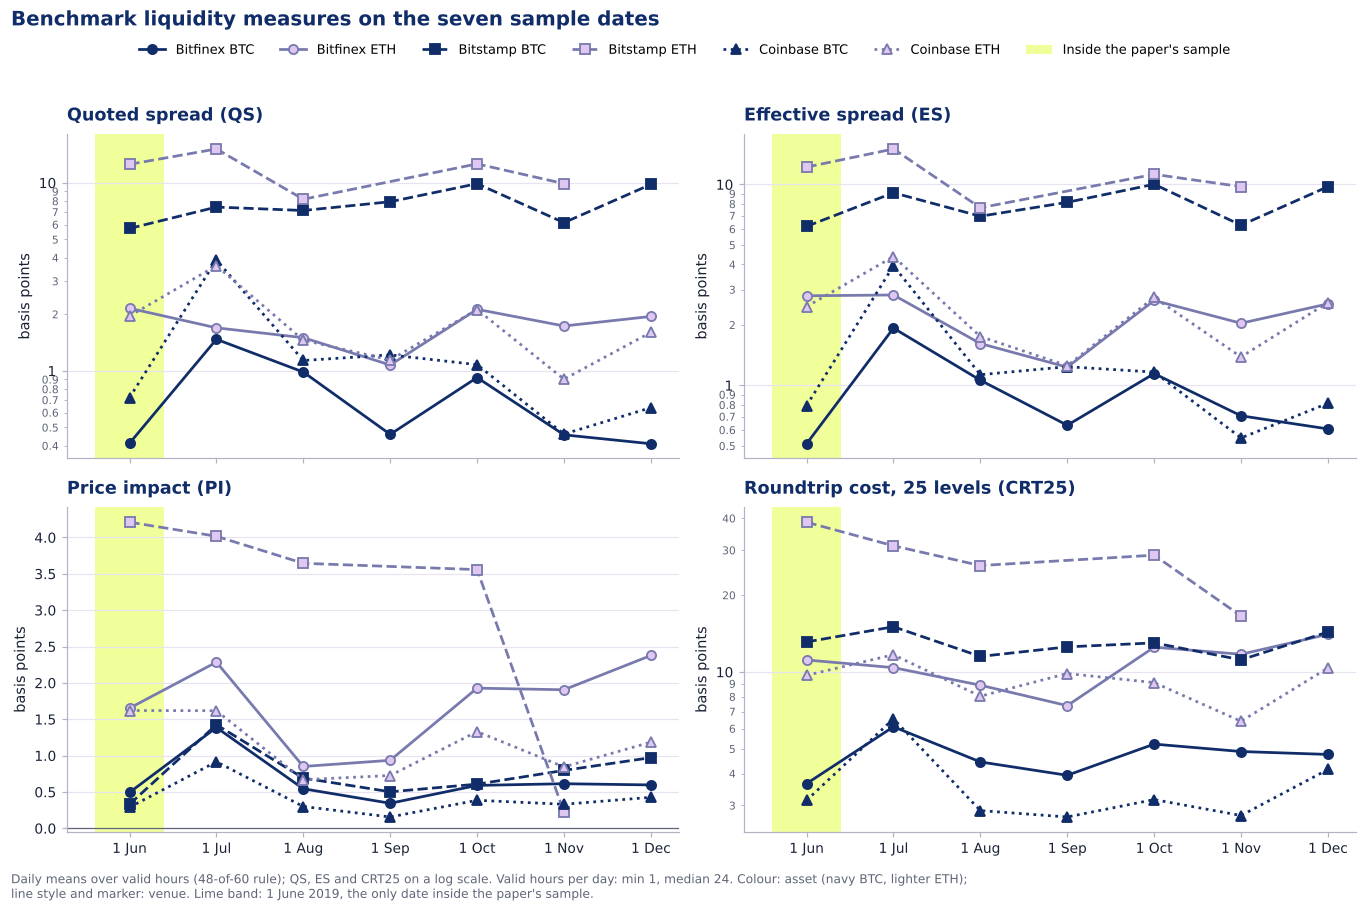

In [ ]:
import matplotlib
import matplotlib.patches
import matplotlib.ticker
import matplotlib.pyplot as plt

VENUE_STYLE = {"bitfinex": ("-", "o"), "bitstamp": ("--", "s"), "coinbase": (":", "^")}   # line style, marker
PAIR_COLOR = {"BTCUSD": NAVY, "ETHUSD": NAVY_MID}


def plot_benchmarks_by_date(bench, path):
    daily = bench[bench["passes_80pct_trade_coverage"].astype(bool)].groupby(["date_utc", "venue", "pair"])
    means = daily[["qs_bp", "es_bp", "pi_bp", "crt25_bp"]].mean()
    hours = daily["qs_bp"].count()
    titles = {"qs_bp": "Quoted spread (QS)", "es_bp": "Effective spread (ES)",
              "pi_bp": "Price impact (PI)", "crt25_bp": "Roundtrip cost, 25 levels (CRT25)"}
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 8), sharex=True)
    dates = sorted(bench["date_utc"].unique())
    x = {d: i for i, d in enumerate(dates)}
    for ax, col in zip(axes.flat, titles):
        ax.axvspan(-0.4, 0.4, color=LIME, alpha=0.4, lw=0, zorder=0)
        for venue, (ls, mk) in VENUE_STYLE.items():
            for pair, color in PAIR_COLOR.items():
                try:
                    s = means[col].xs((venue, pair), level=["venue", "pair"]).dropna()
                except KeyError:
                    continue
                if col != "pi_bp":
                    s = s[s > 0]
                ax.plot([x[d] for d in s.index], s.values, ls=ls, marker=mk, ms=6, lw=1.8, color=color,
                        markerfacecolor=color if pair == "BTCUSD" else LAVENDER, markeredgecolor=color,
                        markeredgewidth=1.2, label=f"{venue.capitalize()} {pair[:3]}", zorder=3)
        if col != "pi_bp":
            ax.set_yscale("log")
            fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}")
            ax.yaxis.set_major_formatter(fmt)
            ax.yaxis.set_minor_formatter(fmt)
            ax.tick_params(axis="y", which="minor", labelsize=7, labelcolor=MUTED)
        else:
            ax.axhline(0, color=MUTED, lw=0.8)
        ax.set_title(titles[col])
        ax.set_ylabel("basis points")
        ax.grid(axis="y")
    for ax in axes[1]:
        ax.set_xticks(range(len(dates)), [pd.Timestamp(d).strftime("%d %b").lstrip("0") for d in dates])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    handles.append(matplotlib.patches.Patch(color=LIME, alpha=0.4, lw=0))
    labels.append("Inside the paper's sample")
    fig.suptitle("Benchmark liquidity measures on the seven sample dates", x=0.01, ha="left", color=NAVY)
    fig.legend(handles, labels, ncol=7, loc="upper center", bbox_to_anchor=(0.5, 0.955), fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    add_note(fig, "Daily means over valid hours (48-of-60 rule); QS, ES and CRT25 on a log scale. Valid hours per "
                  f"day: min {int(hours.min())}, median {int(hours.median())}. Colour: asset (navy BTC, lighter ETH); "
                  "line style and marker: venue. Lime band: 1 June 2019, the only date inside the paper's sample.")
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches="tight")
    return fig


plot_benchmarks_by_date(bench, FIG_DIR / "participant3_benchmarks_by_date.png")
plt.show()

## 6. Empirical Results and Comparison with the Paper

This section compares our results with the paper's in the order of its evaluation: benchmark levels (Table 3), time-series correlations (Figure 1), level errors (Table 5) and venue rankings (Table 6). Our sample covers seven days of 2019 while the paper covers 18 months of 2017–2019 with different data, so agreement in rankings and signs is more informative than agreement in the exact size of coefficients.

### 6.1 Benchmark levels compared with Table 3 (Bitcoin) and Table 7 (Ethereum)

Our mean, median and minimum over valid hours next to the paper's mean and minimum. The paper's minima are included because the negative ES minima are what makes its ES column inconsistent with the printed absolute-value formula (Section 2.6).

In [ ]:
PAPER_TABLE3 = {
    ("BTCUSD", "bitfinex"): {"QS": (0.7233, 0.0469), "ES": (0.2633, -0.6484), "PI": (0.1594, -0.3884), "CRT": (3.720, 0.0800)},
    ("BTCUSD", "bitstamp"): {"QS": (6.588, 0.0607), "ES": (1.240, -0.1154), "PI": (0.1989, -0.3118), "CRT": (14.30, 0.2369)},
    ("BTCUSD", "coinbase"): {"QS": (0.3199, 0.0018), "ES": (0.2709, -2.336), "PI": (0.1710, -2.618), "CRT": (3.408, 0.0156)},
    ("ETHUSD", "bitfinex"): {"QS": (1.433, 0.0573), "ES": (0.3726, -0.8700), "PI": (0.2843, -0.9276), "CRT": (6.461, 0.1737)},
    ("ETHUSD", "bitstamp"): {"QS": (15.68, 2.329), "ES": (1.552, -0.1358), "PI": (0.5087, -0.3283), "CRT": (35.25, 9.498)},
    ("ETHUSD", "coinbase"): {"QS": (1.120, 0.0692), "ES": (0.4276, -5.637), "PI": (0.3476, -3.323), "CRT": (11.32, 0.3997)},
}
ours = {"QS": "qs_bp", "ES": "es_bp", "ES signed": "es_signed_bp", "PI": "pi_bp", "CRT": "crt25_bp"}
rows = []
for (pair, venue), paper in PAPER_TABLE3.items():
    g = bench[eligible & (bench["pair"] == pair) & (bench["venue"] == venue)]
    for name, col in ours.items():
        ref = paper.get("ES" if name == "ES signed" else name)
        rows.append({"pair": pair, "venue": venue, "benchmark": name, "hours": int(g[col].notna().sum()),
                     "our_mean": g[col].mean(), "our_median": g[col].median(), "our_min": g[col].min(),
                     "paper_mean": ref[0], "paper_min": ref[1]})
levels = pd.DataFrame(rows)
levels["ratio_ours_to_paper"] = levels["our_mean"] / levels["paper_mean"]
levels.to_csv(OUT / "participant3_levels_vs_ssrn_table3.csv", index=False)
with pd.option_context("display.float_format", "{:.3f}".format):
    print(levels.to_string(index=False))

  pair    venue benchmark  hours  our_mean  our_median  our_min  paper_mean  paper_min  ratio_ours_to_paper
BTCUSD bitfinex        QS    164     0.725       0.522    0.120       0.723      0.047                1.002
BTCUSD bitfinex        ES    164     0.939       0.771    0.127       0.263     -0.648                3.566
BTCUSD bitfinex ES signed    164     0.627       0.486    0.050       0.263     -0.648                2.380
BTCUSD bitfinex        PI    164     0.656       0.567    0.092       0.159     -0.388                4.114
BTCUSD bitfinex       CRT    164     4.718       4.847    1.140       3.720      0.080                1.268
BTCUSD bitstamp        QS    167     7.721       7.727    3.899       6.588      0.061                1.172
BTCUSD bitstamp        ES    167     8.062       8.211    4.231       1.240     -0.115                6.501
BTCUSD bitstamp ES signed    167     5.955       6.053   -0.116       1.240     -0.115                4.803
BTCUSD bitstamp        PI   

### 6.2 The analysis panel

All comparisons use the same panel: proxies from Section 4 and benchmarks from Section 5, joined one-to-one on `(date_utc, venue, pair, hour_utc)`, restricted to the 807 hours that pass the 48-of-60 rule. Duplicate or unmatched keys and inconsistent coverage flags stop the run; missing values are never replaced by zero. The four benchmarks are QS, absolute ES, signed PI and CRT25; signed ES is kept as a definition check.

Higher TX and \$Vol normally indicate *more* liquidity, so their expected correlation with costs is negative, while the other six proxies are oriented towards illiquidity. Correlation tables keep the raw signs; only the venue rankings in Section 6.6 reverse TX and \$Vol. All tables are also written to the `results` folder.

In [ ]:
from pathlib import Path
import hashlib
import json
import platform
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

data_dir = Path(OUT)
p4_results_dir = (
    Path(DRIVE_DATA_DIR) / "part4_results"
    if USE_GOOGLE_DRIVE and IN_COLAB
    else Path("results")
)
p4_figures_dir = p4_results_dir / "figures"
p4_figures_dir.mkdir(parents=True, exist_ok=True)

p4_seed = 20261016
p4_boot_repetitions = 999
p4_keys = ["date_utc", "venue", "pair", "hour_utc"]
p4_proxy_columns = [
    "tx_mean", "dollar_volume_mean", "amihud", "roll_return",
    "roll_price", "kyle", "cs", "ar"
]
p4_benchmark_columns = ["qs_bp", "es_bp", "pi_bp", "crt25_bp"]
benchmark_columns = p4_benchmark_columns + ["es_signed_bp"]

p4_proxies = pd.read_csv(data_dir / "hourly_proxies_local_only.csv")
p4_benchmarks = pd.read_csv(data_dir / "hourly_benchmarks_local_only.csv")
p4_hourly = pd.read_csv(data_dir / "hourly_local_only.csv")

for name, frame in [
    ("proxies", p4_proxies), ("benchmarks", p4_benchmarks),
    ("hourly coverage", p4_hourly)
]:
    assert len(frame) == 1008, name
    assert not frame[p4_keys].isna().any().any(), name
    assert not frame.duplicated(p4_keys).any(), name

flag_check = p4_proxies[p4_keys + ["passes_80pct_trade_coverage"]].merge(
    p4_benchmarks[p4_keys + ["passes_80pct_trade_coverage"]],
    on=p4_keys, how="outer", validate="one_to_one", indicator=True
)
assert flag_check["_merge"].eq("both").all()
assert flag_check["passes_80pct_trade_coverage_x"].equals(
    flag_check["passes_80pct_trade_coverage_y"]
)
assert p4_proxies["passes_80pct_trade_coverage"].equals(
    p4_proxies["valid_trade_minutes"].ge(48)
)

p4_data = p4_proxies.merge(
    p4_benchmarks[p4_keys + benchmark_columns],
    on=p4_keys, how="outer", validate="one_to_one", indicator=True
)
assert p4_data["_merge"].eq("both").all()
p4_data = p4_data.drop(columns="_merge")
p4_valid = p4_data.loc[p4_data["passes_80pct_trade_coverage"]].copy()
assert len(p4_valid) == 807
assert np.isfinite(
    p4_valid[p4_proxy_columns + p4_benchmark_columns + ["vol_bp", "mean_ret_bp"]]
).all().all()

p4_counts = p4_valid.groupby(["pair", "venue"]).size().unstack("venue")
p4_counts.to_csv(p4_results_dir / "valid_hours_by_market.csv")
print("Matched hourly keys:", len(p4_data))
print("Eligible hours:", len(p4_valid))
print("Excluded hours:", len(p4_data) - len(p4_valid))
print("Output directory:", p4_results_dir)
display(p4_counts)

Matched hourly keys: 1008
Eligible hours: 807
Excluded hours: 201
Output directory: results


venue,bitfinex,bitstamp,coinbase
pair,,,
BTCUSD,164,167,163
ETHUSD,122,28,163


### 6.3 Time-series correlations: the paper's Figure 1 and our sample

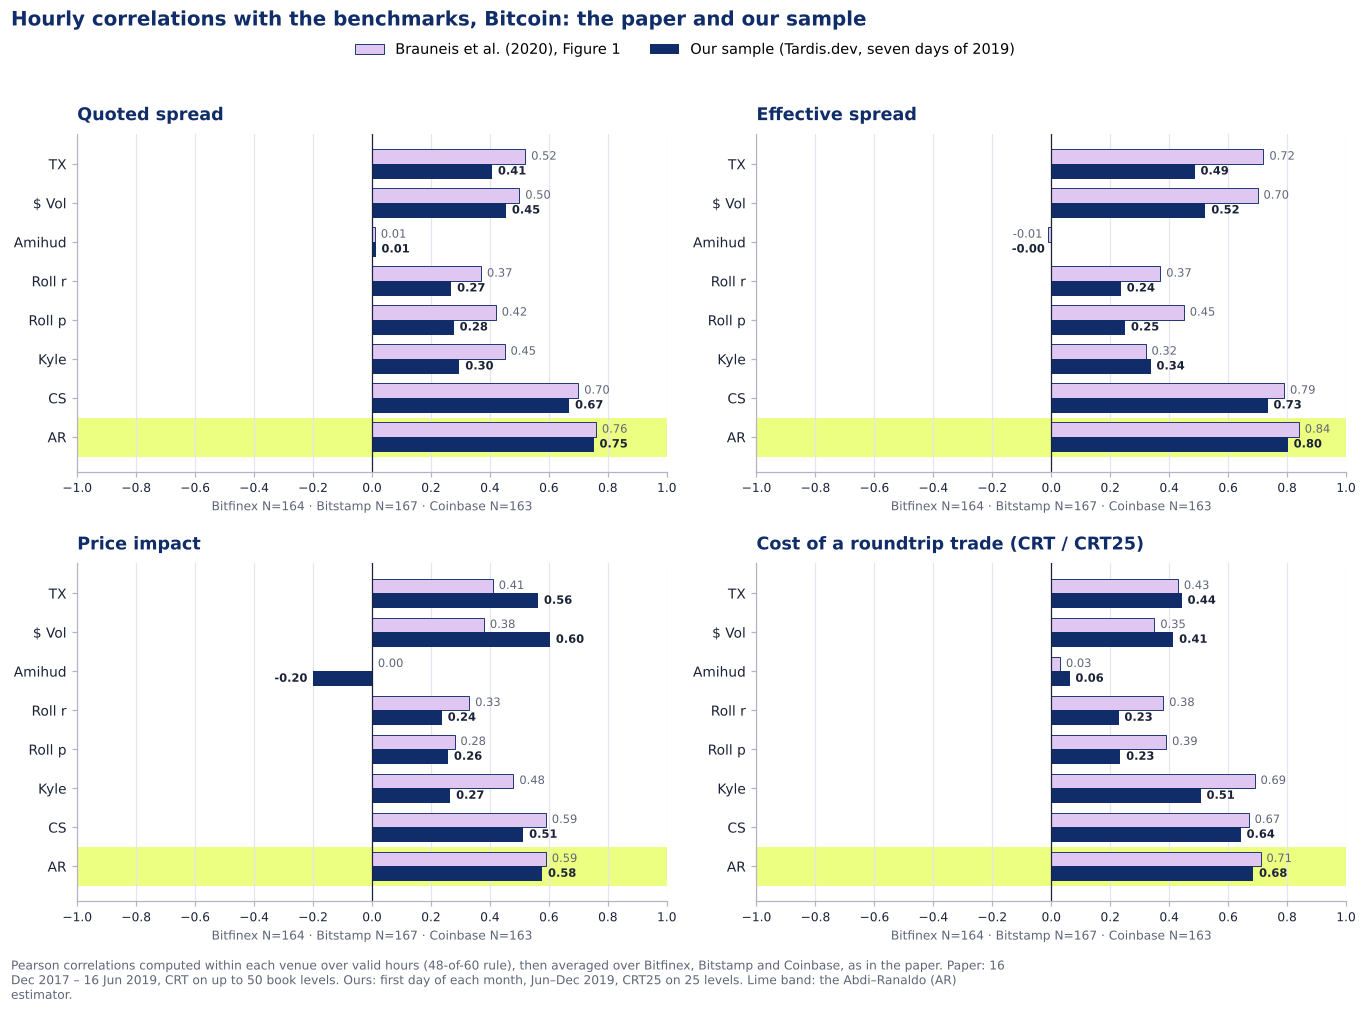

benchmark  crt25_bp  es_bp  es_signed_bp  pi_bp  qs_bp
proxy                                                 
TX             0.44   0.49          0.34   0.56   0.41
$ Vol          0.41   0.52          0.39   0.60   0.45
Amihud         0.06  -0.00          0.03  -0.20   0.01
Roll r         0.23   0.24          0.25   0.24   0.27
Roll p         0.23   0.25          0.26   0.26   0.28
Kyle           0.51   0.34          0.29   0.27   0.30
CS             0.64   0.73          0.57   0.51   0.67
AR             0.68   0.80          0.65   0.58   0.75


In [ ]:
AUTHORS_FIG1_BTC = {  # Figure 1 of the SSRN version, BTC, hourly, mean across the three venues
    "QS":  [0.52, 0.50, 0.01, 0.37, 0.42, 0.45, 0.70, 0.76],
    "ES":  [0.72, 0.70, -0.01, 0.37, 0.45, 0.32, 0.79, 0.84],
    "PI":  [0.41, 0.38, 0.00, 0.33, 0.28, 0.48, 0.59, 0.59],
    "CRT": [0.43, 0.35, 0.03, 0.38, 0.39, 0.69, 0.67, 0.71],
}
PROXY_LABELS = ["TX", "$ Vol", "Amihud", "Roll r", "Roll p", "Kyle", "CS", "AR"]
PROXY_COLS = ["tx_mean", "dollar_volume_mean", "amihud", "roll_return", "roll_price", "kyle", "cs", "ar"]
FIG_BENCH = {"QS": "qs_bp", "ES": "es_bp", "PI": "pi_bp", "CRT": "crt25_bp"}
PANEL_TITLE = {"QS": "Quoted spread", "ES": "Effective spread", "PI": "Price impact", "CRT": "Cost of a roundtrip trade (CRT / CRT25)"}


def proxy_benchmark_correlations(proxies, bench, pair="BTCUSD",
                                 bench_cols=("qs_bp", "es_bp", "es_signed_bp", "pi_bp", "crt25_bp")):
    """Pearson and Spearman correlations per venue over valid hours, plus the mean across venues."""
    data = proxies.merge(bench[P3_KEYS + [c for c in bench_cols if c in bench]], on=P3_KEYS,
                         how="inner", validate="one_to_one")
    data = data[data["passes_80pct_trade_coverage"].astype(bool) & (data["pair"] == pair)]
    rows = []
    for venue, g in data.groupby("venue"):
        for b in bench_cols:
            if b not in g or g[b].notna().sum() < 3:
                continue
            for label, p in zip(PROXY_LABELS, PROXY_COLS):
                ok = g[p].notna() & g[b].notna()
                rows.append({"pair": pair, "venue": venue, "benchmark": b, "proxy": label, "n_hours": int(ok.sum()),
                             "pearson": g.loc[ok, p].corr(g.loc[ok, b]),
                             "spearman": g.loc[ok, p].corr(g.loc[ok, b], method="spearman")})
    per_venue = pd.DataFrame(rows)
    if per_venue.empty:
        return per_venue, per_venue
    mean = (per_venue.groupby(["benchmark", "proxy"], sort=False)
            .agg(pearson=("pearson", "mean"), spearman=("spearman", "mean"), n_venues=("venue", "nunique"),
                 n_hours_total=("n_hours", "sum")).reset_index())
    return per_venue, mean


def plot_authors_vs_ours(per_venue, mean, path, note=""):
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.8), sharex=True)
    y = np.arange(len(PROXY_LABELS))[::-1]
    h = 0.38
    for ax, (key, col) in zip(axes.flat, FIG_BENCH.items()):
        highlight_row(ax, y[PROXY_LABELS.index("AR")], 0.5)
        auth = np.array(AUTHORS_FIG1_BTC[key])
        ax.barh(y + h / 2, auth, height=h, color=LAVENDER, edgecolor=NAVY, linewidth=0.6,
                label="Brauneis et al. (2020), Figure 1", zorder=2)
        sub = mean[mean["benchmark"] == col].set_index("proxy") if len(mean) else pd.DataFrame()
        have = len(sub) == len(PROXY_LABELS)
        for yi, v in zip(y, auth):
            ax.text(v + (0.02 if v >= 0 else -0.02), yi + h / 2, f"{v:.2f}", va="center",
                    ha="left" if v >= 0 else "right", fontsize=7.5, color=MUTED)
        if have:
            ours_r = sub.loc[PROXY_LABELS, "pearson"].to_numpy()
            ax.barh(y - h / 2, ours_r, height=h, color=NAVY, label="Our sample (Tardis.dev, seven days of 2019)",
                    zorder=2)
            for yi, v in zip(y, ours_r):
                ax.text(v + (0.02 if v >= 0 else -0.02), yi - h / 2, f"{v:.2f}", va="center",
                        ha="left" if v >= 0 else "right", fontsize=7.5, color=INK, fontweight="bold")
            pv = per_venue[(per_venue["benchmark"] == col) & (per_venue["proxy"] == "AR")]
            n_txt = " · ".join(f"{v.capitalize()} N={n}" for v, n in zip(pv["venue"], pv["n_hours"]))
        else:
            n_txt = "our values: not computed yet (run Section 5 on the raw files)"
        ax.set_title(PANEL_TITLE[key])
        ax.set_xlabel(n_txt, fontsize=8, color=MUTED, labelpad=4)
        ax.set_xlim(-1, 1)
        ax.set_xticks(np.arange(-1, 1.01, 0.2))
        ax.tick_params(axis="x", labelsize=8, labelbottom=True)
        ax.set_yticks(y, PROXY_LABELS, fontsize=9)
        ax.axvline(0, color=INK, lw=0.8)
        ax.grid(axis="x")
    handles, labels = [], []
    for ax in axes.flat:
        for hd, lb in zip(*ax.get_legend_handles_labels()):
            if lb not in labels:
                handles.append(hd); labels.append(lb)
    fig.suptitle("Hourly correlations with the benchmarks, Bitcoin: the paper and our sample",
                 x=0.01, ha="left", color=NAVY)
    fig.legend(handles, labels, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 0.96), fontsize=9.5)
    fig.tight_layout(rect=(0, 0, 1, 0.935), h_pad=1.5)
    add_note(fig, "Pearson correlations computed within each venue over valid hours (48-of-60 rule), then averaged "
                  "over Bitfinex, Bitstamp and Coinbase, as in the paper. Paper: 16 Dec 2017 – 16 Jun 2019, CRT on up "
                  "to 50 book levels. Ours: first day of each month, Jun–Dec 2019, CRT25 on 25 levels. Lime band: "
                  "the Abdi–Ranaldo (AR) estimator." + (" " + note if note else ""))
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches="tight")
    return fig


proxies = pd.read_csv(OUT / "hourly_proxies_local_only.csv", dtype={k: str for k in P3_KEYS})
corr_venue, corr_mean = proxy_benchmark_correlations(proxies, bench, "BTCUSD")
corr_venue_eth, corr_mean_eth = proxy_benchmark_correlations(proxies, bench, "ETHUSD")
pd.concat([corr_venue, corr_venue_eth]).to_csv(OUT / "participant3_correlations_by_venue.csv", index=False)
pd.concat([corr_mean.assign(pair="BTCUSD"), corr_mean_eth.assign(pair="ETHUSD")]).to_csv(
    OUT / "participant3_correlations_mean_across_venues.csv", index=False)
plot_authors_vs_ours(corr_venue, corr_mean, FIG_DIR / "participant3_authors_vs_ours.png")
plt.show()
print(corr_mean.pivot(index="proxy", columns="benchmark", values="pearson").loc[PROXY_LABELS].round(2))

The next cell states the main facts of Sections 5 and 6 as sentences generated directly from the computed tables, so the text always matches the current run.

In [ ]:
def summary_lines():
    lines = []
    lines.append(f"QS reproduces the Section 3 quoted spread (analysis_qs_bp) in all {int(eligible.sum())} valid hours; the grid-weighted "
                 f"alternative differs by at most {gap.abs().max():.3f} bp.")
    for col, label in (("es_bp", "ES"), ("pi_bp", "PI"), ("crt25_bp", "CRT25")):
        lines.append(f"{label}: values in {int(bench.loc[eligible, col].notna().sum())} of {int(eligible.sum())} valid hours.")
    neg = bench.loc[eligible, "es_signed_bp"].lt(0).sum()
    lines.append(f"Signed ES is negative in {int(neg)} valid hours; absolute ES is never negative by construction.")
    lines.append(f"25 levels fill the target size in {tot['n_crt_filled'] / tot['n_book_top_valid']:.2%} of book snapshots.")
    for b, key in FIG_BENCH.items():
        sub = corr_mean[corr_mean["benchmark"] == key].set_index("proxy")["pearson"]
        if len(sub) == 8:
            top = sub.sort_values(ascending=False).index[:2].tolist()
            auth_top = pd.Series(AUTHORS_FIG1_BTC[b], index=PROXY_LABELS).sort_values(ascending=False).index[:2].tolist()
            lines.append(f"BTC {b}: our two highest mean correlations: {top[0]} ({sub[top[0]]:.2f}), {top[1]} "
                         f"({sub[top[1]]:.2f}); authors: {auth_top[0]}, {auth_top[1]}. "
                         f"AR rank {int(sub.rank(ascending=False)['AR'])} of 8, Amihud {sub['Amihud']:.2f}, "
                         f"TX {sub['TX']:.2f}.")
    return lines


for line in summary_lines():
    print("-", line)

- QS reproduces the Section 3 quoted spread (analysis_qs_bp) in all 807 valid hours; the grid-weighted alternative differs by at most 0.118 bp.
- ES: values in 807 of 807 valid hours.
- PI: values in 807 of 807 valid hours.
- CRT25: values in 807 of 807 valid hours.
- Signed ES is negative in 3 valid hours; absolute ES is never negative by construction.
- 25 levels fill the target size in 99.85% of book snapshots.
- BTC QS: our two highest mean correlations: AR (0.75), CS (0.67); authors: AR, CS. AR rank 1 of 8, Amihud 0.01, TX 0.41.
- BTC ES: our two highest mean correlations: AR (0.80), CS (0.73); authors: AR, CS. AR rank 1 of 8, Amihud -0.00, TX 0.49.
- BTC PI: our two highest mean correlations: $ Vol (0.60), AR (0.58); authors: CS, AR. AR rank 2 of 8, Amihud -0.20, TX 0.56.
- BTC CRT: our two highest mean correlations: AR (0.68), CS (0.64); authors: AR, Kyle. AR rank 1 of 8, Amihud 0.06, TX 0.44.


### 6.4 Mean correlations for both assets

The next cell computes Pearson and Spearman correlations for all 8 proxies × 4 benchmarks × 6 markets (192 coefficients each) and averages them over the three venues per asset. An average is reported only if all three venue coefficients are defined. This is an average of within-venue coefficients, not a pooled correlation.

In [ ]:
p4_benchmark_columns = [
    "qs_bp",
    "es_bp",
    "pi_bp",
    "crt25_bp"
]

p4_corr_rows = []

for (venue, pair), market in p4_valid.groupby(["venue", "pair"]):
    for benchmark in p4_benchmark_columns:
        for proxy in p4_proxy_columns:

            sample = market[
                [proxy, benchmark, "date_utc"]
            ].dropna()

            p4_corr_rows.append({
                "venue": venue,
                "pair": pair,
                "benchmark": benchmark,
                "proxy": proxy,
                "n_hours": len(sample),
                "n_dates": sample["date_utc"].nunique(),
                "pearson": sample[proxy].corr(sample[benchmark]),
                "spearman": sample[proxy].corr(
                    sample[benchmark],
                    method="spearman"
                )
            })

p4_correlations = pd.DataFrame(p4_corr_rows)

p4_mean_correlations = (
    p4_correlations.groupby(["pair", "benchmark", "proxy"], as_index=False)
    .agg(
        pearson=("pearson", "mean"), spearman=("spearman", "mean"),
        n_venues=("venue", "nunique"),
        n_venues_pearson=("pearson", "count"),
        n_venues_spearman=("spearman", "count"),
        n_hours_total=("n_hours", "sum")
    )
)
assert p4_mean_correlations["n_venues"].eq(3).all()
for metric in ["pearson", "spearman"]:
    p4_mean_correlations.loc[
        p4_mean_correlations["n_venues_" + metric] < 3, metric
    ] = np.nan

p4_correlations.to_csv(p4_results_dir / "correlations_by_market.csv", index=False)
p4_mean_correlations.to_csv(
    p4_results_dir / "correlations_mean_across_venues.csv", index=False
)
assert len(p4_correlations) == 192

for pair in ["BTCUSD", "ETHUSD"]:
    print(f"\n{pair}: mean Pearson correlations across three venues")
    table = p4_mean_correlations.loc[p4_mean_correlations["pair"].eq(pair)].pivot(
        index="proxy", columns="benchmark", values="pearson"
    ).reindex(index=p4_proxy_columns, columns=p4_benchmark_columns)
    display(table.round(3))


BTCUSD: mean Pearson correlations across three venues


benchmark,qs_bp,es_bp,pi_bp,crt25_bp
proxy,,,,
tx_mean,0.407,0.486,0.563,0.442
dollar_volume_mean,0.455,0.523,0.604,0.414
amihud,0.012,-0.002,-0.199,0.062
roll_return,0.269,0.236,0.237,0.228
roll_price,0.277,0.250,0.258,0.234
kyle,0.297,0.337,0.265,0.507
cs,0.669,0.734,0.513,0.643
ar,0.752,0.802,0.577,0.685



ETHUSD: mean Pearson correlations across three venues


benchmark,qs_bp,es_bp,pi_bp,crt25_bp
proxy,,,,
tx_mean,0.461,0.538,0.433,0.294
dollar_volume_mean,0.411,0.502,0.395,0.217
amihud,0.107,0.089,-0.021,0.167
roll_return,0.319,0.381,0.197,0.257
roll_price,0.361,0.426,0.211,0.270
kyle,0.269,0.290,0.285,0.400
cs,0.547,0.671,0.465,0.366
ar,0.632,0.772,0.573,0.462


The heatmap places the authors' Bitcoin results next to ours for Bitcoin and Ethereum on a common colour scale.

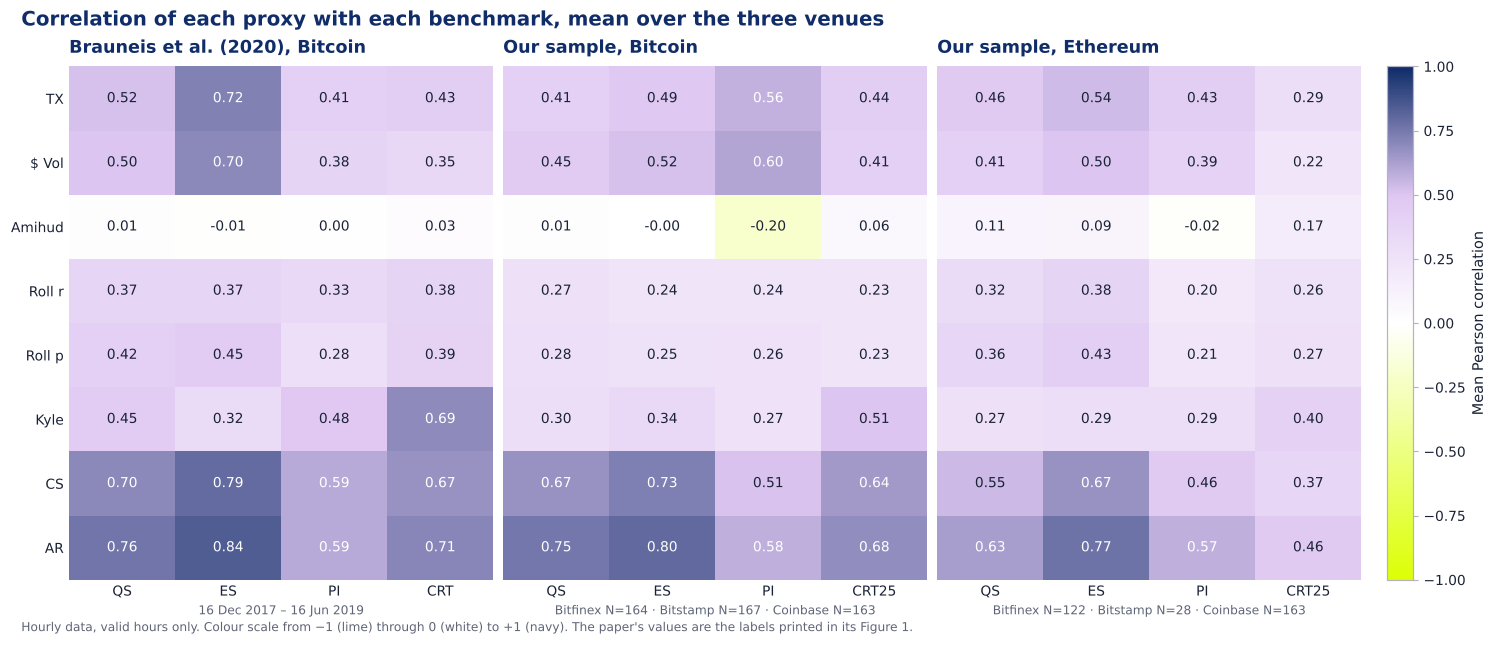

Bitcoin, 32 coefficients: correlation between the paper's and our values 0.90; mean absolute difference 0.097; mean difference (ours − paper) -0.065; ours lower in 24 of 32.
Spearman correlation between our and the paper's ordering of the eight proxies: {'QS': 0.98, 'ES': 0.9, 'PI': 0.65, 'CRT': 0.9}


In [ ]:
panels = [("Brauneis et al. (2020), Bitcoin",
           np.array([AUTHORS_FIG1_BTC[k] for k in ["QS", "ES", "PI", "CRT"]]).T,
           "16 Dec 2017 – 16 Jun 2019")]
for pair, name in [("BTCUSD", "Bitcoin"), ("ETHUSD", "Ethereum")]:
    table = (p4_mean_correlations.loc[p4_mean_correlations["pair"].eq(pair)]
             .pivot(index="proxy", columns="benchmark", values="pearson")
             .reindex(index=p4_proxy_columns, columns=p4_benchmark_columns))
    n_hours = (p4_correlations.loc[p4_correlations["pair"].eq(pair) & p4_correlations["proxy"].eq("ar")
                                   & p4_correlations["benchmark"].eq("qs_bp")].set_index("venue")["n_hours"])
    panels.append((f"Our sample, {name}", table.to_numpy(),
                   " · ".join(f"{v.capitalize()} N={n}" for v, n in n_hours.items())))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 5.6), sharey=True, layout="constrained")
for ax, (title, values, caption) in zip(axes, panels):
    image = ax.imshow(values, cmap=CORR_CMAP, vmin=-1, vmax=1, aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if values[i, j] > 0.55 else INK)
    ax.set_xticks(range(4), ["QS", "ES", "PI", "CRT" if title.startswith("Brauneis") else "CRT25"])
    ax.set_yticks(range(len(PROXY_LABELS)), PROXY_LABELS)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title)
    ax.set_xlabel(caption, fontsize=8, color=MUTED)
fig.colorbar(image, ax=axes, fraction=0.025, pad=0.02, label="Mean Pearson correlation")
fig.suptitle("Correlation of each proxy with each benchmark, mean over the three venues",
             x=0.01, ha="left", color=NAVY)
add_note(fig, "Hourly data, valid hours only. Colour scale from −1 (lime) through 0 (white) to +1 (navy). "
              "The paper's values are the labels printed in its Figure 1.")
fig.savefig(p4_figures_dir / "correlation_matrices_paper_vs_ours.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

authors_btc, ours_btc = panels[0][1], panels[1][1]
gap_btc = ours_btc - authors_btc
print(f"Bitcoin, 32 coefficients: correlation between the paper's and our values "
      f"{np.corrcoef(ours_btc.ravel(), authors_btc.ravel())[0, 1]:.2f}; mean absolute difference "
      f"{np.abs(gap_btc).mean():.3f}; mean difference (ours − paper) {gap_btc.mean():.3f}; "
      f"ours lower in {(gap_btc < 0).sum()} of 32.")
print("Spearman correlation between our and the paper's ordering of the eight proxies:",
      {b: round(float(pd.Series(ours_btc[:, j]).corr(pd.Series(authors_btc[:, j]), method="spearman")), 2)
       for j, b in enumerate(["QS", "ES", "PI", "CRT"])})

For Ethereum, AR has the highest mean correlation with **all four** benchmarks (0.632 with QS, 0.772 with ES, 0.573 with PI and 0.462 with CRT25), in line with the paper's statement that its Ethereum results are qualitatively the same. The Ethereum averages include Bitstamp ETH with only 28 hours, so the market-level tables remain the reference. Negative mean correlations are rare and small; the most negative is Amihud with PI for Bitcoin (−0.199).

### 6.5 Level accuracy: errors in basis points


In [ ]:
def p4_errors(actual, prediction):
    error = np.asarray(prediction) - np.asarray(actual)

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))

    return mae, rmse


p4_direct_specs = {
    "amihud_x10000": ("amihud", 10000),
    "roll_return": ("roll_return", 1),
    "kyle_x10000": ("kyle", 10000),
    "cs": ("cs", 1),
    "ar": ("ar", 1)
}

p4_level_rows = []

for (venue, pair), market in p4_valid.groupby(["venue", "pair"]):
    for benchmark in p4_benchmark_columns:

        sample = market[
            [benchmark, "date_utc"]
            + [spec[0] for spec in p4_direct_specs.values()]
        ].dropna()

        predictions = {
            "zero": np.zeros(len(sample))
        }

        for method, (column, multiplier) in p4_direct_specs.items():
            predictions[method] = (
                sample[column].to_numpy() * multiplier
            )

        for method, prediction in predictions.items():
            mae, rmse = p4_errors(
                sample[benchmark],
                prediction
            )

            p4_level_rows.append({
                "venue": venue,
                "pair": pair,
                "benchmark": benchmark,
                "method": method,
                "n_hours": len(sample),
                "n_dates": sample["date_utc"].nunique(),
                "mae_bp": mae,
                "rmse_bp": rmse
            })

p4_level_errors = pd.DataFrame(p4_level_rows)

p4_level_errors.to_csv(
    p4_results_dir / "direct_level_errors.csv",
    index=False
)

p4_level_means = p4_level_errors.groupby(
    ["pair", "benchmark", "method"], as_index=False
).agg(
    mae_bp=("mae_bp", "mean"), rmse_bp=("rmse_bp", "mean"),
    n_venues=("venue", "nunique"), n_hours_total=("n_hours", "sum")
)
p4_level_means.to_csv(
    p4_results_dir / "direct_level_errors_mean_across_venues.csv", index=False
)
assert len(p4_level_errors) == 144
print("Direct level-error comparisons:", len(p4_level_errors))
print("BTC: mean MAE across three venues, in basis points")
display(p4_level_means.loc[p4_level_means["pair"].eq("BTCUSD")].pivot(
    index="method", columns="benchmark", values="mae_bp"
).reindex(columns=p4_benchmark_columns).round(3))

Direct level-error comparisons: 144
BTC: mean MAE across three venues, in basis points


benchmark,qs_bp,es_bp,pi_bp,crt25_bp
method,,,,
amihud_x10000,3.250,3.459,0.609,7.104
ar,1.608,1.520,3.312,3.442
cs,1.710,1.761,1.850,4.742
kyle_x10000,2.739,2.883,0.334,6.440
roll_return,2.912,2.957,4.178,4.308
zero,3.252,3.461,0.611,7.106


The figure compares our mean MAE across venues for Bitcoin with the paper's Table 5. The paper reports errors multiplied by 1,000; we multiply the printed values by 10 to express them in basis points (Section 2.6). The dotted line is the average of the paper's Table 3 benchmark means over the three venues. For non-negative benchmarks (QS, CRT) this equals the MAE of always predicting zero in the paper's sample; for ES and PI, which can be negative, it is a lower bound.

Bitcoin: MAE in basis points, our sample vs. the paper (Table 5 x 10; zero row: Table 3 mean level)


QS           ES           PI        CRT25       
                 ours  paper  ours  paper  ours  paper  ours  paper
Amihud ×10⁴      3.25   2.58  3.46   0.63  0.61   0.21  7.10   7.17
Roll r           2.91   3.56  2.96   4.46  4.18   4.64  4.31   5.04
Kyle ×10⁴        2.74   2.25  2.88   0.57  0.33   0.45  6.44   6.53
CS               1.71  13.88  1.76  15.80  1.85  16.21  4.74  10.33
AR               1.61  10.74  1.52  12.62  3.31  13.03  3.44   7.62
zero prediction  3.25   2.54  3.46   0.59  0.61   0.18  7.11   7.14

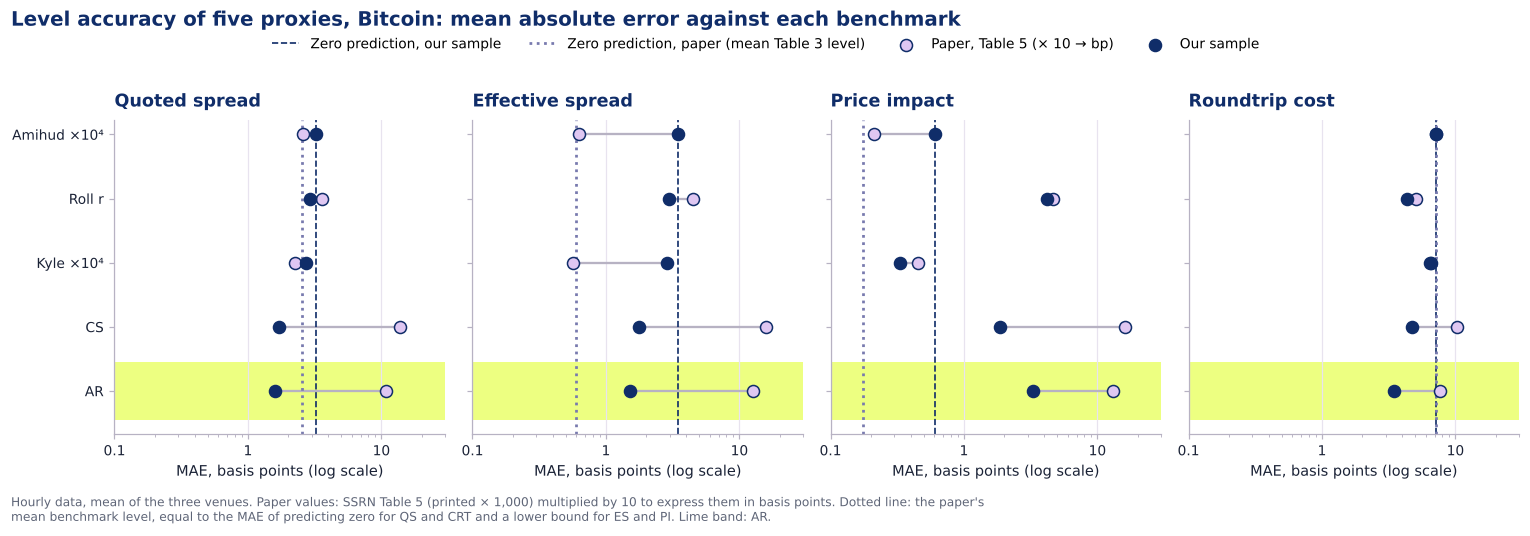

In [ ]:
PAPER_TABLE5_MAE_HOURLY = {
    "amihud_x10000": {"qs_bp": .258, "es_bp": .063, "pi_bp": .021, "crt25_bp": .717},
    "roll_return": {"qs_bp": .356, "es_bp": .446, "pi_bp": .464, "crt25_bp": .504},
    "kyle_x10000": {"qs_bp": .225, "es_bp": .057, "pi_bp": .045, "crt25_bp": .653},
    "cs": {"qs_bp": 1.388, "es_bp": 1.580, "pi_bp": 1.621, "crt25_bp": 1.033},
    "ar": {"qs_bp": 1.074, "es_bp": 1.262, "pi_bp": 1.303, "crt25_bp": .762},
}
level_methods = ["amihud_x10000", "roll_return", "kyle_x10000", "cs", "ar"]
level_labels = {"amihud_x10000": "Amihud ×10⁴", "roll_return": "Roll r", "kyle_x10000": "Kyle ×10⁴",
                "cs": "CS", "ar": "AR", "zero": "zero prediction"}
short_names = dict(zip(p4_benchmark_columns, ["QS", "ES", "PI", "CRT25"]))

paper_mae_bp = pd.DataFrame(PAPER_TABLE5_MAE_HOURLY).T.reindex(index=level_methods,
                                                                columns=p4_benchmark_columns) * 10
paper_zero_bp = pd.Series({b: np.mean([PAPER_TABLE3[("BTCUSD", v)][k][0] for v in ("bitfinex", "bitstamp", "coinbase")])
                           for b, k in zip(p4_benchmark_columns, ["QS", "ES", "PI", "CRT"])})
our_mae_bp = (p4_level_means.loc[p4_level_means["pair"].eq("BTCUSD")]
              .pivot(index="method", columns="benchmark", values="mae_bp")
              .reindex(columns=p4_benchmark_columns))

level_comparison = pd.DataFrame({
    (short_names[b], source): ([our_mae_bp.loc[m, b] for m in level_methods + ["zero"]] if source == "ours"
                               else list(paper_mae_bp[b]) + [paper_zero_bp[b]])
    for b in p4_benchmark_columns for source in ("ours", "paper")
}, index=[level_labels[m] for m in level_methods + ["zero"]])
print("Bitcoin: MAE in basis points, our sample vs. the paper (Table 5 x 10; zero row: Table 3 mean level)")
display(level_comparison.round(2))

fig, axes = plt.subplots(1, 4, figsize=(14, 4.5), sharey=True)
ypos = np.arange(len(level_methods))[::-1]
for ax, b, title in zip(axes, p4_benchmark_columns,
                        ["Quoted spread", "Effective spread", "Price impact", "Roundtrip cost"]):
    highlight_row(ax, ypos[level_methods.index("ar")])
    ours_v = our_mae_bp.loc[level_methods, b].to_numpy()
    paper_v = paper_mae_bp[b].to_numpy()
    ax.hlines(ypos, np.minimum(ours_v, paper_v), np.maximum(ours_v, paper_v), color=NEUTRAL, lw=1.5, zorder=1)
    ax.axvline(our_mae_bp.loc["zero", b], color=NAVY, ls="--", lw=1.1, label="Zero prediction, our sample")
    ax.axvline(paper_zero_bp[b], color=NAVY_MID, ls=":", lw=1.8,
               label="Zero prediction, paper (mean Table 3 level)")
    ax.scatter(paper_v, ypos, s=62, color=LAVENDER, edgecolor=NAVY, linewidth=1, zorder=3,
               label="Paper, Table 5 (× 10 → bp)")
    ax.scatter(ours_v, ypos, s=62, color=NAVY, zorder=4, label="Our sample")
    ax.set_xscale("log")
    ax.set_xlim(0.1, 30)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_title(title)
    ax.set_xlabel("MAE, basis points (log scale)")
    ax.grid(axis="x")
axes[0].set_yticks(ypos, [level_labels[m] for m in level_methods])
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Level accuracy of five proxies, Bitcoin: mean absolute error against each benchmark",
             x=0.01, ha="left", color=NAVY)
fig.legend(handles, labels, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 0.95))
fig.tight_layout(rect=(0, 0, 1, 0.92))
add_note(fig, "Hourly data, mean of the three venues. Paper values: SSRN Table 5 (printed × 1,000) multiplied by 10 "
              "to express them in basis points. Dotted line: the paper's mean benchmark level, equal to the MAE of "
              "predicting zero for QS and CRT and a lower bound for ES and PI. Lime band: AR.")
fig.savefig(p4_figures_dir / "level_errors_paper_vs_ours.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

### 6.6 Cross-sectional agreement: venue rankings

In [ ]:
p4_venues = ["bitfinex", "bitstamp", "coinbase"]
p4_rank_rows = []

for (pair, hour), hour_data in p4_valid.groupby(
    ["pair", "hour_utc"]
):
    if set(hour_data["venue"]) != set(p4_venues):
        continue

    market = hour_data.set_index("venue").loc[p4_venues]

    for benchmark in p4_benchmark_columns:
        for proxy in p4_proxy_columns:
            x = market[proxy].to_numpy()
            y = market[benchmark].to_numpy()

            if not (
                np.isfinite(x).all()
                and np.isfinite(y).all()
            ):
                continue

            if proxy in ["tx_mean", "dollar_volume_mean"]:
                x = -x

            tied = (
                len(np.unique(x)) < 3
                or len(np.unique(y)) < 3
            )

            match = (
                np.nan if tied
                else float(
                    np.array_equal(
                        np.argsort(x),
                        np.argsort(y)
                    )
                )
            )

            p4_rank_rows.append({
                "pair": pair,
                "hour_utc": hour,
                "benchmark": benchmark,
                "proxy": proxy,
                "tied": tied,
                "match": match
            })

p4_rank_details = pd.DataFrame(p4_rank_rows)

p4_rankings = (
    p4_rank_details
    .groupby(["pair", "benchmark", "proxy"], as_index=False)
    .agg(
        n_common_hours=("hour_utc", "size"),
        n_tied_hours=("tied", "sum"),
        n_hours=("match", "count"),
        matching_hours=("match", "sum"),
        match_share=("match", "mean")
    )
)

p4_rankings["match_percent"] = (
    100 * p4_rankings["match_share"]
)

p4_rankings.to_csv(
    p4_results_dir / "venue_rankings.csv",
    index=False
)

for pair in ["BTCUSD", "ETHUSD"]:
    print(f"\n{pair}: exact agreement with the QS venue ranking")

    display(
        p4_rankings.loc[
            (p4_rankings["pair"] == pair)
            & (p4_rankings["benchmark"] == "qs_bp")
        ].set_index("proxy").reindex(p4_proxy_columns)[
            [
                "n_common_hours",
                "n_tied_hours",
                "n_hours",
                "match_percent"
            ]
        ].round(1)
    )

p4_rank_details.to_csv(
    p4_results_dir / "venue_rankings_hourly_local_only.csv", index=False
)
p4_rank_daily = p4_rank_details.assign(
    date_utc=p4_rank_details["hour_utc"].str[:10]
).groupby(["pair", "benchmark", "proxy", "date_utc"], as_index=False).agg(
    n_common_hours=("hour_utc", "size"), n_hours=("match", "count"),
    n_tied_hours=("tied", "sum"), match_share=("match", "mean")
)
p4_rank_daily.to_csv(p4_results_dir / "venue_rankings_by_date.csv", index=False)
assert (p4_rankings["n_hours"] + p4_rankings["n_tied_hours"] == p4_rankings["n_common_hours"]).all()


BTCUSD: exact agreement with the QS venue ranking


,n_common_hours,n_tied_hours,n_hours,match_percent
proxy,,,,
tx_mean,158,0,158,27.2
dollar_volume_mean,158,0,158,11.4
amihud,158,0,158,25.3
roll_return,158,61,97,47.4
roll_price,158,61,97,48.5
kyle,158,0,158,24.1
cs,158,0,158,63.9
ar,158,0,158,75.9



ETHUSD: exact agreement with the QS venue ranking


,n_common_hours,n_tied_hours,n_hours,match_percent
proxy,,,,
tx_mean,26,0,26,26.9
dollar_volume_mean,26,0,26,23.1
amihud,26,0,26,3.8
roll_return,26,10,16,31.2
roll_price,26,10,16,31.2
kyle,26,0,26,34.6
cs,26,0,26,11.5
ar,26,0,26,61.5


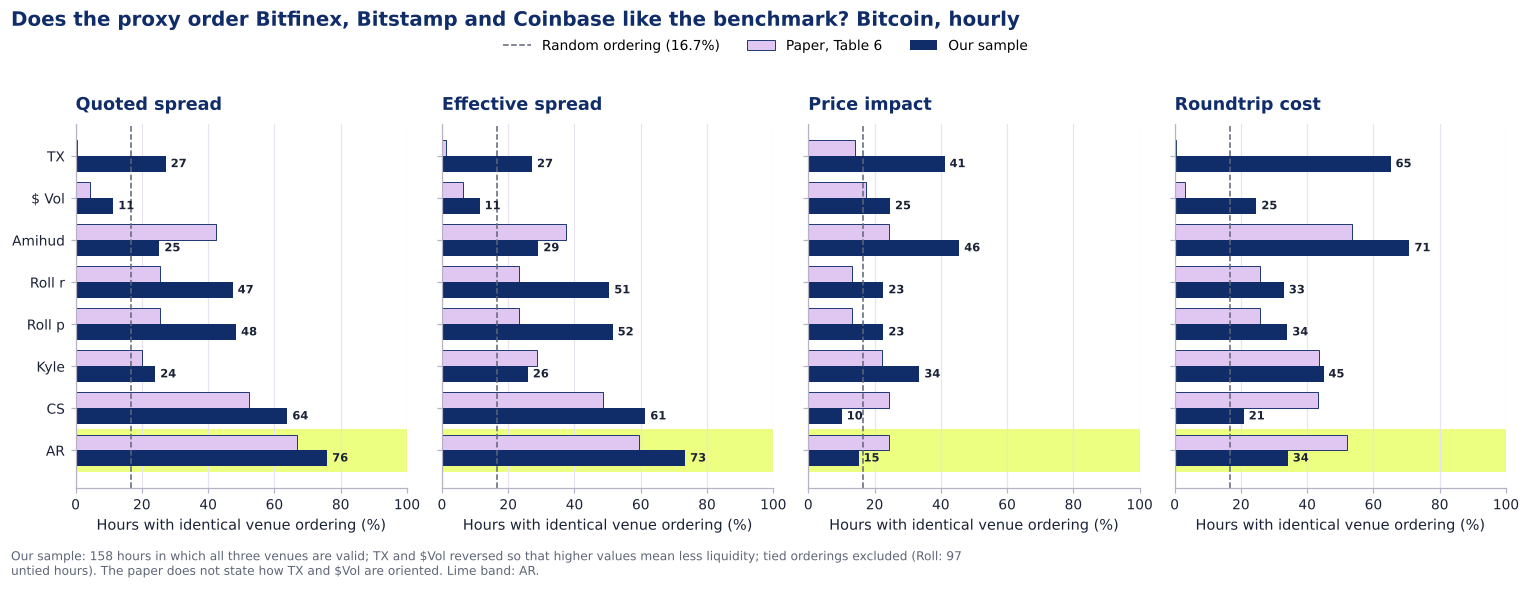

In [ ]:
PAPER_TABLE6_HOURLY = {
    "qs_bp": [0.57, 4.21, 42.32, 25.38, 25.41, 20.14, 52.48, 66.67],
    "es_bp": [1.12, 6.31, 37.32, 23.38, 23.39, 28.75, 48.56, 59.57],
    "pi_bp": [14.19, 17.35, 24.49, 13.23, 13.20, 22.14, 24.38, 24.27],
    "crt25_bp": [0.46, 3.16, 53.60, 25.79, 25.79, 43.63, 43.32, 52.17],
}

rank_btc = (p4_rankings.loc[p4_rankings["pair"].eq("BTCUSD")]
            .pivot(index="proxy", columns="benchmark", values="match_percent")
            .reindex(index=p4_proxy_columns, columns=p4_benchmark_columns))

fig, axes = plt.subplots(1, 4, figsize=(14, 5), sharey=True)
y = np.arange(len(p4_proxy_columns))[::-1]
h = 0.38
for ax, b, title in zip(axes, p4_benchmark_columns,
                        ["Quoted spread", "Effective spread", "Price impact", "Roundtrip cost"]):
    highlight_row(ax, y[p4_proxy_columns.index("ar")], 0.5)
    ax.barh(y + h / 2, PAPER_TABLE6_HOURLY[b], height=h, color=LAVENDER, edgecolor=NAVY, linewidth=0.6,
            label="Paper, Table 6", zorder=2)
    ax.barh(y - h / 2, rank_btc[b], height=h, color=NAVY, label="Our sample", zorder=2)
    for yi, v in zip(y, rank_btc[b]):
        ax.text(v + 1.5, yi - h / 2, f"{v:.0f}", va="center", fontsize=7.5, color=INK, fontweight="bold")
    ax.axvline(100 / 6, color=MUTED, ls="--", lw=1, label="Random ordering (16.7%)")
    ax.set_xlim(0, 100)
    ax.set_title(title)
    ax.set_xlabel("Hours with identical venue ordering (%)")
    ax.grid(axis="x")
axes[0].set_yticks(y, PROXY_LABELS)
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Does the proxy order Bitfinex, Bitstamp and Coinbase like the benchmark? Bitcoin, hourly",
             x=0.01, ha="left", color=NAVY)
fig.legend(handles, labels, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 0.95))
fig.tight_layout(rect=(0, 0, 1, 0.92))
n_common = int(p4_rankings.loc[p4_rankings["pair"].eq("BTCUSD"), "n_common_hours"].max())
add_note(fig, f"Our sample: {n_common} hours in which all three venues are valid; TX and $Vol reversed so that "
              "higher values mean less liquidity; tied orderings excluded (Roll: 97 untied hours). The paper does not "
              "state how TX and $Vol are oriented. Lime band: AR.")
fig.savefig(p4_figures_dir / "venue_rankings_paper_vs_ours.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

### 6.7 Summary: which findings of the paper replicate?

| Finding of Brauneis et al. (Bitcoin, hourly) | Paper | Our sample | Assessment |
|---|---|---|---|
| AR has the highest correlation with QS, ES and CRT | 0.76 / 0.84 / 0.71 | 0.752 / 0.802 / 0.685 | **Replicated** |
| AR has the highest correlation with PI | 0.59 | 0.577; \$Vol 0.604 and TX 0.563 similar | Partly replicated |
| CS ranks second | for QS, ES, PI | for QS, ES, CRT25 | Largely replicated |
| Amihud is uncorrelated with the benchmarks | −0.01 to 0.03 | −0.20 to 0.06 | **Replicated** |
| TX and \$Vol are positively related to costs | 0.35 to 0.72 | 0.41 to 0.60 | **Replicated**; mostly a volatility effect (Section 7.1) |
| Kyle tracks the roundtrip cost | 0.69 | 0.507 | Weaker in our sample |
| AR also best in high- and low-volatility hours | yes | yes for QS and ES; not for PI, tie with CS for CRT25 in volatile hours | Largely replicated (Section 7.3) |
| Correlations are higher in volatile hours for QS, ES, CRT | yes | no: AR's correlations are lower in volatile hours | **Not replicated** (Section 7.3) |
| Kyle and Amihud are most accurate in levels | yes | Amihud equals the zero baseline in both samples; AR is most accurate in ours | **Not replicated**; reinterpreted |
| AR reproduces the venue ranking best | 66.67% for QS | 75.9% for QS | **Replicated** |
| Benchmark levels (Table 3) | — | QS, CRT similar; ES, PI 2.4–8.5× higher | Partly comparable |

## 7. Robustness Checks and Our Research Extension

Section 6 shows that the paper's main ranking holds on independent data. This section asks how robust that result is and what it means. The first three checks examine whether the proxies' correlations with costs survive a control for volatility, how uncertain they are with only seven days, and whether they depend on market conditions. The last checks test whether a proxy calibrated on early dates measures costs on later dates, and whether the benchmark construction choices matter.

### 7.1 Volatility-controlled correlations

The simulation in Section 4.10 shows that a proxy and a cost measure can be correlated only because both follow volatility. For every market, proxy and benchmark we therefore compute the **partial Spearman correlation**: the proxy, the benchmark and hourly volatility (`vol_bp`) are ranked on the jointly observed hours, the linear association with ranked volatility is removed from the first two, and the residuals are correlated. A positive partial correlation means the proxy carries information about the cost beyond volatility. It measures a conditional association, not a causal effect.

In [ ]:
p4_partial_rows = []

for (venue, pair), market in p4_valid.groupby(["venue", "pair"]):
    for benchmark in p4_benchmark_columns:
        for proxy in p4_proxy_columns:

            sample = market[
                [proxy, benchmark, "vol_bp", "date_utc"]
            ].dropna()

            p4_partial_rows.append({
                "venue": venue,
                "pair": pair,
                "benchmark": benchmark,
                "proxy": proxy,
                "n_hours": len(sample),
                "n_dates": sample["date_utc"].nunique(),
                "spearman": sample[proxy].corr(
                    sample[benchmark],
                    method="spearman"
                ),
                "partial_spearman": partial_spearman(
                    sample[proxy],
                    sample[benchmark],
                    sample["vol_bp"]
                )
            })

p4_partial_correlations = pd.DataFrame(p4_partial_rows)

p4_partial_correlations.to_csv(
    p4_results_dir / "partial_correlations.csv", index=False
)
assert len(p4_correlations) == len(p4_partial_correlations) == 192

print("Partial Spearman correlations for AR")
display(p4_partial_correlations.loc[p4_partial_correlations["proxy"].eq("ar")].pivot(
    index=["venue", "pair", "n_hours"], columns="benchmark", values="partial_spearman"
).reindex(columns=p4_benchmark_columns).round(3))

print("Partial Spearman correlations for TX and $Vol")
display(p4_partial_correlations.loc[p4_partial_correlations["proxy"].isin(["tx_mean", "dollar_volume_mean"])].pivot(
    index=["proxy", "venue", "pair"], columns="benchmark", values="partial_spearman"
).reindex(columns=p4_benchmark_columns).round(3))

Partial Spearman correlations for AR


benchmark                qs_bp  es_bp  pi_bp  crt25_bp
venue    pair   n_hours                               
bitfinex BTCUSD 164      0.601  0.569 -0.026     0.372
         ETHUSD 122      0.408  0.601  0.117     0.223
bitstamp BTCUSD 167      0.611  0.671 -0.345     0.470
         ETHUSD 28       0.084  0.191 -0.001    -0.314
coinbase BTCUSD 163      0.492  0.514 -0.012     0.411
         ETHUSD 163      0.475  0.514  0.036     0.233

Partial Spearman correlations for TX and $Vol


benchmark                           qs_bp  es_bp  pi_bp  crt25_bp
proxy              venue    pair                                 
dollar_volume_mean bitfinex BTCUSD  0.204  0.078  0.034    -0.287
                            ETHUSD -0.150 -0.012 -0.116    -0.436
                   bitstamp BTCUSD -0.452 -0.370  0.188    -0.482
                            ETHUSD -0.169 -0.242 -0.052    -0.004
                   coinbase BTCUSD  0.262  0.219  0.021    -0.213
                            ETHUSD  0.065 -0.038 -0.036    -0.276
tx_mean            bitfinex BTCUSD -0.052 -0.156  0.038    -0.200
                            ETHUSD -0.190 -0.093 -0.116    -0.358
                   bitstamp BTCUSD -0.638 -0.507  0.039    -0.307
                            ETHUSD -0.228 -0.336 -0.008     0.111
                   coinbase BTCUSD  0.162  0.132 -0.201    -0.014
                            ETHUSD  0.089 -0.050 -0.150    -0.181

### 7.2 Uncertainty: date-block bootstrap

Hours within a day are not independent, so we resample whole days. We draw seven UTC dates with replacement 999 times, using the same draws for all markets, keep every hour of each drawn date, recompute the ranks and the partial correlations in each repetition, and report 2.5–97.5% percentile intervals. Undefined coefficients are excluded and counted in `n_boot_valid`. With only seven dates the intervals are approximate, and no multiple-comparison adjustment is applied.

The matrix formula for partial correlations used in the bootstrap is first checked against the rank-residual calculation of Section 7.1 for all 192 coefficients.

All 192 matrix coefficients match the rank-residual calculation.
Completed: bitfinex BTCUSD
Completed: bitfinex ETHUSD
Completed: bitstamp BTCUSD
Completed: bitstamp ETHUSD
Completed: coinbase BTCUSD
Completed: coinbase ETHUSD

Number of intervals: 192


,venue,pair,n_hours,partial_spearman,ci_low,ci_high,n_boot_valid
28,bitfinex,BTCUSD,164,0.601,0.439,0.709,999
60,bitfinex,ETHUSD,122,0.408,0.225,0.601,999
92,bitstamp,BTCUSD,167,0.611,0.323,0.808,999
124,bitstamp,ETHUSD,28,0.084,-0.119,0.415,976
156,coinbase,BTCUSD,163,0.492,0.355,0.670,999
188,coinbase,ETHUSD,163,0.475,0.260,0.651,999


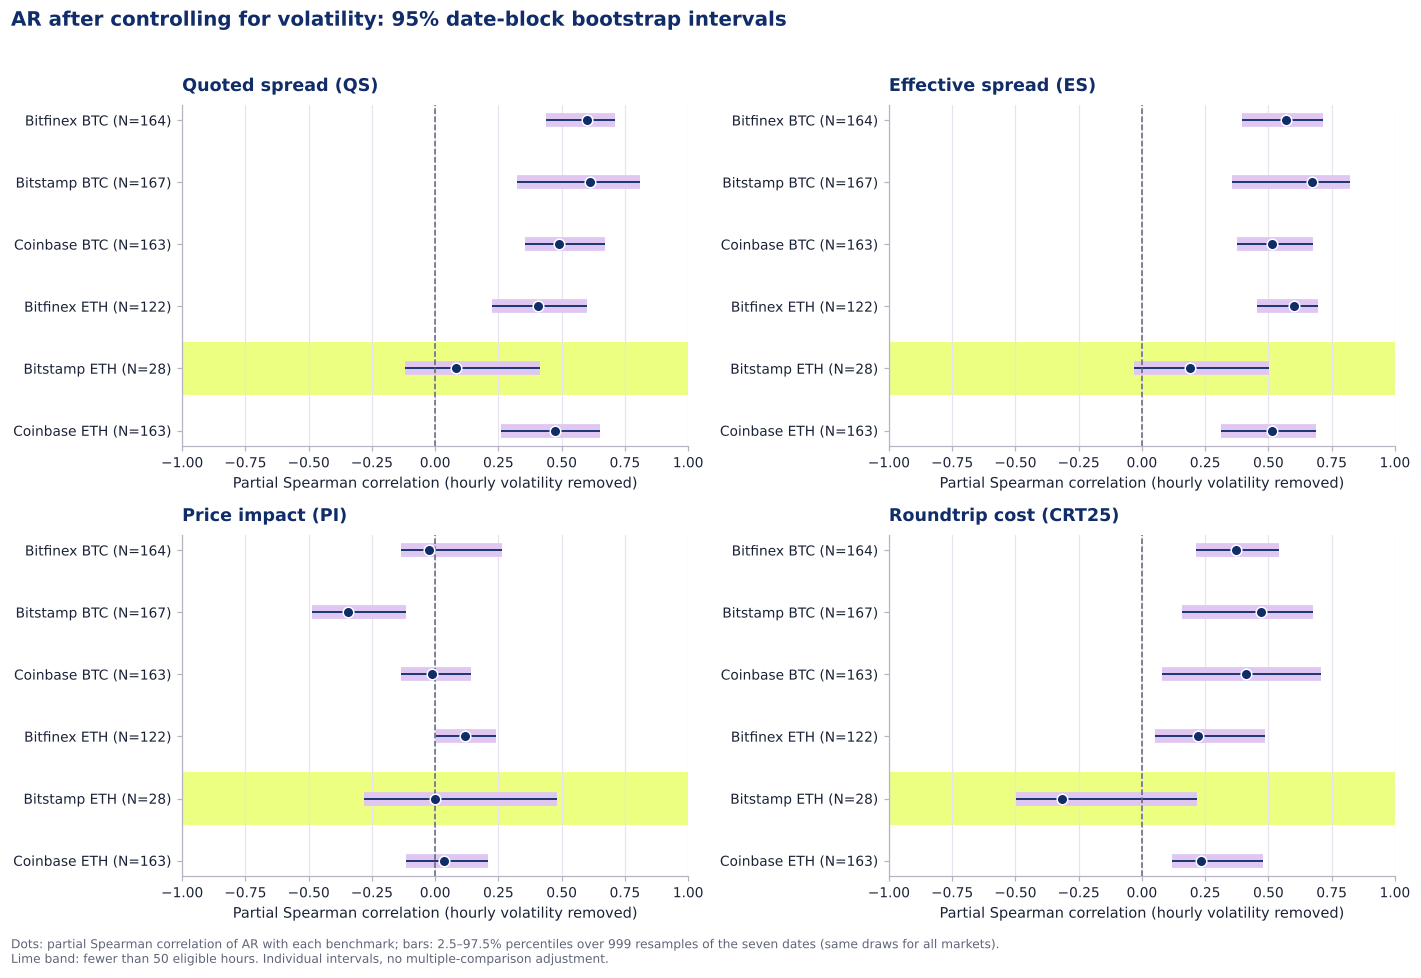

Partial-correlation tables and figure saved.


In [ ]:
def p4_partial_matrix(data):
    columns = (
        p4_proxy_columns
        + p4_benchmark_columns
        + ["vol_bp"]
    )

    if len(data) < 4:
        return pd.DataFrame(
            np.nan,
            index=p4_proxy_columns,
            columns=p4_benchmark_columns
        )

    assert data[columns].notna().all().all()

    correlations = data[columns].rank().corr()

    xy = correlations.loc[
        p4_proxy_columns, p4_benchmark_columns
    ].to_numpy()

    x_vol = correlations.loc[
        p4_proxy_columns, "vol_bp"
    ].to_numpy()[:, None]

    y_vol = correlations.loc[
        "vol_bp", p4_benchmark_columns
    ].to_numpy()[None, :]

    denominator = np.sqrt(
        np.clip(1 - x_vol**2, 0, None)
        * np.clip(1 - y_vol**2, 0, None)
    )

    values = np.divide(
        xy - x_vol * y_vol,
        denominator,
        out=np.full_like(xy, np.nan),
        where=denominator > 1e-12
    )

    return pd.DataFrame(
        np.clip(values, -1, 1),
        index=p4_proxy_columns,
        columns=p4_benchmark_columns
    )
for (venue, pair), market in p4_valid.groupby(["venue", "pair"]):
    previous = p4_partial_correlations.loc[
        p4_partial_correlations["venue"].eq(venue)
        & p4_partial_correlations["pair"].eq(pair)
    ].pivot(index="proxy", columns="benchmark", values="partial_spearman").reindex(
        index=p4_proxy_columns, columns=p4_benchmark_columns
    )
    assert np.allclose(p4_partial_matrix(market), previous, atol=1e-10, equal_nan=True)
print("All 192 matrix coefficients match the rank-residual calculation.")


p4_dates = sorted(p4_valid["date_utc"].unique())
p4_rng = np.random.default_rng(p4_seed)

p4_date_draws = p4_rng.choice(
    p4_dates,
    size=(p4_boot_repetitions, len(p4_dates)),
    replace=True
)

p4_bootstrap_samples = {}
p4_interval_rows = []

for (venue, pair), market in p4_valid.groupby(["venue", "pair"]):

    day_blocks = {
        date: market.loc[market["date_utc"] == date]
        for date in p4_dates
    }

    matrices = []

    for selected_dates in p4_date_draws:
        sample = pd.concat(
            [day_blocks[date] for date in selected_dates],
            ignore_index=True
        )

        matrices.append(
            p4_partial_matrix(sample).to_numpy()
        )

    matrices = np.stack(matrices)
    p4_bootstrap_samples[(venue, pair)] = matrices

    original = p4_partial_matrix(market)

    for i, proxy in enumerate(p4_proxy_columns):
        for j, benchmark in enumerate(p4_benchmark_columns):

            values = matrices[:, i, j]
            values = values[np.isfinite(values)]

            if len(values) > 0:
                lower, upper = np.quantile(
                    values, [0.025, 0.975]
                )
            else:
                lower, upper = np.nan, np.nan

            p4_interval_rows.append({
                "venue": venue,
                "pair": pair,
                "proxy": proxy,
                "benchmark": benchmark,
                "n_hours": len(market),
                "n_dates": market["date_utc"].nunique(),
                "partial_spearman": original.loc[
                    proxy, benchmark
                ],
                "ci_low": lower,
                "ci_high": upper,
                "n_boot_valid": len(values)
            })

    print("Completed:", venue, pair)

p4_partial_intervals = pd.DataFrame(p4_interval_rows)

print("\nNumber of intervals:", len(p4_partial_intervals))

display(
    p4_partial_intervals.loc[
        (p4_partial_intervals["proxy"] == "ar")
        & (p4_partial_intervals["benchmark"] == "qs_bp"),
        [
            "venue", "pair", "n_hours",
            "partial_spearman", "ci_low",
            "ci_high", "n_boot_valid"
        ]
    ].round(3)
)


p4_partial_intervals.to_csv(
    p4_results_dir / "partial_correlation_intervals.csv", index=False
)


benchmark_titles = {
    "qs_bp": "Quoted spread (QS)",
    "es_bp": "Effective spread (ES)",
    "pi_bp": "Price impact (PI)",
    "crt25_bp": "Roundtrip cost (CRT25)"
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8.6), sharex=True)

for ax, benchmark in zip(axes.flat, p4_benchmark_columns):
    sub = p4_partial_intervals.loc[
        (p4_partial_intervals["proxy"] == "ar")
        & (p4_partial_intervals["benchmark"] == benchmark)
    ].sort_values(["pair", "venue"])
    positions = np.arange(len(sub))
    labels = [f"{row.venue.title()} {row.pair[:3]} (N={row.n_hours})" for row in sub.itertuples()]
    for pos in positions[sub["n_hours"].to_numpy() < 50]:
        highlight_row(ax, pos, 0.42)
    ax.hlines(positions, sub["ci_low"], sub["ci_high"], color=LAVENDER, linewidth=9, zorder=1)
    ax.hlines(positions, sub["ci_low"], sub["ci_high"], color=NAVY, linewidth=1.2, zorder=2)
    ax.scatter(sub["partial_spearman"], positions, s=48, color=NAVY, edgecolor="white", linewidth=1, zorder=3)
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xlim(-1, 1)
    ax.set_title(benchmark_titles[benchmark])
    ax.set_xlabel("Partial Spearman correlation (hourly volatility removed)")
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="x")

fig.suptitle("AR after controlling for volatility: 95% date-block bootstrap intervals",
             x=0.01, ha="left", color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.965))
add_note(fig, "Dots: partial Spearman correlation of AR with each benchmark; bars: 2.5–97.5% percentiles over 999 "
              "resamples of the seven dates (same draws for all markets). Lime band: fewer than 50 eligible hours. "
              "Individual intervals, no multiple-comparison adjustment.")

fig.savefig(
    p4_figures_dir / "ar_partial_correlation_intervals.png",
    dpi=SAVE_DPI,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)
print("Partial-correlation tables and figure saved.")

### 7.3 Market conditions: return, volatility and volume regimes

As in the paper's Figures 5–7, we split each market's valid hours into terciles of hourly volatility, of the signed mean minute return and of total hourly USD volume, and compare ordinary correlations in the lowest and highest tercile (the middle tercile is excluded). Thresholds are set per market on the whole sample; these are descriptive splits, not thresholds fitted for a holdout test. "Low" and "high" returns refer to signed returns, not to the size of price movements. Mean correlations require a defined coefficient at all three venues.

In [ ]:
def p4_compare_regimes(data, split_variable):
    rows = []

    for (venue, pair), market in data.groupby(["venue", "pair"]):

        low_cutoff, high_cutoff = (
            market[split_variable].quantile([1/3, 2/3])
        )

        regimes = {
            "low": market.loc[
                market[split_variable] <= low_cutoff
            ],
            "high": market.loc[
                market[split_variable] >= high_cutoff
            ]
        }

        for regime, subset in regimes.items():
            for benchmark in p4_benchmark_columns:
                for proxy in p4_proxy_columns:

                    sample = subset[
                        [proxy, benchmark, "date_utc"]
                    ].dropna()

                    rows.append({
                        "venue": venue,
                        "pair": pair,
                        "split_variable": split_variable,
                        "regime": regime,
                        "low_cutoff": low_cutoff,
                        "high_cutoff": high_cutoff,
                        "benchmark": benchmark,
                        "proxy": proxy,
                        "n_hours": len(sample),
                        "n_dates": sample["date_utc"].nunique(),
                        "pearson": sample[proxy].corr(
                            sample[benchmark]
                        ),
                        "spearman": sample[proxy].corr(
                            sample[benchmark],
                            method="spearman"
                        )
                    })

    return pd.DataFrame(rows)

p4_volatility_results = p4_compare_regimes(p4_valid, "vol_bp")
p4_valid["hourly_dollar_volume"] = (
    p4_valid["dollar_volume_mean"]
    * p4_valid["valid_trade_minutes"]
)

p4_return_results = p4_compare_regimes(
    p4_valid,
    "mean_ret_bp"
)

p4_volume_results = p4_compare_regimes(
    p4_valid,
    "hourly_dollar_volume"
)

p4_regime_results = pd.concat(
    [
        p4_volatility_results,
        p4_return_results,
        p4_volume_results
    ],
    ignore_index=True
)

p4_regime_results.to_csv(
    p4_results_dir / "regime_correlations.csv",
    index=False
)

p4_regime_means = (
    p4_regime_results
    .groupby(
        ["pair", "split_variable", "regime", "benchmark", "proxy"],
        as_index=False
    )
    .agg(
        pearson=("pearson", "mean"),
        spearman=("spearman", "mean"),
        n_venues_pearson=("pearson", "count"),
        n_venues_spearman=("spearman", "count"),
        n_hours_total=("n_hours", "sum"),
        n_hours_min=("n_hours", "min")
    )
)

p4_regime_means.loc[
    p4_regime_means["n_venues_pearson"] < 3,
    "pearson"
] = np.nan

p4_regime_means.loc[
    p4_regime_means["n_venues_spearman"] < 3,
    "spearman"
] = np.nan

p4_regime_means.to_csv(
    p4_results_dir / "regime_correlations_mean_across_venues.csv",
    index=False
)

p4_btc_volatility = p4_regime_means.loc[
    (p4_regime_means["pair"] == "BTCUSD")
    & (p4_regime_means["split_variable"] == "vol_bp")
]

column_order = pd.MultiIndex.from_product(
    [p4_benchmark_columns, ["low", "high"]],
    names=["benchmark", "regime"]
)

print("BTC: mean Pearson correlations by volatility regime")

display(
    p4_btc_volatility.pivot(
        index="proxy",
        columns=["benchmark", "regime"],
        values="pearson"
    ).reindex(
        index=p4_proxy_columns,
        columns=column_order
    ).round(3)
)

p4_regime_thresholds = p4_regime_results[
    ["venue", "pair", "split_variable", "low_cutoff", "high_cutoff"]
].drop_duplicates()
p4_regime_thresholds.to_csv(p4_results_dir / "regime_thresholds.csv", index=False)
assert len(p4_regime_results) == 1152
volume_check = p4_valid[p4_keys + ["hourly_dollar_volume"]].merge(
    p4_hourly[p4_keys + ["dollar_volume"]], on=p4_keys, validate="one_to_one"
)
assert np.allclose(volume_check["hourly_dollar_volume"], volume_check["dollar_volume"])
print("Regime comparisons:", len(p4_regime_results))

BTC: mean Pearson correlations by volatility regime


benchmark           qs_bp         es_bp         pi_bp        crt25_bp       
regime                low   high    low   high    low   high      low   high
proxy                                                                       
tx_mean            -0.213  0.285 -0.224  0.370  0.174  0.366   -0.096  0.385
dollar_volume_mean -0.088  0.331 -0.146  0.420  0.193  0.464   -0.303  0.356
amihud              0.376 -0.113  0.444 -0.177  0.069 -0.240    0.305 -0.059
roll_return         0.177  0.073  0.177 -0.017 -0.013  0.028    0.156 -0.004
roll_price          0.197  0.103  0.189  0.030 -0.011  0.075    0.125  0.053
kyle                0.220  0.027  0.298  0.033  0.201  0.013    0.513  0.189
cs                  0.672  0.487  0.708  0.562  0.027  0.403    0.534  0.572
ar                  0.704  0.598  0.739  0.649  0.133  0.451    0.591  0.568

Regime comparisons: 1152


The figure compares the volatility split for Bitcoin with the paper's Figure 6. Each line connects a proxy's mean correlation in low-volatility hours (open marker) with its correlation in high-volatility hours (filled marker).

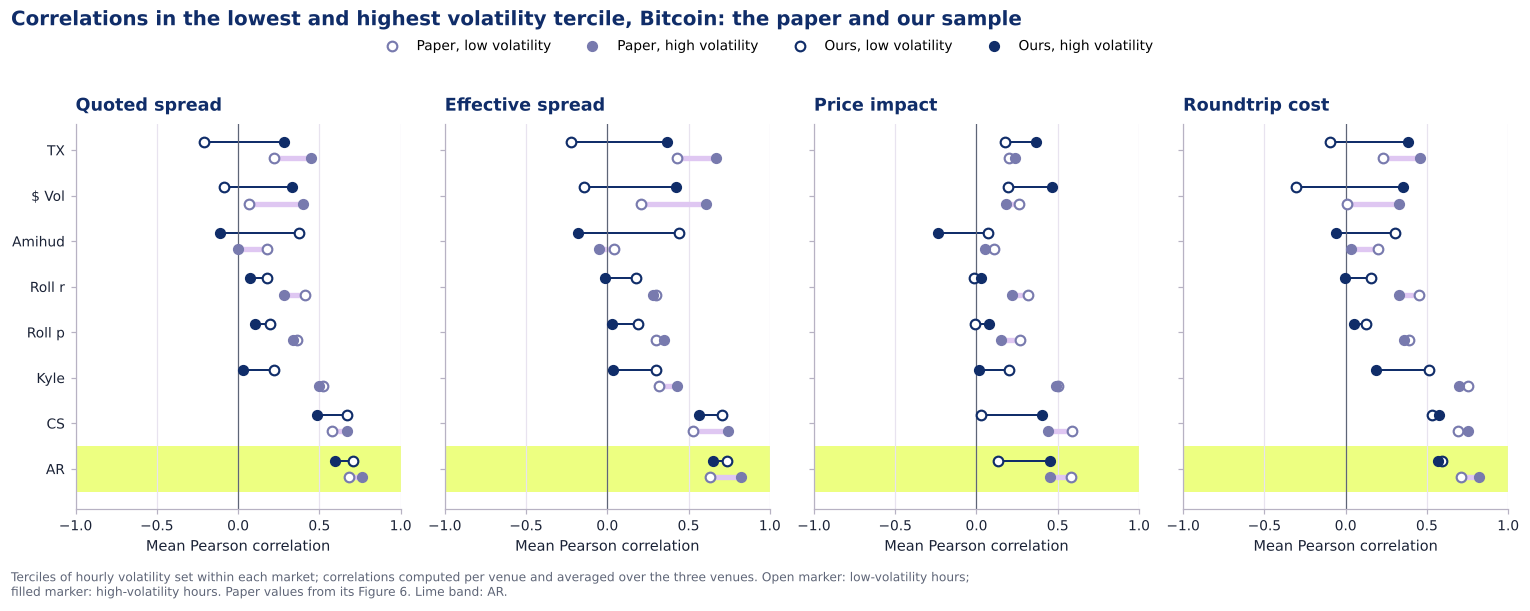

Bitcoin: mean Pearson correlations of AR and CS in the low and high tercile of each split


QS            ES            PI         CRT25       
                              low   high    low   high    low   high    low   high
proxy split                                                                       
ar    vol_bp                0.704  0.598  0.739  0.649  0.133  0.451  0.591  0.568
      mean_ret_bp           0.729  0.747  0.785  0.796  0.574  0.641  0.685  0.682
      hourly_dollar_volume  0.573  0.700  0.628  0.756  0.235  0.591  0.645  0.708
cs    vol_bp                0.672  0.487  0.708  0.562  0.027  0.403  0.534  0.572
      mean_ret_bp           0.640  0.678  0.708  0.752  0.508  0.587  0.649  0.645
      hourly_dollar_volume  0.483  0.648  0.535  0.725  0.038  0.538  0.537  0.714

In [ ]:
PAPER_FIG6_BTC = {
    "high": {"qs_bp": [0.45, 0.40, 0.00, 0.28, 0.34, 0.50, 0.67, 0.76],
             "es_bp": [0.67, 0.61, -0.05, 0.28, 0.35, 0.43, 0.74, 0.82],
             "pi_bp": [0.24, 0.18, 0.05, 0.22, 0.15, 0.49, 0.44, 0.45],
             "crt25_bp": [0.46, 0.33, 0.03, 0.33, 0.36, 0.70, 0.75, 0.82]},
    "low": {"qs_bp": [0.22, 0.07, 0.18, 0.41, 0.36, 0.52, 0.58, 0.68],
            "es_bp": [0.43, 0.21, 0.04, 0.30, 0.30, 0.32, 0.53, 0.63],
            "pi_bp": [0.20, 0.26, 0.11, 0.32, 0.27, 0.50, 0.59, 0.58],
            "crt25_bp": [0.23, 0.01, 0.20, 0.45, 0.39, 0.75, 0.69, 0.71]},
}

btc_regimes = p4_regime_means.loc[p4_regime_means["pair"].eq("BTCUSD")]
ours_vol = {regime: (btc_regimes.loc[btc_regimes["split_variable"].eq("vol_bp") & btc_regimes["regime"].eq(regime)]
                     .pivot(index="proxy", columns="benchmark", values="pearson")
                     .reindex(index=p4_proxy_columns, columns=p4_benchmark_columns))
            for regime in ("low", "high")}

fig, axes = plt.subplots(1, 4, figsize=(14, 5.2), sharey=True)
y = np.arange(len(p4_proxy_columns))[::-1]
off = 0.18
for ax, b, title in zip(axes, p4_benchmark_columns,
                        ["Quoted spread", "Effective spread", "Price impact", "Roundtrip cost"]):
    highlight_row(ax, y[p4_proxy_columns.index("ar")], 0.5)
    p_low, p_high = np.array(PAPER_FIG6_BTC["low"][b]), np.array(PAPER_FIG6_BTC["high"][b])
    o_low, o_high = ours_vol["low"][b].to_numpy(), ours_vol["high"][b].to_numpy()
    ax.hlines(y - off, p_low, p_high, color=LAVENDER, lw=3.5, zorder=1)
    ax.scatter(p_low, y - off, s=40, facecolor="white", edgecolor=NAVY_MID, linewidth=1.4, zorder=3,
               label="Paper, low volatility")
    ax.scatter(p_high, y - off, s=40, color=NAVY_MID, zorder=3, label="Paper, high volatility")
    ax.hlines(y + off, o_low, o_high, color=NAVY, lw=1.3, zorder=1)
    ax.scatter(o_low, y + off, s=40, facecolor="white", edgecolor=NAVY, linewidth=1.4, zorder=4,
               label="Ours, low volatility")
    ax.scatter(o_high, y + off, s=40, color=NAVY, zorder=4, label="Ours, high volatility")
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_xlim(-1, 1)
    ax.set_title(title)
    ax.set_xlabel("Mean Pearson correlation")
    ax.grid(axis="x")
axes[0].set_yticks(y, PROXY_LABELS)
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Correlations in the lowest and highest volatility tercile, Bitcoin: the paper and our sample",
             x=0.01, ha="left", color=NAVY)
fig.legend(handles, labels, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 0.95))
fig.tight_layout(rect=(0, 0, 1, 0.92))
add_note(fig, "Terciles of hourly volatility set within each market; correlations computed per venue and averaged "
              "over the three venues. Open marker: low-volatility hours; filled marker: high-volatility hours. "
              "Paper values from its Figure 6. Lime band: AR.")
fig.savefig(p4_figures_dir / "volatility_regimes_paper_vs_ours.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()

regime_rows = []
for proxy in ["ar", "cs"]:
    for split in ["vol_bp", "mean_ret_bp", "hourly_dollar_volume"]:
        sub = btc_regimes.loc[btc_regimes["proxy"].eq(proxy) & btc_regimes["split_variable"].eq(split)]
        row = {"proxy": proxy, "split": split}
        for b in p4_benchmark_columns:
            for regime in ("low", "high"):
                row[(short_names[b], regime)] = sub.loc[sub["benchmark"].eq(b) & sub["regime"].eq(regime),
                                                        "pearson"].item()
        regime_rows.append(row)
regime_summary = pd.DataFrame(regime_rows).set_index(["proxy", "split"])
regime_summary.columns = pd.MultiIndex.from_tuples(regime_summary.columns)
print("Bitcoin: mean Pearson correlations of AR and CS in the low and high tercile of each split")
display(regime_summary.round(3))

### 7.4 Temporal holdout: calibrating on early dates, testing on later dates

Raw proxies are biased in levels (Section 6.5), so a practitioner would calibrate them first. We test whether such a calibration carries over to later dates. For each market and benchmark we fit, on the training dates 1 June–1 October 2019 only, an affine regression of the benchmark on one proxy, standardized with its training mean and standard deviation, and evaluate it on 1 November and 1 December 2019. All eight calibrated proxies are evaluated; no winner is selected on the test set. Calibrated QS, ES and CRT25 estimates are clipped at zero (these costs cannot be negative); PI predictions remain signed. The comparison also includes the five uncalibrated proxies and two baselines, zero and the training median, on identical test hours. This tests contemporaneous cost measurement on later dates, not a forecast of next-hour costs. Bitstamp ETH has a single test hour; it remains in the tables but is excluded from the chart and from general statements.

In [ ]:
p4_cutoff_date = "2019-11-01"

p4_valid["split"] = np.where(
    p4_valid["date_utc"] < p4_cutoff_date,
    "train",
    "test"
)

p4_train = p4_valid.loc[
    p4_valid["split"] == "train"
].copy()

p4_test = p4_valid.loc[
    p4_valid["split"] == "test"
].copy()

p4_split_counts = (
    p4_valid.groupby(["venue", "pair", "split"])
    .size()
    .unstack("split", fill_value=0)
    .reindex(columns=["train", "test"])
    .reset_index()
)

p4_split_counts.to_csv(
    p4_results_dir / "historical_split_counts.csv",
    index=False
)

print("Training dates:", sorted(p4_train["date_utc"].unique()))
print("Test dates:", sorted(p4_test["date_utc"].unique()))

display(p4_split_counts)

def p4_fit_calibration(train, proxy, benchmark):
    x = train[proxy].to_numpy()
    y = train[benchmark].to_numpy()

    center = x.mean()
    scale = x.std()

    if scale == 0:
        scale = 1.0

    design = np.column_stack([
        np.ones(len(x)),
        (x - center) / scale
    ])

    intercept, slope = np.linalg.lstsq(
        design, y, rcond=None
    )[0]

    return center, scale, intercept, slope


p4_holdout_rows = []
p4_model_rows = []
p4_prediction_frames = []

for (venue, pair), market in p4_valid.groupby(["venue", "pair"]):
    for benchmark in p4_benchmark_columns:

        sample = market.dropna(
            subset=p4_proxy_columns + [benchmark]
        )

        train = sample.loc[sample["split"] == "train"]
        test = sample.loc[sample["split"] == "test"]

        train_median = train[benchmark].median()

        predictions = {
            "zero": np.zeros(len(test)),
            "train_median": np.full(len(test), train_median)
        }

        for method, (column, multiplier) in p4_direct_specs.items():
            predictions[f"direct_{method}"] = (
                test[column].to_numpy() * multiplier
            )

        for proxy in p4_proxy_columns:
            center, scale, intercept, slope = (
                p4_fit_calibration(train, proxy, benchmark)
            )

            prediction = (
                intercept
                + slope * (test[proxy].to_numpy() - center) / scale
            )

            clip_zero = benchmark in [
                "qs_bp", "es_bp", "crt25_bp"
            ]

            if clip_zero:
                prediction = np.maximum(prediction, 0)

            predictions[f"calibrated_{proxy}"] = prediction

            p4_model_rows.append({
                "venue": venue,
                "pair": pair,
                "benchmark": benchmark,
                "proxy": proxy,
                "center_train": center,
                "scale_train": scale,
                "intercept": intercept,
                "slope": slope,
                "clip_zero": clip_zero,
                "n_train": len(train),
                "train_last_date": train["date_utc"].max(),
                "test_first_date": test["date_utc"].min()
            })

        baseline_mae, baseline_rmse = p4_errors(
            test[benchmark],
            predictions["train_median"]
        )

        for method, prediction in predictions.items():
            mae, rmse = p4_errors(test[benchmark], prediction)

            p4_holdout_rows.append({
                "venue": venue,
                "pair": pair,
                "benchmark": benchmark,
                "method": method,
                "n_train": len(train),
                "n_test": len(test),
                "n_test_dates": test["date_utc"].nunique(),
                "mae_bp": mae,
                "rmse_bp": rmse,
                "mae_skill": (
                    1 - mae / baseline_mae
                    if baseline_mae > 0 else np.nan
                ),
                "rmse_skill": (
                    1 - rmse / baseline_rmse
                    if baseline_rmse > 0 else np.nan
                )
            })

            detail = test[p4_keys].copy()
            detail["benchmark"] = benchmark
            detail["method"] = method
            detail["actual_bp"] = test[benchmark].to_numpy()
            detail["prediction_bp"] = prediction

            p4_prediction_frames.append(detail)


p4_holdout_results = pd.DataFrame(p4_holdout_rows)
p4_calibration_parameters = pd.DataFrame(p4_model_rows)
p4_holdout_predictions = pd.concat(
    p4_prediction_frames, ignore_index=True
)

p4_holdout_results.to_csv(
    p4_results_dir / "historical_holdout_metrics.csv",
    index=False
)

p4_calibration_parameters.to_csv(
    p4_results_dir / "historical_calibration_parameters.csv",
    index=False
)

p4_holdout_predictions.to_csv(
    p4_results_dir / "historical_holdout_predictions_local_only.csv",
    index=False
)

print("Fitted calibrations:", len(p4_calibration_parameters))
print("Test comparisons:", len(p4_holdout_results))
print("QS: test MAE in basis points")

display(
    p4_holdout_results.loc[
        (p4_holdout_results["benchmark"] == "qs_bp")
        & p4_holdout_results["method"].isin([
            "train_median",
            "direct_ar",
            "calibrated_ar"
        ])
    ].pivot(
        index=["venue", "pair", "n_test"],
        columns="method",
        values="mae_bp"
    ).round(3)
)

Training dates: ['2019-06-01', '2019-07-01', '2019-08-01', '2019-09-01', '2019-10-01']
Test dates: ['2019-11-01', '2019-12-01']


split,venue,pair,train,test
0,bitfinex,BTCUSD,116,48
1,bitfinex,ETHUSD,102,20
2,bitstamp,BTCUSD,119,48
3,bitstamp,ETHUSD,27,1
4,coinbase,BTCUSD,115,48
5,coinbase,ETHUSD,115,48


Fitted calibrations: 192
Test comparisons: 360
QS: test MAE in basis points


method                  calibrated_ar  direct_ar  train_median
venue    pair   n_test                                        
bitfinex BTCUSD 48              0.301      1.258         0.463
         ETHUSD 20              0.349      1.302         0.422
bitstamp BTCUSD 48              1.486      2.140         1.840
         ETHUSD 1               3.192      4.118         4.011
coinbase BTCUSD 48              0.795      1.919         0.622
         ETHUSD 48              0.513      1.488         0.807

### 7.5 Holdout checks and calibration gains

The next cell verifies that all fitted parameters use only training dates, that RMSE is never below MAE and that the median baseline has zero skill against itself. It saves errors per test date and charts the **MAE skill** of calibrated AR, $1-\text{MAE}_{\text{model}}/\text{MAE}_{\text{training median}}$: positive values mean a smaller error than the training-median baseline.

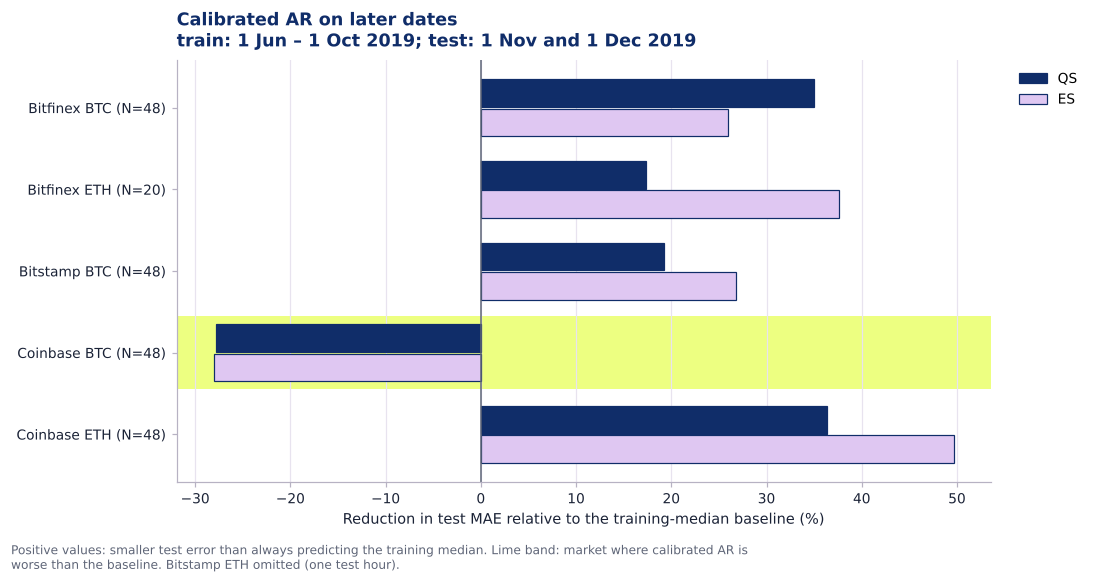

Validation checks passed.
Test errors by date and holdout figure saved.


benchmark               es_bp  qs_bp
venue    pair   n_test              
bitfinex BTCUSD 48       26.0   35.0
         ETHUSD 20       37.6   17.4
bitstamp BTCUSD 48       26.8   19.2
coinbase BTCUSD 48      -28.1  -27.8
         ETHUSD 48       49.6   36.4

In [ ]:
assert (
    p4_calibration_parameters["train_last_date"]
    < p4_cutoff_date
).all()

assert (
    p4_calibration_parameters["test_first_date"]
    >= p4_cutoff_date
).all()

assert (
    p4_holdout_results["rmse_bp"] + 1e-12
    >= p4_holdout_results["mae_bp"]
).all()

assert np.allclose(
    p4_holdout_results.loc[
        p4_holdout_results["method"] == "train_median",
        "mae_skill"
    ],
    0
)

p4_daily_predictions = p4_holdout_predictions.copy()

error = (
    p4_daily_predictions["prediction_bp"]
    - p4_daily_predictions["actual_bp"]
)

p4_daily_predictions["absolute_error_bp"] = np.abs(error)
p4_daily_predictions["squared_error_bp2"] = error**2

p4_daily_metrics = (
    p4_daily_predictions
    .groupby(
        ["venue", "pair", "benchmark", "method", "date_utc"],
        as_index=False
    )
    .agg(
        n_hours=("actual_bp", "size"),
        mae_bp=("absolute_error_bp", "mean"),
        mse_bp2=("squared_error_bp2", "mean")
    )
)

p4_daily_metrics["rmse_bp"] = np.sqrt(
    p4_daily_metrics.pop("mse_bp2")
)

p4_daily_metrics.to_csv(
    p4_results_dir / "historical_holdout_by_date.csv",
    index=False
)
p4_ar_test = p4_holdout_results.loc[
    (p4_holdout_results["method"] == "calibrated_ar")
    & p4_holdout_results["benchmark"].isin(["qs_bp", "es_bp"])
    & ~(
        (p4_holdout_results["venue"] == "bitstamp")
        & (p4_holdout_results["pair"] == "ETHUSD")
    )
]

p4_ar_gain = (
    p4_ar_test.pivot(
        index=["venue", "pair", "n_test"],
        columns="benchmark",
        values="mae_skill"
    ) * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(p4_ar_gain))

for pos in positions[(p4_ar_gain < 0).any(axis=1).to_numpy()]:
    highlight_row(ax, pos)

for offset, benchmark, label, face in [
    (-0.18, "qs_bp", "QS", NAVY),
    (0.18, "es_bp", "ES", LAVENDER)
]:
    ax.barh(
        positions + offset,
        p4_ar_gain[benchmark],
        height=0.34,
        label=label,
        color=face,
        edgecolor=NAVY,
        linewidth=0.8,
        zorder=2
    )

labels = [
    f"{venue.title()} {pair[:3]} (N={n_test})"
    for venue, pair, n_test in p4_ar_gain.index
]

ax.set_yticks(positions, labels)
ax.invert_yaxis()
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Reduction in test MAE relative to the training-median baseline (%)")
ax.set_title(
    "Calibrated AR on later dates\n"
    "train: 1 Jun – 1 Oct 2019; test: 1 Nov and 1 Dec 2019"
)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(axis="x")
fig.tight_layout()
add_note(fig, "Positive values: smaller test error than always predicting the training median. "
              "Lime band: market where calibrated AR is worse than the baseline. "
              "Bitstamp ETH omitted (one test hour).", width=120)

fig.savefig(
    p4_figures_dir / "historical_holdout_mae_gain.png",
    dpi=SAVE_DPI,
    bbox_inches="tight"
)

plt.show()

print("Validation checks passed.")
print("Test errors by date and holdout figure saved.")
display(p4_ar_gain.round(1))

p4_ar_gain.reset_index().to_csv(
    p4_results_dir / "historical_ar_mae_gain_percent.csv", index=False
)
plt.close(fig)

In [ ]:
larger_markets = ~(p4_holdout_results["venue"].eq("bitstamp") & p4_holdout_results["pair"].eq("ETHUSD"))
calibrated = p4_holdout_results.loc[larger_markets & p4_holdout_results["method"].str.startswith("calibrated_")]
print("Number of the five larger markets in which a calibrated proxy has a lower test MAE than the training median")
display((calibrated["mae_skill"] > 0)
        .groupby([calibrated["method"].str.replace("calibrated_", "", regex=False), calibrated["benchmark"]])
        .sum().unstack().reindex(index=p4_proxy_columns, columns=p4_benchmark_columns))
print("Coinbase BTC, QS: test MAE (bp) and skill by method")
display(p4_holdout_results.loc[p4_holdout_results["venue"].eq("coinbase") & p4_holdout_results["pair"].eq("BTCUSD")
                               & p4_holdout_results["benchmark"].eq("qs_bp"), ["method", "mae_bp", "mae_skill"]]
        .sort_values("mae_bp").set_index("method").round(3))

Number of the five larger markets in which a calibrated proxy has a lower test MAE than the training median


benchmark,qs_bp,es_bp,pi_bp,crt25_bp
method,,,,
tx_mean,4,3,3,2
dollar_volume_mean,4,3,3,1
amihud,3,1,3,4
roll_return,3,3,5,3
roll_price,3,3,5,2
kyle,1,1,2,3
cs,3,3,2,2
ar,4,4,3,3


Coinbase BTC, QS: test MAE (bp) and skill by method


,mae_bp,mae_skill
method,,
direct_kyle_x10000,0.334,0.464
direct_amihud_x10000,0.549,0.118
zero,0.549,0.117
train_median,0.622,0.000
calibrated_dollar_volume_mean,0.667,-0.073
calibrated_cs,0.710,-0.141
calibrated_ar,0.795,-0.278
calibrated_tx_mean,0.823,-0.324
direct_cs,0.979,-0.574


### 7.6 Sensitivity of the benchmarks to the quote-age limit


In [ ]:
if bench30 is not None:
    pair60 = bench[eligible].set_index(P3_KEYS)
    pair30 = bench30[eligible].set_index(P3_KEYS)
    rows = []
    for (venue, pair), g60 in pair60.groupby(level=["venue", "pair"]):
        g30 = pair30.loc[g60.index]
        for col, n_col in (("qs_bp", "n_quote_grid"), ("es_bp", "n_es_matches"), ("es_signed_bp", "n_signed_matches"),
                           ("pi_bp", "n_pi_matches"), ("crt25_bp", "n_crt_filled")):
            both = g60[col].notna() & g30[col].notna()
            rows.append({"venue": venue, "pair": pair, "benchmark": col,
                         "mean_60s": g60[col].mean(), "mean_30s": g30[col].mean(),
                         "hours_60s": int(g60[col].notna().sum()), "hours_30s": int(g30[col].notna().sum()),
                         "obs_60s": int(g60[n_col].sum()), "obs_30s": int(g30[n_col].sum()),
                         "spearman_60_vs_30": g60.loc[both, col].corr(g30.loc[both, col], method="spearman")})
    sens = pd.DataFrame(rows)
    sens["obs_lost_share"] = 1 - sens["obs_30s"] / sens["obs_60s"]
    sens.to_csv(OUT / "participant3_sensitivity_age30_vs_60.csv", index=False)
    print(sens.round(3).to_string(index=False))
else:
    print("30 s sensitivity not available: upload hourly_benchmarks_age30_local_only.csv "
          "(FAST_MODE) or run the full mode.")

   venue   pair    benchmark  mean_60s  mean_30s  hours_60s  hours_30s  obs_60s  obs_30s  spearman_60_vs_30  obs_lost_share
bitfinex BTCUSD        qs_bp     0.725     0.725        164        164    59014    58984              1.000           0.001
bitfinex BTCUSD        es_bp     0.939     0.939        164        164    42779    42770              1.000           0.000
bitfinex BTCUSD es_signed_bp     0.627     0.627        164        164    42779    42770              1.000           0.000
bitfinex BTCUSD        pi_bp     0.656     0.656        164        164    42656    42647              1.000           0.000
bitfinex BTCUSD     crt25_bp     4.718     4.719        164        164    58715    58706              1.000           0.000
bitfinex ETHUSD        qs_bp     1.789     1.790        122        122    43898    43862              1.000           0.001
bitfinex ETHUSD        es_bp     2.353     2.353        122        122    21153    21145              1.000           0.000
bitfinex

In [ ]:
supplied_sensitivity = FAST_INPUTS / "participant3_sensitivity_age30_vs_60.csv" if FAST_MODE else None
if FAST_MODE and supplied_sensitivity.exists() and bench30 is not None:
    supplied = pd.read_csv(supplied_sensitivity)
    recomputed = pd.read_csv(OUT / "participant3_sensitivity_age30_vs_60.csv")
    key_cols = ["venue", "pair", "benchmark"]
    numeric = supplied.select_dtypes("number").columns
    assert supplied[key_cols].equals(recomputed[key_cols])
    assert np.allclose(supplied[numeric], recomputed[numeric], rtol=1e-9, atol=1e-12, equal_nan=True)
    print("The recomputed sensitivity table equals the supplied participant3_sensitivity_age30_vs_60.csv.")
else:
    print("No supplied sensitivity table to compare with.")

The recomputed sensitivity table equals the supplied participant3_sensitivity_age30_vs_60.csv.


### 7.7 Sensitivity of the partial correlations and order-book depth coverage

In [ ]:
p4_age30 = pd.read_csv(
    data_dir / "hourly_benchmarks_age30_local_only.csv"
)

p4_age30_valid = p4_age30.loc[
    p4_age30["passes_80pct_trade_coverage"] == True,
    p4_keys + p4_benchmark_columns
]

p4_age30_data = (
    p4_valid.drop(columns=p4_benchmark_columns)
    .merge(
        p4_age30_valid,
        on=p4_keys,
        how="outer",
        validate="one_to_one",
        indicator=True
    )
)

assert (p4_age30_data["_merge"] == "both").all()
p4_age30_data = p4_age30_data.drop(columns="_merge")

p4_reference = p4_partial_correlations.set_index(
    ["venue", "pair", "proxy", "benchmark"]
)

p4_age_rows = []

for (venue, pair), market in p4_age30_data.groupby(
    ["venue", "pair"]
):
    matrix30 = p4_partial_matrix(market)

    for proxy in p4_proxy_columns:
        for benchmark in p4_benchmark_columns:
            key = (venue, pair, proxy, benchmark)

            assert (
                len(market)
                == p4_reference.loc[key, "n_hours"]
            )

            value60 = p4_reference.loc[
                key, "partial_spearman"
            ]
            value30 = matrix30.loc[proxy, benchmark]

            p4_age_rows.append({
                "venue": venue,
                "pair": pair,
                "proxy": proxy,
                "benchmark": benchmark,
                "n_hours": len(market),
                "partial_60s": value60,
                "partial_30s": value30,
                "difference_30s_minus_60s": value30 - value60
            })

p4_age_sensitivity = pd.DataFrame(p4_age_rows)

p4_age_sensitivity.to_csv(
    p4_results_dir / "quote_age_sensitivity.csv",
    index=False
)

print(
    "Maximum absolute change in partial correlation:",
    round(
        p4_age_sensitivity[
            "difference_30s_minus_60s"
        ].abs().max(),
        4
    )
)

p4_depth_coverage = (
    p4_benchmarks.groupby(["venue", "pair"])[
        [
            "n_book_snapshots",
            "n_crt_filled",
            "n_crt_insufficient_depth"
        ]
    ]
    .sum()
    .reset_index()
)

p4_depth_coverage["coverage_percent"] = (
    100
    * p4_depth_coverage["n_crt_filled"]
    / p4_depth_coverage["n_book_snapshots"]
)

p4_depth_coverage.to_csv(
    p4_results_dir / "crt25_depth_coverage.csv",
    index=False
)

overall_coverage = (
    100
    * p4_depth_coverage["n_crt_filled"].sum()
    / p4_depth_coverage["n_book_snapshots"].sum()
)

print(
    "Overall CRT25 depth coverage:",
    round(overall_coverage, 3),
    "%"
)

print("CRT25 coverage across all recorded hours:")
display(p4_depth_coverage.round(3))

Maximum absolute change in partial correlation: 0.0244
Overall CRT25 depth coverage: 99.851 %
CRT25 coverage across all recorded hours:


,venue,pair,n_book_snapshots,n_crt_filled,n_crt_insufficient_depth,coverage_percent
0,bitfinex,BTCUSD,59394,59063,331,99.443
1,bitfinex,ETHUSD,59398,59385,13,99.978
2,bitstamp,BTCUSD,60473,60473,0,100.000
3,bitstamp,ETHUSD,60473,60471,2,99.997
4,coinbase,BTCUSD,60473,60285,188,99.689
5,coinbase,ETHUSD,60473,60470,3,99.995


The quote-age limit is immaterial: at most 0.5% of observations are lost, benchmark means change by at most 0.013 bp, the hourly series correlate at 0.996 or more, and no partial correlation changes by more than 0.024 (the largest change is for Bitstamp ETH with 28 hours). Twenty-five levels fill the roundtrip order on both sides in 99.85% of snapshots (lowest: Bitfinex BTC, 99.44%), so the restriction to 25 levels hardly binds at the paper's order sizes.

## 8. Discussion, Limitations, and Overall Conclusions

### 8.1 results and summary

**The paper's central result travels well.** On independent data from a later period, with a different collection method and a shallower order book, AR again tracks the time variation of quoted and effective spreads and of the roundtrip cost better than any other low-frequency proxy, and it again identifies the cheapest venue most often. The ordering of the eight proxies is close to the published one (rank correlation 0.98 for QS), although our coefficients are mostly somewhat lower (by 0.065 on average).

**Volatility is the common driver behind several of the paper's patterns.** Trading activity, spreads and high–low ranges all rise in volatile hours. Once ranked volatility is removed, the positive link between activity and costs that the paper calls surprising largely disappears or turns negative, while AR keeps a substantial partial correlation with the spreads. AR therefore measures more than volatility, but part of its raw correlation, and all of its correlation with price impact, is shared with volatility.

**Level accuracy needs a baseline.** The Amihud ratio's small level errors in the paper and in our data are exactly what a zero forecast achieves, because both the scaled ratio and the cost levels are small. Proxies that track liquidity well over time, such as AR, are biased upwards in levels at minute frequency, and the bias grows with volatility. A calibration on earlier data reduces level errors on later dates in most markets, but it fails when the level of costs shifts, as on Coinbase BTC.

**Price impact is the hardest benchmark.** No proxy tracks it after the volatility control, and none orders the venues by price impact reliably. Price impact reflects adverse selection after individual trades, which OHLCV data do not observe.

**Benchmark construction matters for levels, not for rankings.** Our QS and CRT25 levels are close to the paper's, but ES and PI are higher, probably because of the regular 10-second grid. Correlations, rankings and the partial correlations are nearly unchanged when the quote-age limit is halved.

### 8.4 Limitations
* **Independent data.** Tardis.dev recordings of WebSocket feeds instead of the authors' REST snapshots; a regular 10-second grid instead of irregular snapshots. This explains part of the level differences in ES and PI.
* **Order-book depth.** 25 instead of 50 levels; CRT25 is an approximation, even though 25 levels fill the order in 99.85% of snapshots.
* **Thin markets and gaps.** Bitstamp ETH has only 28 valid hours; 1 August 2019 has recording gaps on Bitfinex and in the Coinbase trade feed.
* **Scope.** Hourly frequency only; the paper's daily and 15-day frequencies, quantile dependence and principal-component composite are not replicated.
* **Interpretation of definitions.** The SSRN text leaves the ES and PI definitions and the units of Table 5 ambiguous (Section 2.6); our choices are documented, not confirmed by the authors.
* **Reproducibility in FAST_MODE.** ES, PI and CRT25 are loaded from the full run rather than recomputed; the full mode reproduces them from the raw data.

### References

* Brauneis, Alexander & Mestel, Roland & Riordan, Ryan & Theissen, Erik, 2021, <a href="https://ideas.repec.org/a/eee/jbfina/v124y2021ics0378426620303022.html">"<b>How to measure the liquidity of cryptocurrency markets?</b></a>," <a href="https://ideas.repec.org/s/eee/jbfina.html">Journal of Banking & Finance</a>, Elsevier, volume 124, issue C, DOI: 10.1016/j.jbankfin.2020.106041.
<br>

* Tardis.dev. Historical market data: downloadable CSV files and data types. https://docs.tardis.dev/downloadable-csv-files
